# 3-servo: identification

Run the README's one-pass identification on this servo's own stage 3 datasets, reduce each step the way a user's tool would reduce it, and grade every constant it gives against the same quantity from its long-form notebook. The notebook has no capture of its own. Each step of the pass is cut out of a dataset an earlier notebook already read, so where the two share rows the grade tests the reduction, and where they do not it tests the experiment.

## Purpose

A user with an unknown servo has one supply, no meter, no camera and no lock, and needs the constants stages 4 to 7 read. The README's `The one-pass identification` names the steps that are meant to give them. This notebook asks four things of that pass.

- What it reproduces. R0, V0, L, tau, Ke, the brush table, the floor, the breakaway and the dropout reference, each against the long-form notebook's number for the same quantity, with the gap in sigma.
- What it costs. The wall time as the sitting's runner paced it, the time with shorter rests, the motor revolutions and the heat it leaves.
- How well it repeats. The same steps at the open and the close of one sitting, and across three sittings.
- Where it holds. The gate each step needs, this servo's number for it and the rule that sets it on any servo.

The last section hands stages 4 to 7 the pass's constants in firmware units with brackets, beside the ones the pass does not read, quoted from their results.

## Procedure

The procedure is the README's `identification` section. No sitting ran for it. The stop chains, the low holds, the ladder's rungs on the pass's rail and the run-ups at the open and the close come from sitting `servo-1`, the bursts at the stop from a later sitting, all on the experiment image, so every drive is open loop. The brackets of sittings 6 and 7 enter only the repeatability.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The stop chains are `resistance/stop-1` (`chains.csv`), the bursts `inductance/stop-6` with `inductance/locked-4` and `inductance/wound-5` as the other seats (`g*/burst-K.csv`, `marks.csv`), the holds `ladder/low-1`, the rungs `ladder/capture-1` and the run-ups `run-up/runup-open-1` (`cycles.csv`). The brackets are the `ladder/ref-*` and `run-up/runup-*` sets of sittings 1, 6 and 7. The sitting manifests under `sittings/` give the rail and the board NTC before each sweep. Each sweep folder holds `sweep.csv`, one row per control tick, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

from oscnb import (boards, bursts, coast, cycles, figures, motors, results,
                   ripple, scales, servos, tel)
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
FS = BOARD.tick_hz                      # rows per second, the control tick
ARR = BOARD.pwm_arr                     # timer ticks per half PWM period
GEAR = SERVO.gear_ratio                 # motor revs per output rev, teeth
PER_REV = MOTOR.ripple_per_rev          # commutation events per motor rev
RPS = 2 * np.pi                         # rad/s per rev/s
RAIL_V = 5.0                            # V, the user's one supply
ALPHA_CU = 0.0039                       # 1/C, copper's coefficient
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"gear {GEAR:.4f}:1, {PER_REV} ripple events per motor rev, {FS} "
      f"rows/s, PWM period {2 * ARR} ticks; the pass's rail {RAIL_V} V")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
gear 308.0533:1, 6 ripple events per motor rev, 20000 rows/s, PWM period 2400 ticks; the pass's rail 5.0 V


## 1. The setup

### Earlier results carried in

The stage 1 scales turn counts into amps and volts. Three of their constants are board constants a user's tool may carry, the bridge's edge lags at 5 V, the brake loop's resistance between windows and the window scale k. The resistance result gives construction C's line on three rails and the lock, the locked R_term, the crest term g the meter confirmed and the type's spinning g. Inductance gives the lock's L and tau, the brake line it measured on the motor and its per-period dip. The ladder gives Ke, the floor and its brush tables, run-up J and the dropout rates, and the pot table its counts-to-degrees map. Steps, sag, friction and load are quoted in the cross-checks and the hand-off. Every long-form number below is read from those results, none typed.

In [3]:
SC = scales.load(BOARD)                 # stage 1: counts to amps and volts
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
LAD = results.read("3-servo", "ladder", pair=PAIR)
RUNUP = results.read("3-servo", "run-up", pair=PAIR)
STEPS = results.read("3-servo", "steps", pair=PAIR)
SAG = results.read("3-servo", "sag", pair=PAIR)
POT = results.read("3-servo", "pot-table", pair=PAIR)
FRICTION = results.read("3-servo", "friction", pair=PAIR)
LOAD = results.read("3-servo", "load", pair=PAIR)
# the pot table itself sits beside the pot-table result as a csv
POT_TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                        .with_suffix(".table.csv"))
SC.describe()

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end


In [4]:
EDGE_5V = SC.edge_ticks_at(RAIL_V)      # ticks, stage 1's edge lags at 5 V
R_BRAKE = SC.bridge_states["low_side_loop_ohm"]["value"]  # ohm, brake loop
K_WINDOW = SC.sample_timing["window_scale"]["value"]   # window's V/i scale
LAGS = SC.edge_lags()                   # ticks, stage 1's slow-decay edges
# the brake level the inductance notebook measured on the motor itself
BRAKE_MOTOR = (IND["brake_line_motor_intercept_mv"]["value"] * 1e-3,
               IND["brake_line_motor_slope_ohm"]["value"])
G_METER = RES["meter_g_ms"]             # mS, the crest term, the meter's
G_TYPE_SPIN = RES["g_type_spin_ms_quoted"]["value"]   # mS, mg90-b spinning
POT_NOM = SERVO.counts_per_deg_nominal  # counts/deg, the registry's
POT_MID = POT["pot_scale_counts_per_deg"]   # counts/deg, table mid travel
print(f"{SC.counts_per_a:.1f} counts/A, in-drive offset "
      f"{SC.drive_offset_counts:+.2f} counts, {SC.terminal_counts_per_v:.2f}"
      f" counts/V taps, {SC.rail_counts_per_v:.2f} counts/V rail")
print(f"edge lags at 5 V {EDGE_5V:.2f} ticks (on the motor "
      f"{IND['edge_area_ticks_motor']['value']:.1f}), brake loop "
      f"{R_BRAKE:.3f} ohm, window scale k {K_WINDOW:.4f}")
print(f"motor brake line {BRAKE_MOTOR[0] * 1e3:.1f} mV + "
      f"{BRAKE_MOTOR[1]:.3f} i; g {G_METER['value']:.3f} mS "
      f"[{G_METER['lo']:.2f}, {G_METER['hi']:.2f}], type spin "
      f"{G_TYPE_SPIN:.2f} mS")
print(f"pot nominal {POT_NOM} counts/deg, table mid travel "
      f"{POT_MID['value']:.3f}; rated {SERVO.rated_v} V, lap cap "
      f"{SERVO.lap_cap_a} A")

1135.0 counts/A, in-drive offset +5.26 counts, 248.37 counts/V taps, 247.54 counts/V rail
edge lags at 5 V 25.05 ticks (on the motor 26.5), brake loop 0.301 ohm, window scale k 1.0063
motor brake line 8.8 mV + 0.239 i; g 4.746 mS [4.52, 4.97], type spin 3.35 mS
pot nominal 19.8 counts/deg, table mid travel 18.913; rated 5.0 V, lap cap 0.45 A


In [5]:
R_LOCKED = RES["r_term_ohm"]            # ohm, six locked 100 % laps
R_LOCKED_SD = (R_LOCKED["value"]        # ohm, the laps' scatter
               * RES["r_term_lap_scatter_pct"]["value"] / 100)
I_LOCK = RES["r_term_amps"]["value"]    # A, the laps' current
R_C = RES["r_rails_c_ohm"]              # ohm, C's line, three rails + lock
V0_C = RES["v0_rails_c_v"]              # V, that line's offset
T0_LONG = RES["board_ntc_c_stop"]       # C, the NTC through the chains
L_LONG = IND["l_mh"]                    # mH, the lock, group medians
TAU_LONG = IND["tau_us"]                # us
R_BURST_LONG = IND["r_burst_ohm"]       # ohm, the window model's R
L_BY_SEAT = IND["l_mh_by_seat"]         # mH, by seat and duty
TAU_BY_SEAT = IND["tau_us_by_seat"]
KE_LONG = LAD["ke_mv_per_rev_s"]        # mV per rev/s, 108 coasts
KE_LONG_SE_PCT = LAD["ke_se_pct"]["value"]
KE_LONG_SD_PCT = LAD["ke_sd_pct"]["value"]
FLOOR_LONG = LAD["floor_v_effective"]   # V effective, three rails
J_LONG = RUNUP["j_kg_m2"]               # kg m2, rotor + train at the motor
print(f"R_term {R_LOCKED['value']:.4f} ohm (sd {R_LOCKED_SD:.4f}) at "
      f"{I_LOCK:.3f} A; C line {R_C['value']:.4f} [{R_C['lo']:.4f}, "
      f"{R_C['hi']:.4f}] ohm, V0 {V0_C['value']:+.4f} V")
print(f"L {L_LONG['value']:.4f} mH [{L_LONG['lo']:.3f}, "
      f"{L_LONG['hi']:.3f}], tau {TAU_LONG['value']:.1f} us, burst R "
      f"{R_BURST_LONG['value']:.4f} ohm")
print(f"Ke {KE_LONG['value']:.4f} mV per rev/s, se {KE_LONG_SE_PCT:.3f} %"
      f", sd {KE_LONG_SD_PCT:.2f} %; floor {FLOOR_LONG['value']:.3f} V "
      f"[{FLOOR_LONG['lo']:.3f}, {FLOOR_LONG['hi']:.3f}]; J "
      f"{J_LONG['value'] * 1e9:.3f}e-9 kg m2; T0 {T0_LONG['value']:.2f} C")

R_term 4.2189 ohm (sd 0.0105) at 0.767 A; C line 4.1766 [4.1704, 4.1827] ohm, V0 +0.0313 V
L 0.8198 mH [0.781, 0.874], tau 198.5 us, burst R 4.2172 ohm
Ke 7.2828 mV per rev/s, se 0.060 %, sd 0.63 %; floor 0.340 V [0.300, 0.399]; J 6.433e-9 kg m2; T0 26.03 C


### The sitting manifests

The runner read the pot, the board NTC and the rail before every sweep. A sweep's rail and its T0 are its probe's.

In [6]:
PATTERN = r"(.+?): pos (\d+), ntc_raw (\d+), vbus_raw (\d+)"
rows = []
for p in sorted((PAIR_DIR / "sittings").glob("servo*.csv")):
    ev = pd.read_csv(p)
    x = ev[ev["event"] == "probe"]["detail"].str.extract(PATTERN).dropna()
    rows.append(pd.DataFrame({"label": x[0], "pos": x[1].astype(int),
                              "ntc_raw": x[2].astype(int),
                              "vbus_raw": x[3].astype(int),
                              "sitting": p.stem}))
PROBES_ALL = pd.concat(rows, ignore_index=True)
PROBES_ALL["ntc_c"] = BOARD.ntc_c_beta(PROBES_ALL["ntc_raw"])
PROBES_ALL["rail_v"] = SC.rail_v(PROBES_ALL["vbus_raw"])
PROBES_ALL["folder"] = PROBES_ALL["label"].str.replace(
    f"telemetry/{PAIR}/", "", regex=False)
# a folder probed twice keeps its last probe, the one before its sweep
PROBES = PROBES_ALL.drop_duplicates("folder", keep="last")
PROBES = PROBES.set_index("folder")


def probe_for(folder):
    """The manifest's probe before a sweep's folder, None without one."""
    rel = str(Path(folder).resolve().relative_to(PAIR_DIR))
    return PROBES.loc[rel] if rel in PROBES.index else None


print(f"{len(PROBES_ALL)} probes over "
      f"{PROBES_ALL['sitting'].nunique()} manifests, {len(PROBES)} folders")

418 probes over 9 manifests, 401 folders


### The pass and where its steps sit

The README's pass has four steps on one supply. The next cells print its design, the datasets that hold each step and sitting 1's order.

In [7]:
# the README's pass, each step cut from the dataset that holds it
STOP_DIR = PAIR_DIR / "resistance" / "stop-1"   # step 1, the stop chains
BURST_DIR = PAIR_DIR / "inductance" / "stop-6"  # step 2, the seat bursts
LOW_DIR = PAIR_DIR / "ladder" / "low-1"         # step 3, the 8 % holds
README_REST_S = 2.0                 # s, step 0's rest torque off
STEP_S = 0.300                      # s, one chain step, the README's
CHAIN_PCT = (24, 36, 24)            # %, 1.2, 1.8, 1.2 V effective on 5 V
PASS_CHAINS = [0, 1, 2, 3]          # twice per stop; 4, 5 the third pair
PASS_GROUPS = ["g1-fwd-25", "g2-fwd-40", "g3-rev-40", "g4-rev-25"]
PASS_BURSTS = (1, 2, 3)             # three per group, the first one out
# five rungs from the floor + 1 % to the rated cap on 5 V, and the set
PASS_RUNGS = {8: "ladder/low-1", 15: "ladder/capture-1",
              30: "ladder/capture-1", 60: "ladder/capture-1",
              100: "run-up/runup-open-1"}
PASS_DUTIES = tuple(PASS_RUNGS)
ALT_DUTIES = (20, 40)               # the alternative five's extra rungs
floor_pct = FLOOR_LONG["value"] / RAIL_V * 100
chain_v = ", ".join(f"{p / 100 * RAIL_V:.1f}" for p in CHAIN_PCT)
print(f"rest {README_REST_S:.0f} s; chains {CHAIN_PCT} % x "
      f"{STEP_S * 1e3:.0f} ms = {chain_v} V effective; chains "
      f"{PASS_CHAINS}; bursts {PASS_BURSTS} of {PASS_GROUPS}")
print("rungs: " + ", ".join(f"{d} % {f}" for d, f in PASS_RUNGS.items())
      + f"; alternative {ALT_DUTIES}")
print(f"the ladder's floor {FLOOR_LONG['value']:.3f} V is "
      f"{floor_pct:.1f} % on {RAIL_V} V; the rated cap "
      f"{SERVO.rated_v / RAIL_V * 100:.0f} %")

rest 2 s; chains (24, 36, 24) % x 300 ms = 1.2, 1.8, 1.2 V effective; chains [0, 1, 2, 3]; bursts (1, 2, 3) of ['g1-fwd-25', 'g2-fwd-40', 'g3-rev-40', 'g4-rev-25']
rungs: 8 % ladder/low-1, 15 % ladder/capture-1, 30 % ladder/capture-1, 60 % ladder/capture-1, 100 % run-up/runup-open-1; alternative (20, 40)
the ladder's floor 0.340 V is 6.8 % on 5.0 V; the rated cap 100 %


In [8]:
def sweeps_in(rel):
    """(sweeps, span s, rails, duties) of one dataset folder, read off its
    cycles or chains table, or its burst groups and marks."""
    folder = PAIR_DIR / rel
    for name in ("cycles.csv", "chains.csv"):
        if (folder / name).exists():
            t = pd.read_csv(folder / name)
            duty = (sorted(t["duty_pct"].unique()) if "duty_pct" in t
                    else sorted(set(t["duty_low_pct"])
                                | set(t["duty_high_pct"])))
            return {"folder": rel, "sweeps": len(t),
                    "span_s": t["t_end"].max() - t["t_start"].min(),
                    "rails_v": ", ".join(f"{v:g}" for v in
                                         sorted(t["volts_set"].unique())),
                    "duties": ", ".join(f"{d:g}" for d in duty)}
    marks = pd.read_csv(folder / "marks.csv")
    groups = sorted(p for p in folder.iterdir()
                    if p.is_dir() and p.name.startswith("g"))
    n = sum(len(list(g.glob("burst-*.csv"))) for g in groups)
    return {"folder": rel, "sweeps": n, "span_s": marks["t_host"].max()
            - marks["t_host"].min(), "rails_v": "5", "duties": "25, 40"}


MAP = pd.DataFrame([sweeps_in(f) for f in (
    "resistance/stop-1", "inductance/stop-6", "inductance/locked-4",
    "ladder/low-1", "ladder/capture-1", "run-up/runup-open-1",
    "ladder/ref-open-1", "ladder/ref-close-1", "run-up/runup-close-1")])
show(MAP, n=None)

,folder,sweeps,span_s,rails_v,duties
0,resistance/stop-1,6,265.000,5,"24, 36"
1,inductance/stop-6,23,33.762,5,"25, 40"
2,inductance/locked-4,23,35.904,5,"25, 40"
3,ladder/low-1,51,4088.246,"3.7, 5, 7.4","3, 4, 5, 6, 7, 8, 10, 11, 12, 14, 16"
4,ladder/capture-1,45,3324.991,"3.7, 5, 7.4","15, 20, 30, 40, 60"
5,run-up/runup-open-1,3,193.614,5,100
6,ladder/ref-open-1,3,201.615,5,30
7,ladder/ref-close-1,3,220.649,5,30
8,run-up/runup-close-1,3,214.130,5,100


In [9]:
ev = pd.read_csv(PAIR_DIR / "sittings" / "servo-1.csv")
plans = ev[ev["event"] == "plan"]
t_open = ev["t_host"].min()             # the sitting's first event
print("sitting 1's plans, minutes from the start: " + ", ".join(
    f"{d} @ {(t - t_open) / 60:.0f}"
    for t, d in zip(plans["t_host"], plans["detail"])))
print(f"end to end {(ev['t_host'].max() - t_open) / 60:.0f} min")
s1 = PROBES_ALL[PROBES_ALL["sitting"] == "servo-1"]
on5 = s1[(s1["rail_v"] > 4.5) & (s1["rail_v"] < 5.5)]
print(f"sitting 1's NTC {s1['ntc_c'].min():.2f} to "
      f"{s1['ntc_c'].max():.2f} C; the 5 V probes read "
      f"{on5['rail_v'].min():.3f} to {on5['rail_v'].max():.3f} V")

sitting 1's plans, minutes from the start: runup (open) @ 0, ref (open) @ 5, stop @ 9, capture @ 13, low @ 69, capture @ 138, reversal @ 172, rail @ 176, capture @ 188, ref (close) @ 234, runup (close) @ 238
end to end 242 min
sitting 1's NTC 24.54 to 26.48 C; the 5 V probes read 4.969 to 5.006 V


Step 0 rests 2 s torque off for the zeros, the rail and the NTC's T0. Step 1 chains 1.2, 1.8 and 1.2 V effective into the stops, 300 ms each, twice per stop. Step 2 fires bursts at a held seat, 25 and 40 % both signs, three each. Step 3 runs coast rungs at five duties from the floor plus 1 % to the rated cap, both ways, each ending in a natural coast. Every step exists in the stage 3 datasets as a long-form experiment, and the pass is cut out of them.

| step | dataset | what the pass uses | what it reads |
|---|---|---|---|
| 0 rest | every sweep's torque-off baseline, the probe before each sweep | all of them | the zeros, the rail, T0 |
| 1 chains | `resistance/stop-1`, six chains of 24, 36, 24 % on 5 V, the stops alternated | chains 0 to 3, twice per stop | R0 at T0, V0, the seat |
| 2 bursts | `inductance/stop-6`, the low stop, five groups | bursts 1 to 3 of g1 to g4, the first of each group out | L, tau, the window model's R |
| 3 rungs | `ladder/low-1` (8 %), `ladder/capture-1` (15, 30, 60 %), `run-up/runup-open-1` (100 %) | 5 V, three cycles a rung, both ways | Ke, the brush table, the floor, the breakaway, the dropout reference |
| repeat | `ladder/ref-open-1` and `ref-close-1` (30 %), `run-up/runup-open-1` and `runup-close-1` (100 %) | the sitting's brackets | the pass's repeatability |

The five rungs start at 8 %, the lowest level that always turned, one level over the ladder's floor of 6.8 % on 5 V, and end at 100 %, the rated cap on 5 V. The 20 and 40 % rungs of `ladder/capture-1` make the alternative five and enter only as a comparison. Sitting 1 ran the run-ups and the reference rung first, then the stop chains, the ladder's rungs and holds with its reversal and rail blocks between them, and the reference rung and the run-ups again at the close, 242 min end to end. Its 5 V probes read 4.969 to 5.006 V.

What the pass does not get from these datasets. The 3.7 and 7.4 V rails, which separate g from the edge lags and give the brush table's rail term. The meter, which reads g with no construction in it. The lock, which reads R_term at 100 % with nothing switching. The camera, which made the pot table. The load arm, which reads Kt through the gears. A user's tool has none of these, so where the pass needs g it carries one and says so.

### The constructions and the pot's map

A crest sample at partial duty is not the winding's mean current, and the duty times the tap volts is not the applied volts. The resistance notebook's constructions turn one into the other,

$$D_{eff} = \frac{2 D\,ARR - e}{2\,ARR}, \qquad i = i_{crest} - g\,(1 - D)\,V_{on}, \qquad V = D_{eff}\,V_{on} - (1 - D_{eff})\,(R_{loop}\,i + V_{brake})$$

with $D$ the commanded duty, $ARR$ the timer's half period in ticks, $e$ the edge lags in ticks, $D_{eff}$ the window's share of the period, $V_{on}$ the crest tap volts, $i_{crest}$ the crest current, $g$ the crest term in siemens on $(1 - D) V_{on}$, $R_{loop}$ the brake loop and $V_{brake}$ a constant brake level. In the code these are `d_eff`, `i_mean`, `v`, `g_s` and `loop_ohm`.

- A, as read. Nothing taken out.
- B, the board terms. Stage 1's edge lags at 5 V and the brake loop, two board constants.
- C, the crest term too. B plus g, carried in, since one supply does not read it. Two values are tried, the type's spinning g of 3.35 mS and the meter's 4.746 mS.

At 100 % nothing switches and every construction is the crest read.

The pot gives counts. The pot-table notebook's table maps counts to tag degrees, and a speed or a travel goes through that map as an angle difference over the rows' span. Past the table's ends the map runs on at the end regions' slopes.

In [10]:
def construct(d_cmd, v_on, i_crest, edge_ticks=0.0, loop_ohm=0.0,
              g_s=0.0, brake_mv=0.0):
    """(applied volts, winding current), the resistance notebook's
    construction: the window short by edge_ticks of the period, the
    brake interval's drop loop_ohm i (+ brake_mv) over the rest of the
    period, and the crest over the mean by g (1 - D) V_on."""
    d_cmd, v_on, i_crest = (np.asarray(x, float)
                            for x in (d_cmd, v_on, i_crest))
    d_eff = (2 * d_cmd * ARR - edge_ticks) / (2 * ARR)   # the window share
    i_mean = i_crest - g_s * (1 - d_cmd) * v_on          # the crest term out
    v = d_eff * v_on - (1 - d_eff) * (loop_ohm * i_mean + brake_mv * 1e-3)
    return v, i_mean


# name: (edge ticks, brake loop ohm, g in S)
CONSTRUCTIONS = {
    "A as read": dict(edge_ticks=0.0, loop_ohm=0.0, g_s=0.0),
    "B board terms": dict(edge_ticks=EDGE_5V, loop_ohm=R_BRAKE, g_s=0.0),
    "C g type spin": dict(edge_ticks=EDGE_5V, loop_ohm=R_BRAKE,
                          g_s=G_TYPE_SPIN * 1e-3),
    "C g meter": dict(edge_ticks=EDGE_5V, loop_ohm=R_BRAKE,
                      g_s=G_METER["value"] * 1e-3),
}
for k, v in CONSTRUCTIONS.items():
    print(f"{k}: edge {v['edge_ticks']:.2f} ticks, brake "
          f"{v['loop_ohm']:.3f} ohm, g {v['g_s'] * 1e3:.2f} mS")

A as read: edge 0.00 ticks, brake 0.000 ohm, g 0.00 mS
B board terms: edge 25.05 ticks, brake 0.301 ohm, g 0.00 mS
C g type spin: edge 25.05 ticks, brake 0.301 ohm, g 3.35 mS
C g meter: edge 25.05 ticks, brake 0.301 ohm, g 4.75 mS


In [11]:
PT = POT_TABLE.sort_values("counts")
PT_COUNTS = PT["counts"].to_numpy()     # pot counts, the table's rows
PT_DEG = PT["angle_deg"].to_numpy()     # tag degrees at those counts
PT_LOCAL = PT["local_scale_counts_per_deg"].to_numpy()  # the texture
END_SLOPES = (POT["pot_scale_low_end"]["value"],    # counts/deg past
              POT["pot_scale_high_end"]["value"])   # the table's ends


def counts_to_deg(counts):
    """Tag degrees from pot counts through the table's map, linear past
    its ends at the end regions' slopes."""
    c = np.asarray(counts, float)
    deg = np.interp(c, PT_COUNTS, PT_DEG)
    lo, hi = c < PT_COUNTS[0], c > PT_COUNTS[-1]
    deg = np.where(lo, PT_DEG[0] - (PT_COUNTS[0] - c) / END_SLOPES[0], deg)
    return np.where(hi, PT_DEG[-1] + (c - PT_COUNTS[-1]) / END_SLOPES[1],
                    deg)


def local_column_at(counts):
    """The table's local_scale column at a position: texture, no scale."""
    return np.interp(np.asarray(counts, float), PT_COUNTS, PT_LOCAL)


def span_slope(center, half=100):
    """counts/deg through the map over a span of 2 half counts."""
    deg = counts_to_deg(center + half) - counts_to_deg(center - half)
    return 2 * half / deg


print(f"pot table {len(PT)} rows, {PT_COUNTS[0]:.0f} to "
      f"{PT_COUNTS[-1]:.0f} counts, end slopes {END_SLOPES[0]:.2f} / "
      f"{END_SLOPES[1]:.2f} counts/deg")

pot table 135 rows, 582 to 3188 counts, end slopes 22.35 / 22.90 counts/deg


In [12]:
def travel_revs(pos_a, pos_b):
    """Motor revs between two pot positions through the table's map."""
    return np.abs(counts_to_deg(pos_b) - counts_to_deg(pos_a)) * GEAR / 360


def pot_speed_rev_s(pos, scale="nominal"):
    """(motor rev/s, counts/s, mean pos) from a line through the pot over
    the rows: the counts' slope over the registry's nominal counts/deg,
    or the slope of the table's degrees over the same rows."""
    p = np.asarray(pos, float)
    t = np.arange(len(p)) / FS
    cps = float(np.polyfit(t, p, 1)[0])  # counts/s
    if scale == "nominal":
        return cps / POT_NOM * GEAR / 360, cps, float(p.mean())
    dps = float(np.polyfit(t, counts_to_deg(p), 1)[0])   # tag deg/s
    return dps * GEAR / 360, cps, float(p.mean())

In [13]:
def grade(name, value, se, long_value, long_sigma, unit, note=""):
    """One grade row: the gap in % and in sigma, the pass's se and the
    long-form's sigma in quadrature."""
    sig = np.hypot(se if np.isfinite(se) else 0.0,
                   long_sigma if np.isfinite(long_sigma) else 0.0)
    return {"quantity": name, "pass": value, "pass_se": se,
            "long": long_value, "long_sigma": long_sigma, "unit": unit,
            "gap_pct": (value / long_value - 1) * 100,
            "gap_sigma": (value - long_value) / sig if sig > 0 else np.nan,
            "note": note}

## 2. Step 1, the chains at the stops

Each chain is three 300 ms steps at 24, 36 and 24 % pressed into one stop. A tool reads each step as its settled mean over the held duty and makes a line per chain from the two levels. The pass keeps chains 0 to 3, twice per stop, and the third pair stands in for a repeat (section 8).

In [14]:
SETTLED_FROM_S = 0.002   # s, the settled mean starts here (resistance's)
LINE_FROM_S = 0.060      # s, resistance's first-row line, a check only
QUIET_SD_COUNTS = 4.5    # counts, the traps' locked-rotor gate on i's sd
POS_RANGE_MAX = 8        # counts, the same gate's pot range
CHAINS = pd.read_csv(STOP_DIR / "chains.csv")
print(f"{len(CHAINS)} chains in {results.rel(STOP_DIR)}; settled from "
      f"{SETTLED_FROM_S * 1e3:.0f} ms, quiet gate sd <= {QUIET_SD_COUNTS}"
      f" counts and pot range <= {POS_RANGE_MAX} counts")
show(CHAINS, n=None)

6 chains in telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1; settled from 2 ms, quiet gate sd <= 4.5 counts and pot range <= 8 counts


,k,volts_set,dps_read,vsys_read,duty_low_pct,duty_high_pct,stop,seat_pos,t_start,t_end,folder
0,0,5.000,5.250,5.010,24,36,rev,2.000,1793935421.522,1793935451.094,chains/0
1,1,5.000,5.250,5.010,24,36,fwd,3806.000,1793935471.105,1793935500.190,chains/1
2,2,5.000,5.250,5.010,24,36,rev,2.000,1793935520.201,1793935546.773,chains/2
3,3,5.000,5.250,5.010,24,36,fwd,3807.000,1793935566.778,1793935593.540,chains/3
4,4,5.000,5.250,5.010,24,36,rev,2.000,1793935613.546,1793935640.052,chains/4
5,5,5.000,5.250,5.010,24,36,fwd,3808.000,1793935660.058,1793935686.522,chains/5


In [15]:
def load_sweep(folder):
    """(rows, current zero, tap zero): the sense block checked on load,
    the zeros the sweep's own torque-off baseline."""
    df, _ = tel.load(folder, board=BOARD)
    zero_i, zero_e = tel.rest_zeros(df)
    return df, zero_i, zero_e


def held_rows(seg):
    """The rows from the first one at the step's held duty on."""
    held = seg["duty_counts"].iloc[len(seg) // 2:].median()
    at = np.flatnonzero(seg["duty_counts"].to_numpy() == held)
    return seg.iloc[int(at[0]):], int(held)

In [16]:
def read_step(g, zero_i):
    """One chain step as a tool reads it: settled means over the held
    duty, as read, and the resistance notebook's first-row line."""
    d = int(g["dir"].iloc[0])
    gh, held = held_rows(g)
    t = np.arange(len(gh)) / FS
    settled = t >= SETTLED_FROM_S
    cur = gh["current_raw"].to_numpy(float)
    taps = ((gh["vmotor_a"] - gh["vmotor_b"]) * d).to_numpy(float)
    amps = SC.amps(cur, zero_i)                   # in-drive offset out
    v_on = SC.volts(taps, SC.terminal_offset_counts)
    duty = abs(held) / ARR
    ratio = duty * v_on / amps                    # V/I as read, per row
    late = t >= LINE_FROM_S
    line = np.polyfit(t[late], ratio[late], 1)    # the first-row line
    v_eff = (duty * v_on)[settled].mean()
    return {"dir": d, "duty": duty, "duty_pct": 100 * duty,
            "held_ticks": held, "i_crest_a": float(amps[settled].mean()),
            "i_sd_counts": float(cur[settled].std()),
            "v_on_v": float(v_on[settled].mean()),
            "r_as_read": float(v_eff / amps[settled].mean()),
            "r_first_row_line": float(line[1]),
            "window_valid": float(gh["window_valid"].mean()),
            "pos_range": float(gh["pos"].max() - gh["pos"].min()),
            "pos_median": float(gh["pos"].median()),
            "joules": float((duty * v_on * amps).sum() / FS)}

In [17]:
rows = []
for _, c in CHAINS.iterrows():
    folder = STOP_DIR / c["folder"]
    df, zero_i, _ = load_sweep(folder)
    pr = probe_for(folder)                  # the probe before the sweep
    missing = int(tel.gaps(df).sum())       # rows the stream lost
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        rows.append({"chain": int(c["k"]), "step": int(seg),
                     "stop": "low" if c["stop"] == "rev" else "high",
                     **read_step(g, zero_i), "zero_i": float(zero_i),
                     "ntc_c_probe": float(pr["ntc_c"]),
                     "rail_probe_v": float(pr["rail_v"]),
                     "missing": missing})
ST = pd.DataFrame(rows)
quiet = ((ST["i_sd_counts"] <= QUIET_SD_COUNTS)
         & (ST["pos_range"] <= POS_RANGE_MAX))
print(f"{len(ST)} steps; rows missing {ST['missing'].max()}; window_valid"
      f" at least {ST['window_valid'].min():.2f}; current sd "
      f"{ST['i_sd_counts'].min():.2f} to {ST['i_sd_counts'].max():.2f} "
      f"counts; pot range {ST['pos_range'].min():.0f} to "
      f"{ST['pos_range'].max():.0f} counts")
print(f"the quiet gate passes {int(quiet.sum())} of {len(ST)} steps; "
      f"settled over first-row line "
      f"{((ST['r_as_read'] / ST['r_first_row_line'] - 1) * 100).mean():+.2f}"
      f" %; rails {ST['rail_probe_v'].min():.3f} to "
      f"{ST['rail_probe_v'].max():.3f} V")

18 steps; rows missing 0; window_valid at least 1.00; current sd 1.04 to 1.52 counts; pot range 3 to 20 counts
the quiet gate passes 9 of 18 steps; settled over first-row line +0.08 %; rails 4.973 to 4.997 V


In [18]:
show(ST[["chain", "stop", "dir", "step", "duty_pct", "i_crest_a", "v_on_v",
         "r_as_read", "i_sd_counts", "pos_range", "pos_median",
         "ntc_c_probe", "joules"]], n=None)
for s, g in ST.groupby("stop"):
    print(f"{s} stop: pos range {g['pos_range'].min():.0f} to "
          f"{g['pos_range'].max():.0f} counts, seat "
          f"{g['pos_median'].min():.0f} to {g['pos_median'].max():.0f}")

,chain,stop,dir,step,duty_pct,i_crest_a,v_on_v,r_as_read,i_sd_counts,pos_range,pos_median,ntc_c_probe,joules
0,0,low,-1,1,24.000,0.259,4.777,4.424,1.125,3.000,2.000,25.948,0.089
1,0,low,-1,2,36.000,0.383,4.691,4.409,1.478,3.000,2.000,25.948,0.194
2,0,low,-1,3,24.000,0.259,4.777,4.435,1.225,3.000,2.000,25.948,0.089
3,1,high,1,1,24.000,0.260,4.780,4.408,1.117,10.000,3806.000,26.015,0.090
4,1,high,1,2,36.000,0.383,4.694,4.412,1.397,10.000,3806.000,26.015,0.194
5,1,high,1,3,24.000,0.259,4.781,4.432,1.334,20.000,3806.000,26.015,0.089
6,2,low,-1,1,24.000,0.259,4.776,4.423,1.109,3.000,2.000,26.037,0.089
7,2,low,-1,2,36.000,0.382,4.689,4.417,1.348,4.000,2.000,26.037,0.193
8,2,low,-1,3,24.000,0.258,4.777,4.438,1.222,4.000,2.000,26.037,0.089
9,3,high,1,1,24.000,0.260,4.779,4.411,1.138,18.000,3807.000,26.015,0.090


high stop: pos range 10 to 20 counts, seat 3806 to 3808
low stop: pos range 3 to 4 counts, seat 2 to 2


Every chain's sweep lost 0 rows, and window_valid reads 1.00 on every step. The current's sd over a step reads 1.04 to 1.52 counts. The pot's range within a step reads 3 to 4 counts at the low stop, where the pot sits on its ADC rail at 2, and 10 to 20 counts at the high stop, the stopper's flex under the step's current. The plant traps' quiet gate, sd at most 4.5 counts and a pot range at most 8 counts, passes 9 of 18 steps, every low-stop step and no high-stop step, while the current's sd reads every step as locked. The gate is written for the lock, not a stop (section 10). The settled read sits +0.08 % over the resistance notebook's first-row line.

In [19]:
t0_probe = ST.drop_duplicates("chain")["ntc_c_probe"]   # one per chain
T0 = {"mean": t0_probe.mean(), "sd": t0_probe.std(),
      "lo": t0_probe.min(), "hi": t0_probe.max()}
one = BOARD.ntc_c_beta(np.array([2000.0, 2001.0]))       # one count apart
NTC_STEP_C = abs(one[1] - one[0])
print(f"T0 from the probes before the chains: {T0['lo']:.2f} to "
      f"{T0['hi']:.2f} C, mean {T0['mean']:.2f} (sd {T0['sd']:.2f}); "
      f"the resistance result's {T0_LONG['value']:.2f} "
      f"[{T0_LONG['lo']:.2f}, {T0_LONG['hi']:.2f}]")
print(f"one NTC count is {NTC_STEP_C:.3f} C near the room, "
      f"{NTC_STEP_C * ALPHA_CU * 100:.3f} % of R")

T0 from the probes before the chains: 25.95 to 26.06 C, mean 26.02 (sd 0.04); the resistance result's 26.03 [26.00, 26.04]
one NTC count is 0.022 C near the room, 0.009 % of R


T0 is the board NTC in the probe before each chain, 25.95 to 26.06 C with a mean of 26.02, against the resistance result's 26.03. One NTC count is 0.022 C near the room, 0.009 % of R through copper's coefficient. The copper itself is not measured, so T0 is the board's temperature after a rest, a proxy for the winding's.

The two 24 % steps' mean against the 36 % step gives a two-point line per chain, the resistance notebook's bracket read. Its slope is R0 and its intercept V0, and the chains' mean and se are the pass's numbers. A pooled least-squares line through every step stands beside it as the check.

In [20]:
def lines_under(T, name, kw, chains):
    """(per-chain lines, pooled fit, steps): per chain the two-point line
    of the 24 % steps' mean against the 36 % step, and a least squares
    line through every step, under one construction."""
    v, i = construct(T["duty"], T["v_on_v"], T["i_crest_a"], **kw)
    T = T.assign(v_c=v, i_c=i)
    rows = []
    for k, g in T[T["chain"].isin(chains)].groupby("chain"):
        lo = g[g["duty_pct"].round() == 24]
        hi = g[g["duty_pct"].round() == 36].iloc[0]
        i_lo, v_lo = lo["i_c"].mean(), lo["v_c"].mean()
        r = (hi["v_c"] - v_lo) / (hi["i_c"] - i_lo)
        r1 = lo.iloc[0]["v_c"] / lo.iloc[0]["i_c"]   # step 1's V/I
        r3 = lo.iloc[1]["v_c"] / lo.iloc[1]["i_c"]   # step 3's V/I
        rows.append({"construction": name, "chain": k,
                     "stop": g["stop"].iloc[0], "r_ohm": r,
                     "v0_v": v_lo - r * i_lo, "i_lo_a": i_lo,
                     "i_hi_a": hi["i_c"], "warm_pct": (r3 / r1 - 1) * 100})
    sel = T[T["chain"].isin(chains)]
    return pd.DataFrame(rows), results.fit_line(sel["i_c"], sel["v_c"]), T

In [21]:
ALL_CHAINS = sorted(ST["chain"].unique())
per_rows, pool_rows = [], []
for name, kw in CONSTRUCTIONS.items():
    for label, chains in (("pass", PASS_CHAINS), ("all six", ALL_CHAINS)):
        per, pooled, _ = lines_under(ST, name, kw, chains)
        n = len(per)
        r_m, r_sd = per["r_ohm"].mean(), per["r_ohm"].std(ddof=1)
        v_m, v_sd = per["v0_v"].mean(), per["v0_v"].std(ddof=1)
        pool_rows.append({
            "construction": name, "set": label, "n": n, "r_ohm": r_m,
            "r_sd": r_sd, "r_se": r_sd / np.sqrt(n), "v0_v": v_m,
            "v0_se": v_sd / np.sqrt(n),
            "r_low": per[per["stop"] == "low"]["r_ohm"].mean(),
            "r_high": per[per["stop"] == "high"]["r_ohm"].mean(),
            "pooled_r": pooled["slope"],
            "pooled_rms_mv": pooled["rms"] * 1e3,
            "vi_at_lock": r_m + v_m / I_LOCK,
            "warm_pct": per["warm_pct"].mean()})
        per_rows.append(per.assign(set=label))
PER = pd.concat(per_rows, ignore_index=True)
PL = pd.DataFrame(pool_rows)
PASS_R = PL[PL["set"] == "pass"].set_index("construction")
SIX_R = PL[PL["set"] == "all six"].set_index("construction")
show(PER[PER["set"] == "all six"].pivot(index="chain",
                                        columns="construction",
                                        values="r_ohm"), n=None)
show(PL.drop(columns=["pooled_r"]), n=None)

construction,A as read,B board terms,C g meter,C g type spin
chain,,,,
0,4.367,4.254,4.144,4.176
1,4.394,4.282,4.171,4.203
2,4.388,4.275,4.165,4.197
3,4.386,4.274,4.163,4.195
4,4.356,4.243,4.134,4.166
5,4.373,4.260,4.151,4.182


,construction,set,n,r_ohm,r_sd,r_se,v0_v,v0_se,r_low,r_high,pooled_rms_mv,vi_at_lock,warm_pct
0,A as read,pass,4,4.384,0.012,0.006,0.011,0.002,4.377,4.390,2.284,4.398,0.408
1,A as read,all six,6,4.377,0.015,0.006,0.011,0.002,4.370,4.385,3.602,4.392,0.448
2,B board terms,pass,4,4.271,0.012,0.006,-0.070,0.002,4.264,4.278,2.351,4.180,0.432
3,B board terms,all six,6,4.265,0.015,0.006,-0.070,0.002,4.257,4.272,3.700,4.174,0.474
4,C g type spin,pass,4,4.193,0.012,0.006,0.004,0.002,4.186,4.199,2.304,4.198,0.452
5,C g type spin,all six,6,4.187,0.014,0.006,0.004,0.002,4.179,4.194,3.629,4.192,0.496
6,C g meter,pass,4,4.161,0.012,0.006,0.034,0.002,4.155,4.167,2.285,4.206,0.461
7,C g meter,all six,6,4.155,0.014,0.006,0.034,0.002,4.148,4.162,3.599,4.200,0.505


Per chain, then the pass's four chains and all six. `r_low` and `r_high` are the two stops' means, `vi_at_lock` the line's V/I at the lock's current and `warm_pct` step 3 over step 1.

In [22]:
LOCK_SE = R_LOCKED_SD / np.sqrt(6)          # ohm, se of the six laps
R_C_SE = (R_C["hi"] - R_C["lo"]) / 2        # ohm, the line's se bounds
V0_C_SE = (V0_C["hi"] - V0_C["lo"]) / 2
G_R = []
for name, p in PASS_R.iterrows():
    G_R.append(grade(f"R {name}", p["r_ohm"], p["r_se"], R_C["value"],
                     R_C_SE, "ohm", "vs C's line on three rails"))
    G_R.append(grade(f"V0 {name}", p["v0_v"], p["v0_se"], V0_C["value"],
                     V0_C_SE, "V", "vs C's line V0"))
    G_R.append(grade(f"V/I at {I_LOCK:.3f} A {name}", p["vi_at_lock"],
                     p["r_se"], R_LOCKED["value"], LOCK_SE, "ohm",
                     "the pass's line at the lock's current vs R_term"))
GR_R = pd.DataFrame(G_R)
show(GR_R[["quantity", "pass", "pass_se", "long", "long_sigma",
           "gap_pct", "gap_sigma"]], n=None)

,quantity,pass,pass_se,long,long_sigma,gap_pct,gap_sigma
0,R A as read,4.384,0.006,4.177,0.006,4.964,24.194
1,V0 A as read,0.011,0.002,0.031,0.002,-65.807,-6.494
2,V/I at 0.767 A A as read,4.398,0.006,4.219,0.004,4.242,24.271
3,R B board terms,4.271,0.006,4.177,0.006,2.264,10.902
4,V0 B board terms,-0.070,0.002,0.031,0.002,-323.715,-31.519
5,V/I at 0.767 A B board terms,4.180,0.006,4.219,0.004,-0.926,-5.212
6,R C g type spin,4.193,0.006,4.177,0.006,0.391,1.914
7,V0 C g type spin,0.004,0.002,0.031,0.002,-87.013,-8.723
8,V/I at 0.767 A C g type spin,4.198,0.006,4.219,0.004,-0.490,-2.826
9,R C g meter,4.161,0.006,4.177,0.006,-0.373,-1.839


In [23]:
def on_c(name):
    return (PASS_R.loc[name, "r_ohm"] / R_C["value"] - 1) * 100


for name in CONSTRUCTIONS:
    print(f"{name}: R {PASS_R.loc[name, 'r_ohm']:.4f} ohm "
          f"({on_c(name):+.2f} % on C's line, "
          f"{(PASS_R.loc[name, 'r_ohm'] / R_LOCKED['value'] - 1) * 100:+.2f}"
          f" % on the lock), V0 {PASS_R.loc[name, 'v0_v'] * 1e3:+.1f} mV")
DR_DG = ((PASS_R.loc["C g meter", "r_ohm"]
          - PASS_R.loc["B board terms", "r_ohm"]) / G_METER["value"])
G_HALF = (G_METER["hi"] - G_METER["lo"]) / 2       # mS, g's band, half
R_CM = PASS_R.loc["C g meter", "r_ohm"]
TYPE_OVER_METER = (PASS_R.loc["C g type spin", "r_ohm"] / R_CM - 1) * 100
print(f"R moves {DR_DG * 1e3:+.1f} mohm per mS of g; g's band "
      f"{G_METER['lo']:.2f} to {G_METER['hi']:.2f} mS moves R by "
      f"{abs(DR_DG * G_HALF) * 1e3:.1f} mohm "
      f"({abs(DR_DG * G_HALF) / R_CM * 100:.2f} %); the type's g against "
      f"the meter's {TYPE_OVER_METER:+.2f} %")
print(f"the resistance notebook's stop reads: as read "
      f"{RES['r_stop_ohm']['value']:.4f} ohm, V0 "
      f"{RES['v0_stop_v']['value'] * 1e3:+.1f} mV; B "
      f"{RES['r_stop_edge_brake_ohm']['value']:.4f}; here all six as read"
      f" {SIX_R.loc['A as read', 'r_ohm']:.4f}, V0 "
      f"{SIX_R.loc['A as read', 'v0_v'] * 1e3:+.1f} mV")

A as read: R 4.3839 ohm (+4.96 % on C's line, +3.91 % on the lock), V0 +10.7 mV
B board terms: R 4.2711 ohm (+2.26 % on C's line, +1.24 % on the lock), V0 -70.0 mV
C g type spin: R 4.1929 ohm (+0.39 % on C's line, -0.62 % on the lock), V0 +4.1 mV
C g meter: R 4.1610 ohm (-0.37 % on C's line, -1.37 % on the lock), V0 +34.2 mV
R moves -23.2 mohm per mS of g; g's band 4.52 to 4.97 mS moves R by 5.2 mohm (0.13 %); the type's g against the meter's +0.77 %
the resistance notebook's stop reads: as read 4.3774 ohm, V0 +11.1 mV; B 4.2647; here all six as read 4.3774, V0 +11.1 mV


In [24]:
v, i = construct(ST["duty"], ST["v_on_v"], ST["i_crest_a"],
                 edge_ticks=EDGE_5V, loop_ohm=BRAKE_MOTOR[1],
                 g_s=G_METER["value"] * 1e-3, brake_mv=BRAKE_MOTOR[0] * 1e3)
sel = ST["chain"].isin(PASS_CHAINS).to_numpy()
BRAKE_ALT = results.fit_line(i[sel], v[sel])
_, POOLED_C, _ = lines_under(ST, "C g meter", CONSTRUCTIONS["C g meter"],
                             PASS_CHAINS)
print(f"pooled C, chains 0-3: R {POOLED_C['slope']:.4f} +/- "
      f"{POOLED_C['slope_se']:.4f}, V0 {POOLED_C['intercept'] * 1e3:+.1f} "
      f"mV, rms {POOLED_C['rms'] * 1e3:.1f} mV over {POOLED_C['n']} steps")
print(f"the motor's brake line in place of the loop's: R "
      f"{BRAKE_ALT['slope']:.4f} +/- {BRAKE_ALT['slope_se']:.4f}, V0 "
      f"{BRAKE_ALT['intercept'] * 1e3:+.1f} mV, rms "
      f"{BRAKE_ALT['rms'] * 1e3:.1f} mV; "
      f"{(BRAKE_ALT['slope'] / POOLED_C['slope'] - 1) * 100:+.2f} % on the"
      f" pooled C line")

pooled C, chains 0-3: R 4.1606 +/- 0.0121, V0 +34.3 mV, rms 2.3 mV over 12 steps
the motor's brake line in place of the loop's: R 4.1949 +/- 0.0121, V0 +30.7 mV, rms 2.3 mV; +0.82 % on the pooled C line


In [25]:
PER_C, POOL6, TC = lines_under(ST, "C g meter", CONSTRUCTIONS["C g meter"],
                               ALL_CHAINS)
TC["resid_mv"] = (TC["v_c"] - POOL6["intercept"]
                  - POOL6["slope"] * TC["i_c"]) * 1e3
print("residuals of the pooled C line over six chains (mV), by level and"
      " stop:")
print(TC.groupby(["duty_pct", "stop"])["resid_mv"]
      .agg(["mean", "std", "count"]).round(2).to_string())
TREND = results.fit_line(PER_C["chain"], PER_C["r_ohm"])
print("R by chain (C): " + ", ".join(
    f"{int(r['chain'])} {r['r_ohm']:.4f}" for _, r in PER_C.iterrows()))
print(f"trend {TREND['slope'] * 1e3:+.1f} +/- {TREND['slope_se'] * 1e3:.1f}"
      f" mohm per chain ({TREND['slope'] / TREND['slope_se']:+.1f} sigma); "
      f"step 3 over step 1 {PER_C['warm_pct'].mean():+.2f} % (sd "
      f"{PER_C['warm_pct'].std():.2f})")
I_LEVELS = [ST[ST["duty_pct"].round() == d]["i_crest_a"].mean()
            for d in (24, 36)]
print(f"the two levels' crest currents {I_LEVELS[0]:.3f} and "
      f"{I_LEVELS[1]:.3f} A; {ST.groupby('chain')['joules'].sum().mean():.2f}"
      f" J per chain")

residuals of the pooled C line over six chains (mV), by level and stop:
               mean   std  count
duty_pct stop                   
24.0     high -1.87  4.23      6
         low   1.80  2.87      6
36.0     high -0.86  4.49      3
         low   1.01  2.89      3
R by chain (C): 0 4.1443, 1 4.1714, 2 4.1649, 3 4.1635, 4 4.1342, 5 4.1508
trend -2.3 +/- 3.6 mohm per chain (-0.6 sigma); step 3 over step 1 +0.51 % (sd 0.15)
the two levels' crest currents 0.259 and 0.383 A; 0.37 J per chain


As read, the pass's R is 4.3839 ohm, +4.96 % over construction C's line on three rails and +3.91 % over the lock's R_term. All six chains as read give 4.3774 ohm and V0 +11.1 mV, the resistance notebook's own stop read to the fourth decimal, so the reduction reproduces that notebook's read of the same rows.

The two board constants take R to 4.2711 ohm, +2.26 % on C's line, and turn V0 negative at -70.0 mV. A pass that stops at B carries an R 2 % high and a V0 with the wrong sign.

Construction C takes the crest term off the current. With the type's spinning g R reads 4.1929 ohm, +0.39 % on C's line, and V0 +4.1 mV. With the meter's g it reads 4.1610 ohm, -0.37 %, and V0 +34.2 mV against the line's +0.0313 V. R moves -23.2 mohm per mS of g at these two levels, so g's band of 4.52 to 4.97 mS moves R by 5.2 mohm, 0.13 %, and the choice between the type's g and the meter's is 0.77 %. The motor's own brake line in place of the loop moves the pooled C line by +0.82 %, to 4.1949 ohm, so the brake's form is a lever of the same size as the choice of g.

The pooled C line over six chains leaves residual means of -1.87 to +1.80 mV by level and stop, with an sd of 2.87 to 4.49 mV, the pass's own noise. Two levels give no flat band in duty. Per chain R reads 4.1342 to 4.1714 ohm and trends -2.3 +/- 3.6 mohm per chain, -0.6 sigma, not a finding. Within a chain step 3 reads +0.51 % (sd 0.15) over step 1, the copper warming through the chain, and the rest before the next chain takes it back. One chain puts 0.37 J into the winding.

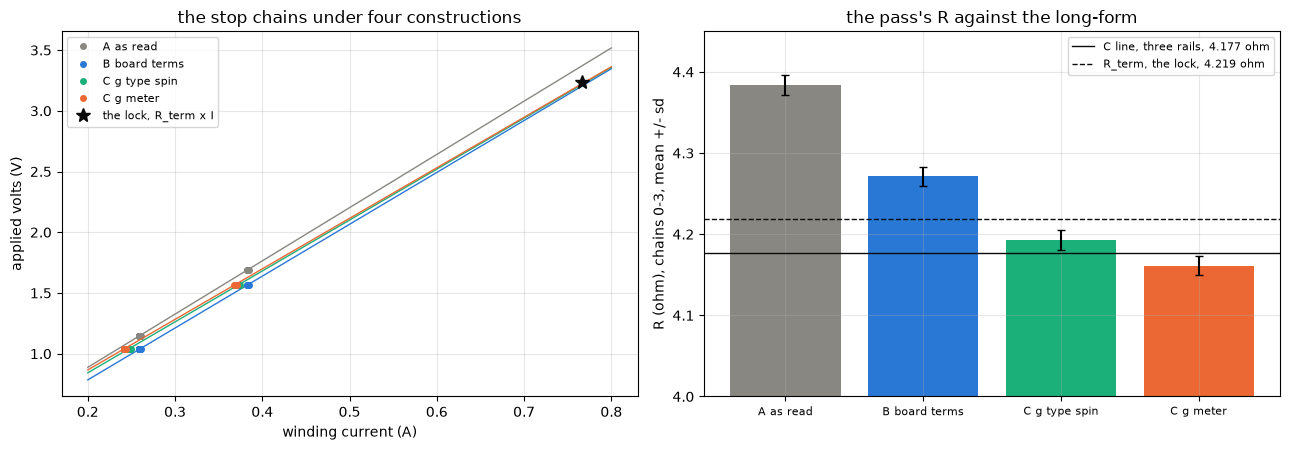

In [26]:
COLORS = {"A as read": MUTED, "B board terms": BLUE,
          "C g type spin": GREEN, "C g meter": ORANGE}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for name, kw in CONSTRUCTIONS.items():
    v, i = construct(ST["duty"], ST["v_on_v"], ST["i_crest_a"], **kw)
    ax[0].plot(i, v, "o", ms=4, color=COLORS[name], label=name)
    p = PASS_R.loc[name]
    xx = np.array([0.2, 0.8])
    ax[0].plot(xx, p["v0_v"] + p["r_ohm"] * xx, color=COLORS[name], lw=1)
ax[0].plot([I_LOCK], [R_LOCKED["value"] * I_LOCK], "*", color=INK, ms=10,
           label="the lock, R_term x I")
figures.label(ax[0], x="winding current (A)", y="applied volts (V)",
              title="the stop chains under four constructions")
ax[0].legend(fontsize=8)
x = np.arange(len(PASS_R))
ax[1].bar(x, PASS_R["r_ohm"], yerr=PASS_R["r_sd"], capsize=3,
          color=[COLORS[c] for c in PASS_R.index])
ax[1].axhline(R_C["value"], color=INK, lw=1,
              label=f"C line, three rails, {R_C['value']:.3f} ohm")
ax[1].axhline(R_LOCKED["value"], color=INK, lw=1, ls="--",
              label=f"R_term, the lock, {R_LOCKED['value']:.3f} ohm")
ax[1].set_xticks(x, list(PASS_R.index), fontsize=8)
ax[1].set_ylim(4.0, 4.45)
figures.label(ax[1], y="R (ohm), chains 0-3, mean +/- sd",
              title="the pass's R against the long-form")
ax[1].legend(fontsize=8)
figures.finish(fig)

What you are looking at. Left, every chain step as applied volts against winding current under each construction, the pass's line through each, and the lock's R_term times its current as the star. Right, the pass's R per construction, the mean and sd over chains 0 to 3, against C's line on three rails and the lock's R_term.

Graded against C's line, the pass under C with the meter's g reads -0.373 % at -1.839 sigma, and its line at the lock's 0.767 A reads 4.206 ohm, -0.313 % and -1.824 sigma under R_term. Both reproduce. V0 under C sits 0.945 sigma from the line's. As read the pass misses by 24.194 sigma and with the board terms alone by 10.902 sigma. An alternative reading of the -0.3 %, at moderate confidence, is the commutator angle. The pass sees two seats, 4.155 ohm at the low stop and 4.167 at the high under C, where the line averages the rails' chains and the lock at other angles (discrepancy 4).

## 3. Step 2, the bursts at a held seat

Each burst holds a duty step at the seat over a short run of PWM periods. The pass holds the low stop, the seat a user has, and keeps bursts 1 to 3 of four groups at 25 and 40 % both signs, the first of each group out as stage 2 found. Each burst goes through `oscnb.bursts.period_table` with stage 1's edge lags as board constants and no edge fold, then the inductance notebook's period fit,

$$V_n = R\,\bar{i}_n + L\,\frac{\Delta i_n}{T}$$

with $V_n$ the period's mean volts, $\bar{i}_n$ the mean current over a pair of periods, $\Delta i_n$ its rise across the pair, $T$ the PWM period, and $R$ and $L$ both over the window's scale k. The lock and the wound seat are read the same way as the comparison.

In [27]:
SEATS = {"stop": BURST_DIR, "lock": PAIR_DIR / "inductance" / "locked-4",
         "wound": PAIR_DIR / "inductance" / "wound-5"}
GROUPS = PASS_GROUPS + ["g5-rev-25-rested"]
T_PERIOD = 2 * ARR / bursts.TICKS_PER_US * 1e-6   # s, one PWM period
DIP_V = IND["dip_mv_per_period_motor"]["value"] * 1e-3   # V, the fold's dip
SET_ASIDE = ("stop", "g1-fwd-25", 4)   # the inductance notebook's moved one
print(f"seats {list(SEATS)}; groups {GROUPS}; period "
      f"{T_PERIOD * 1e6:.0f} us; window scale k {K_WINDOW:.4f}")
print("stage 1's edge lags (ticks): " + ", ".join(
    f"{k} {v:.1f}" for k, v in LAGS.items()) + f"; the notebook's dip "
      f"{DIP_V * 1e3:+.1f} mV per period, set aside {SET_ASIDE}")

seats ['stop', 'lock', 'wound']; groups ['g1-fwd-25', 'g2-fwd-40', 'g3-rev-40', 'g4-rev-25', 'g5-rev-25-rested']; period 50 us; window scale k 1.0063
stage 1's edge lags (ticks): on 44.0, tap_on 39.5, off 14.0, settle 72.0; the notebook's dip -6.1 mV per period, set aside ('stop', 'g1-fwd-25', 4)


In [28]:
def period_fit(table):
    """The inductance notebook's period fit: V_n = R i_mean + L di / T over
    the pairs of periods, both over the window's scale k."""
    i, v = table["i_a"].to_numpy(), table["v_v"].to_numpy()
    p = len(i) - 1
    di = i[1:p + 1] - i[:p]                 # A, the rise period to period
    im = (i[1:p + 1] + i[:p]) / 2           # A, the pair's mean current
    X = np.c_[im, di / T_PERIOD]
    (r, l), *_ = np.linalg.lstsq(X, v[:p], rcond=None)
    resid = v[:p] - X @ np.array([r, l])
    return {"r_ohm": r / K_WINDOW, "l_mh": l / K_WINDOW * 1e3,
            "tau_us": l / r * 1e6,
            "resid_rms_mv": float(np.sqrt(np.mean(resid ** 2)) * 1e3)}


def ripple_l(table, r_ohm):
    """L from the on-window's slope, (V_on - R k i) / slope / k, in mH."""
    v_on, i = table["v_on_v"].to_numpy(), table["i_a"].to_numpy()
    slope = table["slope_a_per_s"].to_numpy()
    return (v_on - r_ohm * K_WINDOW * i) / slope / K_WINDOW * 1e3

In [29]:
def read_seat(seat, folder):
    """(rows, tables): every burst of a seat through stage 1's lags, no
    edge fold, its period fit."""
    rows, tables = [], {}
    for group in GROUPS:
        meta_g = json.loads((folder / group / "meta.json").read_text())
        BOARD.check_meta(meta_g, str(results.rel(folder / group)))
        for k, df in enumerate(bursts.load(folder / group)):
            m = bursts.meta(df)
            sign = 1 if m["step_q15"] > 0 else -1
            table = bursts.period_table(df, sign, BOARD, SC, LAGS)
            f = period_fit(table)
            l_rip = ripple_l(table, R_LOCKED["value"])
            rows.append({"seat": seat, "group": group, "k": k,
                         "first": k == 0, "pct": bursts.duty_pct(m),
                         "sign": sign, "pos": m["pos"],
                         "periods": len(table), **f,
                         "l_ripple_mh": float(np.median(l_rip[-3:])),
                         "i_last_a": table["i_a"].iloc[-1],
                         "set_aside": (seat, group, k) == SET_ASIDE})
            tables[(seat, group, k)] = table
    return pd.DataFrame(rows), tables

In [30]:
frames, TABLES = [], {}
for seat, folder in SEATS.items():
    F_seat, tb = read_seat(seat, folder)
    frames.append(F_seat)
    TABLES.update(tb)
FB = pd.concat(frames, ignore_index=True)
print(f"{len(FB)} bursts on three seats; periods per burst "
      f"{FB['periods'].min()} to {FB['periods'].max()}; fit residual rms "
      f"{FB['resid_rms_mv'].min():.1f} to {FB['resid_rms_mv'].max():.1f} mV")
in_pass = (FB["group"].isin(PASS_GROUPS) & FB["k"].isin(PASS_BURSTS)
           & ~FB["set_aside"])
PB = FB[(FB["seat"] == "stop") & in_pass]
show(PB[["group", "k", "pct", "sign", "pos", "r_ohm", "l_mh", "tau_us",
         "resid_rms_mv", "l_ripple_mh", "i_last_a"]], n=None)

69 bursts on three seats; periods per burst 9 to 9; fit residual rms 11.6 to 35.0 mV


,group,k,pct,sign,pos,r_ohm,l_mh,tau_us,resid_rms_mv,l_ripple_mh,i_last_a
1,g1-fwd-25,1,25,1,2,4.123,0.829,201.100,18.790,0.588,0.241
2,g1-fwd-25,2,25,1,2,4.132,0.807,195.202,26.243,0.578,0.243
3,g1-fwd-25,3,25,1,2,4.156,0.779,187.496,26.333,0.581,0.243
6,g2-fwd-40,1,40,1,3,4.341,0.885,203.900,26.523,0.656,0.368
7,g2-fwd-40,2,40,1,2,4.326,0.877,202.765,27.995,0.649,0.370
8,g2-fwd-40,3,40,1,2,4.314,0.866,200.707,22.435,0.649,0.371
11,g3-rev-40,1,40,-1,2,4.316,0.865,200.390,16.314,0.649,0.371
12,g3-rev-40,2,40,-1,3,4.290,0.878,204.585,18.617,0.651,0.371
13,g3-rev-40,3,40,-1,3,4.292,0.874,203.626,23.395,0.633,0.372
16,g4-rev-25,1,25,-1,3,4.178,0.832,199.243,11.620,0.597,0.238


In [31]:
def summarize(F, label):
    """Mean, median, sd and se over bursts of L, tau, R and ripple L."""
    out = {"label": label, "n": len(F)}
    for col in ("l_mh", "tau_us", "r_ohm", "l_ripple_mh"):
        x = F[col]
        out[col] = x.mean()
        out[col + "_median"] = x.median()
        out[col + "_sd"] = x.std(ddof=1)
        out[col + "_se"] = x.std(ddof=1) / np.sqrt(len(x))
    return out


SB = summarize(PB, "pass")
BY_DUTY = {int(d): summarize(g, f"{d} %") for d, g in PB.groupby("pct")}
print(f"pass: L {SB['l_mh']:.4f} mH sd {SB['l_mh_sd']:.4f} se "
      f"{SB['l_mh_se']:.4f}; tau {SB['tau_us']:.1f} us sd "
      f"{SB['tau_us_sd']:.1f}; R {SB['r_ohm']:.4f} sd {SB['r_ohm_sd']:.4f}"
      f"; ripple L {SB['l_ripple_mh']:.4f}")
for d, s in BY_DUTY.items():
    print(f"  {d} %: L {s['l_mh']:.4f} sd {s['l_mh_sd']:.4f} (n {s['n']}), "
          f"tau {s['tau_us']:.1f}; the notebook's stop seat "
          f"{L_BY_SEAT['stop'][str(d)]['value']:.4f}, its lock "
          f"{L_BY_SEAT['lock'][str(d)]['value']:.4f} mH")

pass: L 0.8432 mH sd 0.0354 se 0.0102; tau 199.0 us sd 5.3; R 4.2356 sd 0.0843; ripple L 0.6217
  25 %: L 0.8123 sd 0.0201 (n 6), tau 195.4; the notebook's stop seat 0.8130, its lock 0.7952 mH
  40 %: L 0.8741 sd 0.0077 (n 6), tau 202.7; the notebook's stop seat 0.8793, its lock 0.8695 mH


In [32]:
stop, lock, wound = (FB["seat"] == s for s in ("stop", "lock", "wound"))
held = ~FB["first"] & ~FB["set_aside"]          # every burst after the first
first_in = (FB["group"].isin(PASS_GROUPS) & FB["k"].isin((0,) + PASS_BURSTS)
            & ~FB["set_aside"])
VARIANTS = {
    "pass": SB,
    "pass + first bursts": summarize(FB[stop & first_in], "stop 0-3"),
    "stop, every burst after the first": summarize(FB[stop & held], "stop"),
    "lock, the pass's design": summarize(FB[lock & in_pass], "lock"),
    "lock, every burst after the first": summarize(FB[lock & held], "lock"),
    "wound, the pass's design": summarize(FB[wound & in_pass], "wound"),
    "pass, 25 % only": BY_DUTY[25], "pass, 40 % only": BY_DUTY[40]}
VT = pd.DataFrame(VARIANTS).T
show(VT[["n", "l_mh", "l_mh_sd", "tau_us", "tau_us_sd", "r_ohm",
         "r_ohm_sd", "l_ripple_mh"]].astype(float), n=None)

,n,l_mh,l_mh_sd,tau_us,tau_us_sd,r_ohm,r_ohm_sd,l_ripple_mh
pass,12.000,0.843,0.035,199.016,5.269,4.236,0.084,0.622
pass + first bursts,16.000,0.851,0.036,200.139,5.655,4.249,0.087,0.624
"stop, every burst after the first",17.000,0.842,0.034,198.901,5.590,4.231,0.083,0.625
"lock, the pass's design",12.000,0.840,0.041,196.374,8.101,4.276,0.046,0.645
"lock, every burst after the first",18.000,0.839,0.039,196.582,7.989,4.268,0.049,0.645
"wound, the pass's design",12.000,0.837,0.036,196.175,6.450,4.265,0.059,0.642
"pass, 25 % only",6.000,0.812,0.020,195.369,5.113,4.158,0.028,0.596
"pass, 40 % only",6.000,0.874,0.008,202.662,1.741,4.313,0.020,0.648


The variants keep or drop the first bursts and read the lock and the wound seat under the pass's design, beside every held burst.

In [33]:
fold = []
for key in PB.apply(lambda r: (r["seat"], r["group"], r["k"]), axis=1):
    tb = TABLES[key].copy()
    tb["v_v"] = tb["v_v"] + DIP_V           # the fold's dip on every period
    fold.append(period_fit(tb))
FOLD = pd.DataFrame(fold)
FOLD_PCT = {c: (FOLD[c].mean() / SB[c] - 1) * 100
            for c in ("l_mh", "r_ohm", "tau_us")}
print(f"with the dip folded in: L {FOLD['l_mh'].mean():.4f} "
      f"({FOLD_PCT['l_mh']:+.2f} %), R {FOLD['r_ohm'].mean():.4f} "
      f"({FOLD_PCT['r_ohm']:+.2f} %), tau {FOLD['tau_us'].mean():.1f} us")
lk = FB[lock & ~FB["first"]]
gm = lk.groupby("group")["l_mh"].median()
print(f"the lock read the same way: L {lk['l_mh'].mean():.4f} mean, "
      f"group medians {gm.min():.4f} to {gm.max():.4f}; the notebook's "
      f"{L_LONG['value']:.4f} [{L_LONG['lo']:.4f}, {L_LONG['hi']:.4f}] with "
      f"its fold; tau {lk['tau_us'].mean():.1f} against "
      f"{TAU_LONG['value']:.1f}")
for d in (25, 40):
    g = lk[lk["pct"] == d]
    print(f"  lock {d} %: L {g['l_mh'].median():.4f} against the "
          f"notebook's {L_BY_SEAT['lock'][str(d)]['value']:.4f}; tau "
          f"{g['tau_us'].median():.1f} against "
          f"{TAU_BY_SEAT['lock'][str(d)]['value']:.1f}")

with the dip folded in: L 0.8398 (-0.41 %), R 4.2166 (-0.45 %), tau 199.1 us
the lock read the same way: L 0.8391 mean, group medians 0.7910 to 0.8810; the notebook's 0.8198 [0.7814, 0.8740] with its fold; tau 196.6 against 198.5
  lock 25 %: L 0.8074 against the notebook's 0.7952; tau 191.1 against 191.3
  lock 40 %: L 0.8759 against the notebook's 0.8695; tau 203.1 against 203.2


In [34]:
def half(x):
    return (x["hi"] - x["lo"]) / 2


G_L = [grade("L (pass, stop seat)", SB["l_mh"], SB["l_mh_se"],
             L_LONG["value"], half(L_LONG), "mH", "half the group range"),
       grade("tau (pass, stop seat)", SB["tau_us"], SB["tau_us_se"],
             TAU_LONG["value"], half(TAU_LONG), "us", "the same"),
       grade("burst R (pass, stop seat)", SB["r_ohm"], SB["r_ohm_se"],
             R_BURST_LONG["value"], half(R_BURST_LONG), "ohm", "the same")]
for d in (25, 40):
    s = BY_DUTY[d]
    for seat in ("stop", "lock"):
        lv = L_BY_SEAT[seat][str(d)]
        G_L.append(grade(f"L {d} % (pass) vs the notebook's {seat}",
                         s["l_mh"], s["l_mh_se"], lv["value"], half(lv),
                         "mH"))
GR_L = pd.DataFrame(G_L)
show(GR_L[["quantity", "pass", "pass_se", "long", "long_sigma",
           "gap_pct", "gap_sigma"]], n=None)

,quantity,pass,pass_se,long,long_sigma,gap_pct,gap_sigma
0,"L (pass, stop seat)",0.843,0.010,0.820,0.046,2.861,0.495
1,"tau (pass, stop seat)",199.016,1.521,198.505,9.340,0.257,0.054
2,"burst R (pass, stop seat)",4.236,0.024,4.217,0.086,0.437,0.206
3,L 25 % (pass) vs the notebook's stop,0.812,0.008,0.813,0.004,-0.082,-0.074
4,L 25 % (pass) vs the notebook's lock,0.812,0.008,0.795,0.004,2.151,1.881
5,L 40 % (pass) vs the notebook's stop,0.874,0.003,0.879,0.005,-0.584,-0.832
6,L 40 % (pass) vs the notebook's lock,0.874,0.003,0.869,0.005,0.534,0.828


In [35]:
first = FB[stop & FB["first"]].set_index("group")
others = FB[stop & held].groupby("group")["l_mh"].median()
FIRST_JUMP = {g: (first.loc[g, "l_mh"] / others[g] - 1) * 100
              for g in GROUPS}
print("the first burst of each stop group over its others' median (L): "
      + ", ".join(f"{g} {v:+.1f} %" for g, v in FIRST_JUMP.items()))
walk = FB[stop].groupby("group")["pos"].agg(["min", "max"])
print("the seat by group (pos): " + ", ".join(
    f"{g} {r['min']}-{r['max']}" for g, r in walk.iterrows()))
aside = FB[FB["set_aside"]].iloc[0]
print(f"the set-aside burst: L {aside['l_mh']:.3f} mH, R "
      f"{aside['r_ohm']:.2f} ohm against its group's "
      f"{FB[stop & held & (FB['group'] == 'g1-fwd-25')]['r_ohm'].median():.2f}")
SEAT_L = np.array([VARIANTS[k]["l_mh"] for k in (
    "pass", "lock, the pass's design", "wound, the pass's design")])
print(f"the pass's design at stop / lock / wound: "
      + " / ".join(f"{x:.4f}" for x in SEAT_L) + f" mH, spread "
      f"{(SEAT_L.max() / SEAT_L.min() - 1) * 100:.2f} %")

the first burst of each stop group over its others' median (L): g1-fwd-25 +10.2 %, g2-fwd-40 +2.9 %, g3-rev-40 -0.1 %, g4-rev-25 +1.3 %, g5-rev-25-rested -0.2 %
the seat by group (pos): g1-fwd-25 2-3, g2-fwd-40 2-3, g3-rev-40 2-3, g4-rev-25 2-3, g5-rev-25-rested 2-3
the set-aside burst: L 0.713 mH, R 3.22 ohm against its group's 4.13
the pass's design at stop / lock / wound: 0.8432 / 0.8399 / 0.8369 mH, spread 0.75 %


The pass's bursts read L 0.8432 mH, sd 0.0354 and se 0.0102, tau 199.0 us and the window model's R 4.2356 ohm. L rises with the current, 0.8123 mH at 25 % and 0.8741 at 40 %. Per duty the pass sits -0.082 % and -0.584 % from the inductance notebook's own stop-seat numbers, which carry its edge fold and every held burst, and +2.151 % and +0.534 % over its lock's, the seat difference that notebook found. Folding the notebook's per-period dip of -6.1 mV into every period moves L by -0.41 % and R by -0.45 %, so a tool without the fold loses under half a percent.

The same reduction at the lock gives L 0.8074 and 0.8759 mH at 25 and 40 % against that notebook's 0.7952 and 0.8695, and tau 191.1 and 203.1 us against 191.3 and 203.2. The notebook's headline 0.8198 mH is the median over its group medians, so its bracket of 0.7814 to 0.8740 is the 25 and 40 % split.

The first burst of each stop group reads over its others' median by +10.2 % (g1), +2.9 % (g2), -0.1 % (g3) and +1.3 % (g4) in L, and -0.2 % in the rested group. A tool that keeps three each has to capture four and drop the first after a change of sign or seat. The seat held at pos 2 to 3 through every group. The burst the inductance notebook set aside reads L 0.713 mH and R 3.22 ohm against its group's 4.13, a rotor that moved. At the lock and the wound seat the pass's design reads 0.8399 and 0.8369 mH, a spread of 0.75 % over the three seats.

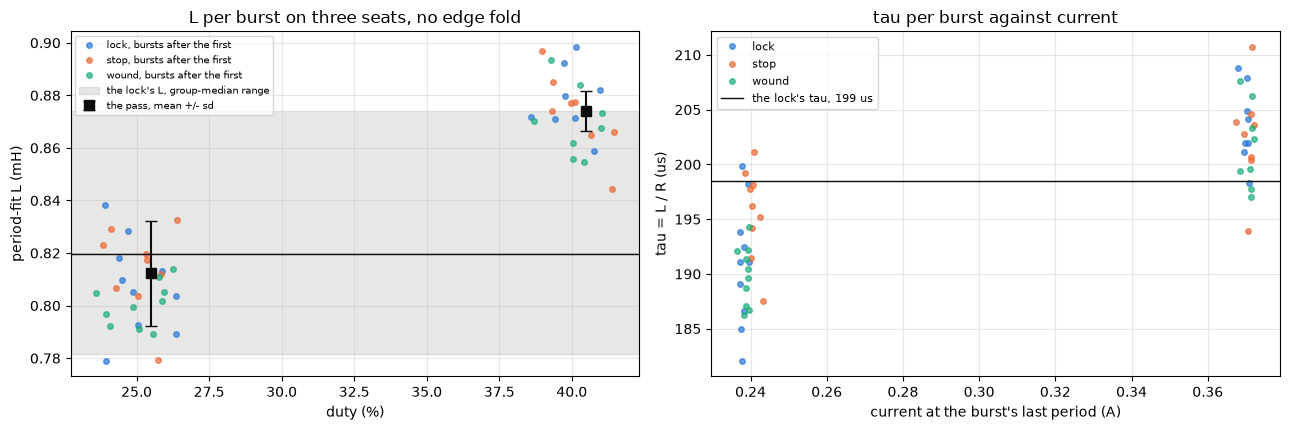

In [36]:
SEAT_COLOR = {"stop": ORANGE, "lock": BLUE, "wound": GREEN}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
jit = np.random.default_rng(1)          # a fixed jitter, off the duty
for seat, g in FB[held].groupby("seat"):
    ax[0].plot(g["pct"] + jit.uniform(-1.5, 1.5, len(g)), g["l_mh"], "o",
               ms=4, alpha=0.7, color=SEAT_COLOR[seat],
               label=f"{seat}, bursts after the first")
    ax[1].plot(g["i_last_a"], g["tau_us"], "o", ms=4, alpha=0.7,
               color=SEAT_COLOR[seat], label=seat)
ax[0].axhspan(L_LONG["lo"], L_LONG["hi"], color=MUTED, alpha=0.2,
              label="the lock's L, group-median range")
ax[0].axhline(L_LONG["value"], color=INK, lw=1)
ax[0].errorbar([25.5, 40.5], [BY_DUTY[d]["l_mh"] for d in (25, 40)],
               yerr=[BY_DUTY[d]["l_mh_sd"] for d in (25, 40)], fmt="s",
               color=INK, ms=7, capsize=4, label="the pass, mean +/- sd")
figures.label(ax[0], x="duty (%)", y="period-fit L (mH)",
              title="L per burst on three seats, no edge fold")
ax[0].legend(fontsize=7)
ax[1].axhline(TAU_LONG["value"], color=INK, lw=1,
              label=f"the lock's tau, {TAU_LONG['value']:.0f} us")
figures.label(ax[1], x="current at the burst's last period (A)",
              y="tau = L / R (us)", title="tau per burst against current")
ax[1].legend(fontsize=8)
figures.finish(fig)

What you are looking at. Left, every burst after the first on the three seats, L from the period fit against the duty with a small jitter off the duty, the pass's mean and sd at each duty in black, and the lock's headline with its group range shaded. Right, tau per burst against the current at its last period. On every seat L and tau rise with the current.

Graded against the lock's headline with half its group range as sigma, the pass's L reads +2.861 % at 0.495 sigma, tau +0.257 % at 0.054 sigma and the burst R +0.437 % at 0.206 sigma. All three reproduce. L does so inside a bracket that is the duty split, so the number to carry with it is the duty, 0.8123 mH at 25 % and 0.8741 at 40 %.

## 4. Step 3, the coast rungs and Ke

Each rung is a spin and a natural coast with the bridge open, both ways, three cycles a rung. The reads mirror the ladder notebook's. The spin window is the held duty's last stretch, and the crest current is read over the sweep's own torque-off zero with stage 1's in-drive offset out. The ripple tach, a count of the current's commutation ripple, gives the spin's speed, seeded by the coast. Ke comes from bemf-coast's window, whole ripple cycles over a short window just past the cut, the mean EMF over the window's speed, with the ladder's gate on how much speed the window loses and how many cycles it holds. The brackets of sittings 1, 6 and 7 are read the same way for section 8.

In [37]:
WINDOW_MS, WINDOW_MIN_MS = 100, 20   # ms, the ladder's spin window
TAIL_ROWS = 2000                     # a coast's last 100 ms, the awake zero
DECEL_FRAC_MAX, MIN_CYCLES = 0.35, 4  # the ladder's Ke gate on a coast
SETTLE_PCT = 2.5                     # %, a settled spin
HOLD_TAIL_ROWS = 8000                # a hold's last 400 ms
TURN_REV_S, SEED_MIN_HZ = 1.0, 7.5   # turning, and the lowest tach seed
POT_MOVE_COUNTS = 3                  # counts, the kick's pot has left
KNOTS = np.arange(150.0, 501.0, 50.0)   # rev/s, the brush table's knots
R_PASS = PASS_R.loc["C g meter", "r_ohm"]   # ohm, step 1 under C
V0_PASS = PASS_R.loc["C g meter", "v0_v"]   # V
# the 5 V capture, then sitting 1's brackets, then sittings 6 and 7's
SET_NAMES = ["capture-1", "ref-open-1", "ref-close-1", "runup-open-1",
             "runup-close-1", "ref-open-6", "ref-close-6", "ref-open-7",
             "ref-close-7", "runup-open-6", "runup-close-6",
             "runup-open-7", "runup-close-7"]
SETS = {n: PAIR_DIR / ("run-up" if n.startswith("runup") else "ladder") / n
        for n in SET_NAMES}
print(f"the pass's R {R_PASS:.4f} ohm, V0 {V0_PASS * 1e3:+.1f} mV (step 1"
      f", C with g {G_METER['value']:.2f} mS); sets: {', '.join(SETS)}")
print(f"spin window the held duty's last {WINDOW_MS} ms, at most half the "
      f"held rows, at least {WINDOW_MIN_MS} ms; Ke gate decel <= "
      f"{DECEL_FRAC_MAX}, cycles >= {MIN_CYCLES}; settled within "
      f"{SETTLE_PCT} %; holds over the last {HOLD_TAIL_ROWS / FS * 1e3:.0f}"
      f" ms, turning over {TURN_REV_S:.0f} rev/s; kick moved at "
      f"{POT_MOVE_COUNTS} counts")

the pass's R 4.1610 ohm, V0 +34.2 mV (step 1, C with g 4.75 mS); sets: capture-1, ref-open-1, ref-close-1, runup-open-1, runup-close-1, ref-open-6, ref-close-6, ref-open-7, ref-close-7, runup-open-6, runup-close-6, runup-open-7, runup-close-7
spin window the held duty's last 100 ms, at most half the held rows, at least 20 ms; Ke gate decel <= 0.35, cycles >= 4; settled within 2.5 %; holds over the last 400 ms, turning over 1 rev/s; kick moved at 3 counts


In [38]:
def spin_window(sp):
    """(window, the window before, info): the held duty's last 100 ms, at
    most half the held rows and at least 20 ms."""
    ticks = sp["duty_counts"].abs()
    half = float(ticks.iloc[len(sp) // 2:].median())   # the held duty
    held = sp[ticks == half]
    n = int(min(WINDOW_MS * FS / 1e3, len(held) // 2))
    n = min(max(n, int(WINDOW_MIN_MS * FS / 1e3)), len(held))
    prev = held.iloc[-2 * n:-n] if len(held) >= 2 * n else None
    return held.iloc[-n:], prev, {
        "half_ticks": half, "duty_pct": 100 * half / ARR,
        "spin_ms": len(sp) / FS * 1e3, "window_ms": n / FS * 1e3,
        "window_valid_share": float(held.iloc[-n:]["window_valid"].mean())}


def e0_line(emf, start, f_seed, target_ms=10):
    """bemf-coast's window: whole ripple cycles near 10 ms from `start`,
    a line through the box-smoothed EMF over them, the mean EMF."""
    f, i0, i1, n = ripple.read_window(emf, start, f_seed,
                                      target_ms=target_ms)
    if not np.isfinite(f) or n == 0:
        return dict(dedt=np.nan, e_win=np.nan, i0=start, i1=start,
                    f=np.nan, n=0)
    nbox = max(int(round(FS / f)), 1)    # one ripple cycle of rows
    smooth = np.convolve(emf, np.ones(nbox) / nbox, mode="same")
    t = np.arange(len(emf)) / FS
    p = np.polyfit(t[i0:i1], smooth[i0:i1], 1)
    return dict(dedt=float(p[0]), e_win=float(emf[i0:i1].mean()),
                i0=i0, i1=i1, f=f, n=n)

In [39]:
def coast_read(co, d, zero_e):
    """(row): the coast from the cut, over the rest tap zero, open rows
    bridged, Ke over bemf-coast's window with the ladder's gate."""
    cut = coast.cut_row(co)
    emf_read = coast.emf_from_cut(co, d, cut, zero_e,
                                  v_per_count=SC.v_per_count)
    row = {"e_first_v": float(coast.early_emf(emf_read))}
    row["turned"] = bool(row["e_first_v"] >= coast.TURN_V)
    if not row["turned"]:
        return row
    bad = coast.open_rows(emf_read)
    emf = coast.bridge(emf_read, bad)
    stop = coast.stop_row(emf)
    f0 = coast.seed_freq(emf)
    m = e0_line(emf, coast.COAST_FROM_ROWS, f0)
    row.update(f_seed=f0, dedt_v_s=m["dedt"], coast_cycles=m["n"],
               stop_ms=np.nan if stop is None else stop / FS * 1e3,
               win_ms=(m["i1"] - m["i0"]) / FS * 1e3)
    if np.isfinite(m["f"]):
        w = RPS * m["f"] / PER_REV                  # rad/s over the window
        row["coast_rev_s"] = m["f"] / PER_REV
        row["ke_mv_per_rev_s"] = m["e_win"] / w * RPS * 1e3
        row["decel_frac_win"] = -m["dedt"] * row["win_ms"] / 1e3 / m["e_win"]
        row["ke_gate"] = bool(row["decel_frac_win"] <= DECEL_FRAC_MAX
                              and m["n"] >= MIN_CYCLES)
    # the coast's travel, the EMF's integral over the ladder's Ke
    e_stop = emf[:stop] if stop is not None else emf
    row["coast_revs_emf"] = float(np.maximum(e_stop, 0).sum() / FS
                                  / (KE_LONG["value"] * 1e-3))
    return row

In [40]:
def spin_current(win, d, zero_i, half, awake):
    """(row): the crest current, V_on and every construction's applied
    volts and winding current over the window, at 100 % none applied."""
    raw = win["current_raw"].to_numpy(float)
    i_over = raw - zero_i                       # counts over the rest zero
    i_a = (i_over - SC.drive_offset_counts) / SC.counts_per_a
    taps = ((win["vmotor_a"] - win["vmotor_b"]) * d).to_numpy(float)
    D = half / ARR
    row = {"i_crest_a": float(i_a.mean()),
           "i_awake_a": float(((i_over - awake) / SC.counts_per_a).mean()),
           "v_on_v": float(SC.volts(taps, SC.terminal_offset_counts).mean())}
    for name, kw in CONSTRUCTIONS.items():
        full = D >= 1                           # nothing switches at 100 %
        edge = 0.0 if full else kw["edge_ticks"]
        loop = 0.0 if full else kw["loop_ohm"]
        g = 0.0 if full else kw["g_s"]
        d_eff = (2 * D * ARR - edge) / (2 * ARR)
        i_m = row["i_crest_a"] - g * (1 - D) * row["v_on_v"]
        row[f"v_{name}"] = d_eff * row["v_on_v"] - (1 - d_eff) * loop * i_m
        row[f"i_{name}"] = i_m
    drop = tel.dropout_rows(i_over)             # rows under 25 % of the mean
    row["dropout_rows"] = int(drop.sum())
    row["dropouts_per_s"] = float(drop.sum() / (len(win) / FS))
    n20 = int(0.020 * FS)                       # the drive's last 20 ms
    row["dropout_rows_last20"] = int(tel.dropout_rows(i_over[-n20:]).sum())
    return row

In [41]:
def count_rev_s(x, f_seed):
    """The ripple tach over `x`, its mean taken out, in rev/s."""
    x = np.asarray(x, float)
    f, n = ripple.count_cycles(x - x.mean(), f_seed)
    return f / PER_REV, n


def spin_speeds(win, prev, d, f_seed):
    """(row): the tach over the window, the window before and the last
    20 ms, seeded by the coast; the pot nominal and through the table."""
    row = {}
    raw = win["current_raw"].to_numpy(float)
    if np.isfinite(f_seed):
        row["spin_rev_s"], row["spin_cycles"] = count_rev_s(raw, f_seed)
        if prev is not None:
            row["spin_prev_rev_s"] = count_rev_s(
                prev["current_raw"].to_numpy(float), f_seed)[0]
        row["spin_rev_s_last20"] = count_rev_s(raw[-int(0.02 * FS):],
                                               f_seed)[0]
    for scale in ("nominal", "table"):
        w, cps, mid = pot_speed_rev_s(win["pos"].to_numpy(float), scale)
        row[f"pot_rev_s_{scale}"] = w * d
    row["pot_mid_counts"], row["pot_cps"] = mid, cps * d
    return row

In [42]:
def reduce_cycle(name, folder, info):
    """(rows): every spin and coast of one cycle's sweep, both ways."""
    df, zero_i, zero_e = load_sweep(folder)
    pr = probe_for(folder)
    base = {"set": name, "k": int(info["k"]),
            "volts_set": float(info["volts_set"]),
            "rail_v": float(pr["rail_v"]), "ntc_c": float(pr["ntc_c"]),
            "t_start": float(info["t_start"]),
            "t_end": float(info["t_end"]), "zero_i": float(zero_i)}
    rows = []
    for d, sp, co in coast.pairs(df):
        crow = coast_read(co, d, zero_e)
        cur = co["current_raw"].to_numpy(float)
        awake = float(np.mean(cur[-TAIL_ROWS:]) - zero_i)  # the awake step
        win, prev, srow = spin_window(sp)
        srow.update(spin_current(win, d, zero_i, srow["half_ticks"], awake))
        srow.update(spin_speeds(win, prev, d, crow.get("f_seed", np.nan)))
        pos_sp, pos_co = (x["pos"].to_numpy(float) for x in (sp, co))
        srow.update(pos_spin_start=pos_sp[0], pos_spin_end=pos_sp[-1],
                    pos_coast_end=float(np.median(pos_co[-200:])))
        rows.append({**base, "dir": d, "awake_step_counts": awake,
                     **srow, **crow})
    return rows

In [43]:
rows = []
for name, folder in SETS.items():
    cy = cycles.load(folder)
    for _, info in cy.iterrows():
        if name == "capture-1" and float(info["volts_set"]) != RAIL_V:
            continue                     # the pass has one supply
        rows += reduce_cycle(name, cy.folder(info["k"]), info)
S = pd.DataFrame(rows)
S["duty"] = S["duty_pct"].round().astype(int)
S["sitting"] = S["set"].str.extract(r"-(\d)$")[0].astype(int)
S["settle_pct"] = (S["spin_rev_s"] / S["spin_prev_rev_s"] - 1) * 100
S["settled"] = S["settle_pct"].abs() < SETTLE_PCT
S["ke_gate"] = S["ke_gate"].fillna(False).astype(bool)
S["pass_rung"] = (S["set"].isin(["capture-1", "runup-open-1"])
                  & S["duty"].isin(PASS_DUTIES))
S["alt_rung"] = (S["set"] == "capture-1") & S["duty"].isin(ALT_DUTIES)
print(f"{len(S)} spins and coasts from {S.groupby('set')['k'].nunique().sum()}"
      f" cycles; window_valid at least {S['window_valid_share'].min():.2f};"
      f" the Ke gate passes {int(S['ke_gate'].sum())} coasts")

102 spins and coasts from 51 cycles; window_valid at least 1.00; the Ke gate passes 90 coasts


In [44]:
P = S[S["pass_rung"] & S["ke_gate"]]     # the pass's gated coasts
GATED_BY = S[S["pass_rung"]].groupby("duty")["ke_gate"].agg(
    lambda s: f"{int(s.sum())}/{len(s)}")
print("gated over all by rung: " + ", ".join(
    f"{d} % {v}" for d, v in GATED_BY.items()))
ke = P["ke_mv_per_rev_s"]
KE_PASS, KE_SD = ke.mean(), ke.std(ddof=1)
KE_SE = KE_SD / np.sqrt(len(ke))
print(f"Ke over {len(ke)} coasts: {KE_PASS:.4f} mV per rev/s, sd "
      f"{KE_SD:.4f} ({KE_SD / KE_PASS * 100:.2f} %), se {KE_SE:.4f} "
      f"({KE_SE / KE_PASS * 100:.3f} %); {KE_PASS / RPS:.5f} mV s/rad")
KE_BY_RUNG = P.groupby("duty").agg(ke=("ke_mv_per_rev_s", "mean"),
                                   sd=("ke_mv_per_rev_s", "std"),
                                   n=("k", "size"),
                                   rev_s=("coast_rev_s", "mean"))
KE_BY_DIR = P.groupby("dir")["ke_mv_per_rev_s"].agg(["mean", "size"])
show(KE_BY_RUNG.reset_index(), n=None)
print("by direction: " + ", ".join(
    f"{d:+d} {r['mean']:.4f} (n {int(r['size'])})"
    for d, r in KE_BY_DIR.iterrows()))
alt = S[(S["pass_rung"] | S["alt_rung"]) & S["ke_gate"]]
cap = P[P["set"] == "capture-1"]
run = P[P["set"] != "capture-1"]
KE_ALT = {"alt_five": alt["ke_mv_per_rev_s"].mean(),
          "capture_only": cap["ke_mv_per_rev_s"].mean(),
          "runup_only": run["ke_mv_per_rev_s"].mean()}
print(f"the alternative five {KE_ALT['alt_five']:.4f} over {len(alt)}; "
      f"the capture's alone {KE_ALT['capture_only']:.4f} over {len(cap)}; "
      f"the run-up's alone {KE_ALT['runup_only']:.4f} over {len(run)}")

gated over all by rung: 15 % 0/6, 30 % 6/6, 60 % 6/6, 100 % 6/6
Ke over 18 coasts: 7.2631 mV per rev/s, sd 0.0255 (0.35 %), se 0.0060 (0.083 %); 1.15595 mV s/rad


,duty,ke,sd,n,rev_s
0,30,7.236,0.017,6,115.018
1,60,7.286,0.011,6,287.191
2,100,7.267,0.017,6,465.200


by direction: -1 7.2626 (n 9), +1 7.2636 (n 9)
the alternative five 7.2726 over 25; the capture's alone 7.2612 over 12; the run-up's alone 7.2668 over 6


In [45]:
rng = np.random.default_rng(20261109)   # a fixed seed, the note's
FEWER = {}
for n in (2, 4, 6, 12):
    draws = np.array([ke.sample(n, random_state=int(rng.integers(1e9)))
                      .mean() for _ in range(2000)])
    FEWER[n] = float(np.sqrt(np.mean((draws / KE_PASS - 1) ** 2)) * 100)
print("fewer coasts drawn from the pass's, rms on its Ke: " + ", ".join(
    f"{n} -> {v:.2f} %" for n, v in FEWER.items()))
KE_TREND = results.fit_line(P["coast_rev_s"],
                            (P["ke_mv_per_rev_s"] / KE_PASS - 1) * 100)
print(f"Ke on the coast's speed {KE_TREND['slope'] * 100:+.3f} +/- "
      f"{KE_TREND['slope_se'] * 100:.3f} % per 100 rev/s "
      f"({KE_TREND['slope'] / KE_TREND['slope_se']:+.1f} sigma); the "
      f"ladder's "
      f"{LAD['ke_speed_trend_rest_zero_pct_per_100_rev_s']['value']:+.3f}")
KE_5V = LAD["ke_by_level_mv_per_rev_s"]["5 V"]   # the ladder's 5 V block
G_KE = [grade("Ke (pass, 5 V coasts)", KE_PASS, KE_SE, KE_LONG["value"],
              KE_LONG["value"] * KE_LONG_SE_PCT / 100, "mV/(rev/s)",
              "18 coasts vs 108; the two se"),
        grade("Ke (pass) vs the ladder's 5 V block", KE_PASS, KE_SE,
              KE_5V["value"], (KE_5V["hi"] - KE_5V["lo"]) / 2 / np.sqrt(36),
              "mV/(rev/s)", "the ladder's 36 coasts at 5 V, sd / 6")]
show(pd.DataFrame(G_KE)[["quantity", "pass", "pass_se", "long",
                         "long_sigma", "gap_pct", "gap_sigma"]], n=None)
print(f"the ladder's rail split "
      f"{LAD['ke_rail_split_matched_pct']['value']:+.2f} % at matched "
      f"speed")

fewer coasts drawn from the pass's, rms on its Ke: 2 -> 0.23 %, 4 -> 0.15 %, 6 -> 0.12 %, 12 -> 0.06 %
Ke on the coast's speed +0.119 +/- 0.052 % per 100 rev/s (+2.3 sigma); the ladder's +0.103


,quantity,pass,pass_se,long,long_sigma,gap_pct,gap_sigma
0,"Ke (pass, 5 V coasts)",7.263,0.006,7.283,0.004,-0.271,-2.654
1,Ke (pass) vs the ladder's 5 V block,7.263,0.006,7.259,0.006,0.052,0.432


the ladder's rail split -0.43 % at matched speed


102 spins and coasts from 51 cycles, every window valid. On the pass's rungs the gate passes 0/6 coasts at 15 % and 6/6 at 30, 60 and 100 %. The 8 % rung's coast enters only the floor (section 6). The 18 gated coasts give Ke 7.2631 mV per rev/s, sd 0.35 % and se 0.083 %, 1.15595 mV s/rad. The directions read 7.2636 and 7.2626. By rung Ke reads 7.236 at 115 rev/s, 7.286 at 287 and 7.267 at 465, a trend of +0.119 +/- 0.052 % per 100 rev/s, +2.3 sigma, against the ladder's +0.103. The alternative five reads 7.2726 over 25 coasts and the run-up's coasts alone 7.2668. Fewer coasts drawn at random from the 18 give 0.23 % rms with 2, 0.15 % with 4 and 0.12 % with 6.

Against the ladder's pooled Ke the pass reads -0.271 %, -2.654 sigma on the two se, a 2 to 3 sigma gap. Against the ladder's own 5 V block it reads +0.052 %, 0.432 sigma. The ladder's rail split at matched speed is -0.43 %, larger than the gap. The pass most likely reads the 5 V block's Ke, and the gap to the pool belongs to the long form's own spread across rails, moderate confidence (discrepancy 1). The hand-off carries Ke with that spread as its bracket (section 11).

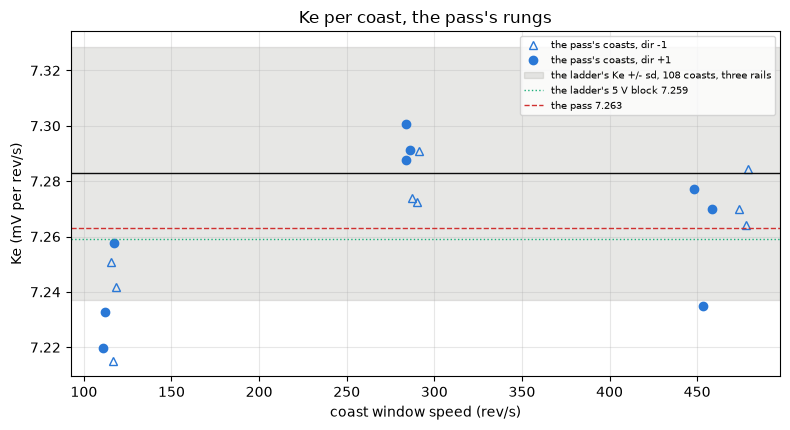

In [46]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for d, g in P.groupby("dir"):
    ax.plot(g["coast_rev_s"], g["ke_mv_per_rev_s"],
            **figures.direction_style(d, BLUE), ms=6,
            label=f"the pass's coasts, dir {d:+d}")
band = KE_LONG["value"] * np.array([1 - KE_LONG_SD_PCT / 100,
                                     1 + KE_LONG_SD_PCT / 100])
ax.axhspan(*band, color=MUTED, alpha=0.2,
           label="the ladder's Ke +/- sd, 108 coasts, three rails")
ax.axhline(KE_LONG["value"], color=INK, lw=1)
ax.axhline(KE_5V["value"], color=GREEN, lw=1, ls=":",
           label=f"the ladder's 5 V block {KE_5V['value']:.3f}")
ax.axhline(KE_PASS, color=RED, lw=1, ls="--",
           label=f"the pass {KE_PASS:.3f}")
figures.label(ax, x="coast window speed (rev/s)",
              y="Ke (mV per rev/s)", title="Ke per coast, the pass's rungs")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. Ke per gated coast of the pass's rungs against the coast window's speed, filled +1 and open -1, the ladder's pooled Ke with its sd band, its 5 V block dotted and the pass's mean dashed. The 30 % coasts sit lowest and the 60 % highest, the speed trend above.

## 5. Step 3, the brush table and the dropouts

The brush residual is what the volts balance leaves once the pass's own constants are out,

$$X = V - K_e\,\omega - R\,i$$

with $V$ and $i$ the applied volts and winding current under construction C with the meter's g, $K_e$ the pass's Ke, $\omega$ ("omega") the tach's speed and $R$ the pass's R0 from step 1. Per rung and direction X is the mean over the spins with a tach and a gated coast, interpolated to the ladder's knots for the table per direction.

In [47]:
KE_V = KE_PASS * 1e-3                   # V per rev/s, the pass's own Ke
for name in CONSTRUCTIONS:
    S[f"x_{name}_mv"] = (S[f"v_{name}"] - KE_V * S["spin_rev_s"]
                         - R_PASS * S[f"i_{name}"]) * 1e3
# the ladder's own crest term (B with g free) in place of the carried g
G_LAD = LAD["rail_term_b_g_ms"]["value"] * 1e-3
D = S["duty"] / 100
i_gl = np.where(D >= 1, S["i_crest_a"],
                S["i_crest_a"] - G_LAD * (1 - D) * S["v_on_v"])
d_eff = np.where(D >= 1, 1.0, (2 * D * ARR - EDGE_5V) / (2 * ARR))
v_gl = d_eff * S["v_on_v"] - (1 - d_eff) * R_BRAKE * i_gl
S["x_C_ladder_g_mv"] = (v_gl - KE_V * S["spin_rev_s"] - R_PASS * i_gl) * 1e3
# the settled-equivalent current, i / (1 + a_drive / a_coast), the
# alternative reading on an unsettled rung
S["alpha_drive"] = ((S["spin_rev_s"] - S["spin_prev_rev_s"]) * RPS
                    / (S["window_ms"] / 1e3))
S["alpha_coast"] = -S["dedt_v_s"] / (S["ke_mv_per_rev_s"] * 1e-3 / RPS)
S["i_settled_a"] = S["i_C g meter"] / (1 + S["alpha_drive"]
                                       / S["alpha_coast"])
S["x_C_settled_mv"] = (S["v_C g meter"] - KE_V * S["spin_rev_s"]
                       - R_PASS * S["i_settled_a"]) * 1e3
TACH_OK = S["ke_gate"] & (S["spin_rev_s"] > 50)   # a tach and a Ke coast
print(f"G of the ladder's B fit {G_LAD * 1e3:.2f} mS; X read on "
      f"{int(((S['pass_rung'] | S['alt_rung']) & TACH_OK).sum())} spins")

G of the ladder's B fit 6.14 mS; X read on 25 spins


In [48]:
X = S[(S["pass_rung"] | S["alt_rung"]) & TACH_OK]
RM = X.groupby(["duty", "dir"]).agg(
    rev_s=("spin_rev_s", "mean"), n=("k", "size"),
    settle=("settle_pct", "mean"),
    i_ma=("i_crest_a", lambda s: s.mean() * 1e3),
    x_C=("x_C g meter_mv", "mean"), x_C_sd=("x_C g meter_mv", "std"),
    x_B=("x_B board terms_mv", "mean"), x_A=("x_A as read_mv", "mean"),
    x_Cl=("x_C_ladder_g_mv", "mean"), x_C_set=("x_C_settled_mv", "mean"),
    dropouts=("dropouts_per_s", "mean")).reset_index()
RM["is_pass"] = RM["duty"].isin(PASS_DUTIES)
show(RM, n=None)
RMP = RM[RM["is_pass"]]
SETTLED_RM = RMP[RMP["settle"].abs() < SETTLE_PCT]
RUNUP_RM = RMP[RMP["settle"].abs() >= SETTLE_PCT]
print(f"settled rungs {SETTLED_RM['rev_s'].min():.0f} to "
      f"{SETTLED_RM['rev_s'].max():.0f} rev/s; the rest settle "
      f"{RUNUP_RM['settle'].min():+.0f} to {RUNUP_RM['settle'].max():+.0f} %")
DIR_TERM = RMP.pivot(index="duty", columns="dir", values="x_C")
DIR_TERM = DIR_TERM[1] - DIR_TERM[-1]
print("direction term +1 over -1 (mV): " + ", ".join(
    f"{d} % {v:+.1f}" for d, v in DIR_TERM.items()))

,duty,dir,rev_s,n,settle,i_ma,x_C,x_C_sd,x_B,x_A,x_Cl,x_C_set,dropouts,is_pass
0,20,-1,82.098,1,-2.368,90.697,14.847,NaN,-67.084,6.173,38.879,11.315,0.000,False
1,30,-1,140.136,3,0.345,100.835,26.461,2.729,-44.527,28.016,47.284,27.155,0.000,True
2,30,1,136.324,3,-1.413,105.411,33.902,2.241,-37.076,36.437,54.722,31.549,0.000,True
3,40,-1,198.161,3,0.527,111.400,36.291,4.257,-24.022,47.330,53.983,37.881,0.000,False
4,40,1,192.665,3,4.809,117.195,49.846,5.350,-10.431,61.955,67.527,63.358,0.000,False
5,60,-1,311.785,3,17.025,132.122,71.783,3.973,32.289,99.295,83.368,146.646,0.000,True
6,60,1,299.928,3,14.260,146.685,91.144,3.537,51.709,120.437,102.711,162.925,0.000,True
7,100,-1,454.908,3,3.317,285.295,274.285,33.799,274.285,274.285,274.285,406.853,12.845,True
8,100,1,441.105,3,8.039,303.191,295.061,64.986,295.061,295.061,295.061,580.287,25.840,True


settled rungs 136 to 140 rev/s; the rest settle +3 to +17 %
direction term +1 over -1 (mV): 30 % +7.4, 60 % +19.4, 100 % +20.8


In [49]:
LONG_B = LAD["v_b_mv"]["tables"]["B - g (1-D) V_on"]   # the ladder's B
TABLE, TABLE_SD, TABLE_SET = {}, {}, {}
for d, g in RMP.groupby("dir"):
    g = g.sort_values("rev_s")
    xs = g["rev_s"].to_numpy()
    tab = np.interp(KNOTS, xs, g["x_C"], left=np.nan, right=np.nan)
    TABLE[d] = tab
    TABLE_SD[d] = np.interp(KNOTS, xs, g["x_C_sd"], left=np.nan,
                            right=np.nan)
    TABLE_SET[d] = np.interp(KNOTS, xs, g["x_C_set"], left=np.nan,
                             right=np.nan)
rows = []
for d in (1, -1):
    for j, kn in enumerate(KNOTS):
        lv = LONG_B[f"{d:+d}"].get(f"{kn:.0f} rev/s")
        lv = lv["value"] if isinstance(lv, dict) else lv
        lv = np.nan if lv is None else lv
        rows.append({"dir": d, "knot": kn, "pass_C_mv": TABLE[d][j],
                     "pass_sd_mv": TABLE_SD[d][j],
                     "settled_equiv_mv": TABLE_SET[d][j], "long_B_mv": lv,
                     "gap_mv": TABLE[d][j] - lv})
CMP = pd.DataFrame(rows)
show(CMP, n=None)

,dir,knot,pass_C_mv,pass_sd_mv,settled_equiv_mv,long_B_mv,gap_mv
0,1,150.000,38.687,2.350,42.531,43.557,-4.871
1,1,200.000,56.181,2.746,82.682,54.570,1.611
2,1,250.000,73.675,3.142,122.832,68.534,5.141
3,1,300.000,91.248,3.569,163.138,87.572,3.676
4,1,350.000,163.468,25.331,310.953,108.337,55.131
5,1,400.000,235.688,47.094,458.768,141.553,94.135
6,1,450.000,NaN,NaN,NaN,277.890,NaN
7,1,500.000,NaN,NaN,NaN,NaN,NaN
8,-1,150.000,29.066,2.800,34.022,36.446,-7.380
9,-1,200.000,42.268,3.163,68.829,41.271,0.996


In [50]:
G_VB = []
for d in (1, -1):
    for kn in (150.0, 200.0, 300.0):
        r = CMP[(CMP["dir"] == d) & (CMP["knot"] == kn)].iloc[0]
        G_VB.append(grade(f"V_b {d:+d} at {kn:.0f} rev/s (pass C, g 4.75)",
                          r["pass_C_mv"], r["pass_sd_mv"], r["long_B_mv"],
                          r["pass_sd_mv"], "mV",
                          "the rungs' sd on both sides"))
GR_VB = pd.DataFrame(G_VB)
show(GR_VB[["quantity", "pass", "pass_se", "long", "gap_pct",
            "gap_sigma"]], n=None)
x60 = RMP[RMP["duty"] == 60]
G_SHIFT = (x60["x_Cl"] - x60["x_C"]).mean()    # mV, the two g's apart
print(f"the ladder's g {G_LAD * 1e3:.2f} mS over the meter's "
      f"{G_METER['value']:.2f} moves X at 60 % by {G_SHIFT:+.1f} mV")

,quantity,pass,pass_se,long,gap_pct,gap_sigma
0,"V_b +1 at 150 rev/s (pass C, g 4.75)",38.687,2.350,43.557,-11.182,-1.466
1,"V_b +1 at 200 rev/s (pass C, g 4.75)",56.181,2.746,54.570,2.952,0.415
2,"V_b +1 at 300 rev/s (pass C, g 4.75)",91.248,3.569,87.572,4.197,0.728
3,"V_b -1 at 150 rev/s (pass C, g 4.75)",29.066,2.800,36.446,-20.250,-1.864
4,"V_b -1 at 200 rev/s (pass C, g 4.75)",42.268,3.163,41.271,2.414,0.223
5,"V_b -1 at 300 rev/s (pass C, g 4.75)",68.672,3.888,55.245,24.304,2.442


the ladder's g 6.14 mS over the meter's 4.75 moves X at 60 % by +11.6 mV


Only the 30 % rung settled, at 136 to 140 rev/s by the tach, within 2.5 % of the window before. The 60 % spins still gain +14.3 and +17.0 % over the window before and the 100 % spins +3.3 and +8.0 %. On 5 V inside one travel every spin of the pass over 140 rev/s is a run-up.

X under C reads 33.9 and 26.5 mV at the 30 % rung, +1 and -1, 91.1 and 71.8 at 60 % and 295.1 and 274.3 at 100 %. At the knots the pass's table reads 38.7, 56.2 and 91.2 mV at 150, 200 and 300 rev/s for +1 and 29.1, 42.3 and 68.7 for -1. The ladder's B table, with its own 6.14 mS crest term out, reads 43.6, 54.6 and 87.6 and 36.4, 41.3 and 55.2. Graded with the rungs' sd on both sides, every knot reproduces but -1 at 300 rev/s, +24.3 % at 2.442 sigma. Of that gap 11.6 mV is the two crest terms, since the ladder's 6.14 mS over the meter's 4.75 moves X at 60 % by that much (discrepancy 2). The direction term, +1 over -1, reads +7.4 mV at 30 %, +19.4 at 60 % and +20.8 at 100 %.

The table's 200 and 300 rev/s knots stand on the 60 % run-up. The settled-equivalent current, i over (1 + a_drive / a_coast), raises X there to 82.7 and 163.1 mV for +1. The friction notebook found that correction over-reads on short spins, so it stays an alternative reading at low confidence.

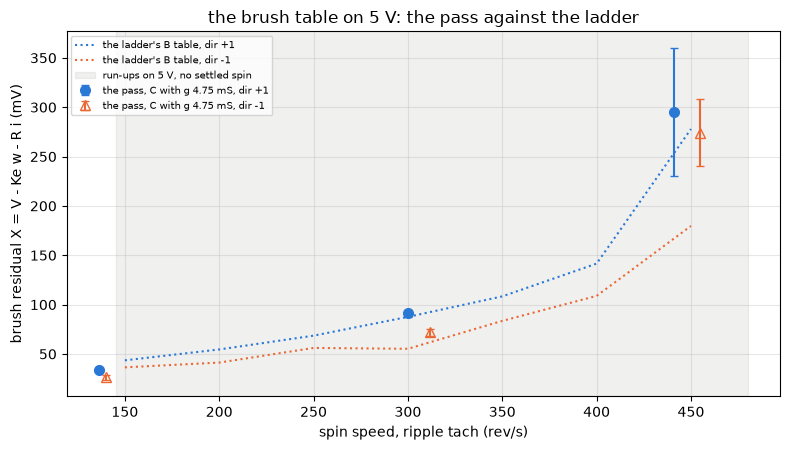

In [51]:
fig, ax = plt.subplots(figsize=(8, 4.6))
for d, c in ((1, BLUE), (-1, ORANGE)):
    g = RMP[RMP["dir"] == d].sort_values("rev_s")
    ax.errorbar(g["rev_s"], g["x_C"], yerr=g["x_C_sd"], capsize=3,
                **figures.direction_style(d, c), ms=7,
                label=f"the pass, C with g 4.75 mS, dir {d:+d}")
    lb = {float(k.split()[0]): (v["value"] if isinstance(v, dict) else v)
          for k, v in LONG_B[f"{d:+d}"].items()}
    kk = [k for k, v in lb.items() if v is not None]
    ax.plot(kk, [lb[k] for k in kk], ":", color=c,
            label=f"the ladder's B table, dir {d:+d}")
ax.axvspan(SETTLED_RM["rev_s"].max() + 5, 480, color=MUTED, alpha=0.12,
           label="run-ups on 5 V, no settled spin")
figures.label(ax, x="spin speed, ripple tach (rev/s)",
              y="brush residual X = V - Ke w - R i (mV)",
              title="the brush table on 5 V: the pass against the ladder")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. X per rung and direction under construction C with the meter's g, the rung's mean and sd, filled +1 and open -1, against the ladder's B table per direction dotted. The shaded band is where every 5 V spin of the pass is a run-up. The pass's 30 % points sit under the ladder's first knots, its 60 % points on or over the ladder's curves and its 100 % points over them with an sd of 33.8 and 65.0 mV.

In [52]:
T_KD = S[(S["pass_rung"] | S["alt_rung"]) & TACH_OK]
drop = T_KD[T_KD["dropout_rows"] > 0]
print(f"{len(drop)} of {len(T_KD)} spins carry dropout rows: " + ", ".join(
    f"{r['duty']} % {r['dir']:+d} ({r['dropouts_per_s']:.0f}/s, window "
    f"{r['window_ms']:.0f} ms)" for _, r in drop.iterrows()))
# the ladder's fit X = S(rung) + k_d x rate over the pass's spins
keys = pd.factorize(T_KD["duty"])[0]
design = np.zeros((len(T_KD), keys.max() + 2))
design[np.arange(len(T_KD)), keys] = 1      # one level per rung
design[:, -1] = T_KD["dropouts_per_s"].to_numpy()
y = T_KD["x_C g meter_mv"].to_numpy()
beta = np.linalg.lstsq(design, y, rcond=None)[0]
res = y - design @ beta
KD_DOF = len(y) - design.shape[1]
cov = np.linalg.pinv(design.T @ design) * (res @ res / max(KD_DOF, 1))
KD_FIT = (float(beta[-1]), float(np.sqrt(cov[-1, -1])))
KD_LONG = LAD["k_d_mv_per_dropout_s"]["B"]
print(f"k_d over the pass's spins {KD_FIT[0]:+.3f} +/- {KD_FIT[1]:.3f} mV "
      f"per dropout/s (dof {KD_DOF}); the ladder's {KD_LONG['value']:+.2f}"
      f" +/- {KD_LONG['hi'] - KD_LONG['value']:.2f}")

3 of 25 spins carry dropout rows: 100 % +1 (39/s, window 26 ms), 100 % +1 (39/s, window 26 ms), 100 % -1 (39/s, window 26 ms)
k_d over the pass's spins +1.935 +/- 0.309 mV per dropout/s (dof 19); the ladder's +0.78 +/- 0.12


In [53]:
ru = S[S["set"].str.startswith("runup")]
DR = ru.groupby(["set", "dir"]).agg(
    rows=("dropout_rows", "sum"), rows_20=("dropout_rows_last20", "sum"),
    spin_s=("window_ms", lambda s: s.sum() / 1e3),
    n=("k", "size")).reset_index()
DR["rate_window"] = DR["rows"] / DR["spin_s"]          # rows per s
DR["rate_last20"] = DR["rows_20"] / (DR["n"] * 0.020)  # the last 20 ms
show(DR, n=None)
DR_AT = DR.set_index(["set", "dir"])["rate_last20"]
QUOTED = RUNUP["dropouts_last20ms_per_s_by_direction_and_set"]
print("the run-up notebook's last-20-ms rates: " + ", ".join(
    f"{k} {v['value']:.0f}" for k, v in QUOTED.items()))
ref = S[S["set"].str.startswith("ref")]
print(f"the 30 % reference rung: {int(ref['dropout_rows'].sum())} dropout "
      f"rows in {len(ref)} spins over three sittings")

,set,dir,rows,rows_20,spin_s,n,rate_window,rate_last20
0,runup-close-1,-1,1,1,0.078,3,12.887,16.667
1,runup-close-1,1,8,7,0.078,3,103.093,116.667
2,runup-close-6,-1,0,0,0.078,3,0.000,0.000
3,runup-close-6,1,15,15,0.078,3,193.299,250.000
4,runup-close-7,-1,1,1,0.077,3,12.912,16.667
5,runup-close-7,1,13,12,0.078,3,167.310,200.000
6,runup-open-1,-1,1,1,0.078,3,12.887,16.667
7,runup-open-1,1,2,2,0.078,3,25.790,33.333
8,runup-open-6,-1,0,0,0.077,3,0.000,0.000
9,runup-open-6,1,12,10,0.078,3,154.739,166.667


the run-up notebook's last-20-ms rates: -1 runup-close-1 17, +1 runup-close-1 100, -1 runup-close-6 0, +1 runup-close-6 200, -1 runup-open-1 17, +1 runup-open-1 33, -1 runup-open-6 0, +1 runup-open-6 133
the 30 % reference rung: 0 dropout rows in 36 spins over three sittings


Three of the 25 spins with a tach carry dropout rows, all at 100 %, two +1 and one -1, at 39 per s over 26 ms windows. A fit of X = S(rung) + k_d x rate over the pass's spins returns +1.935 +/- 0.309 mV per dropout/s on 19 degrees of freedom. Its lever is the run-ups' direction split and their acceleration, not a brush term, since the only dropout rows sit in unsettled 100 % windows. On one rail inside one travel the pass does not identify k_d. The ladder's own +0.78 +/- 0.12 stays a candidate.

What the pass hands instead is the dropout reference, the 100 % run-up's dropout rows per second over the drive's last 20 ms. In sitting 1 it reads 33.333 per s at the open and 116.667 at the close for +1, against the run-up notebook's 33 and 100, and 16.667 for -1 at both. Sittings 6 and 7 read 166.667 to 250.000 for +1. The 30 % reference rung reads 0 dropout rows in 36 spins. A later notebook on the compensation, its analysis still pending, wants k_d near zero. The hand-off carries no k_d and the reference in its place.

## 6. Step 3, the floor and the breakaway

The 8 % rung is the low ladder's kick, hold and coast. The 5 V holds at six levels bracket the floor. A hold kept turning when both the pot's slope over the hold's last stretch and the coast's early EMF read over the turning threshold. The kick from rest gives the breakaway's upper bound.

In [54]:
def kick_read(kick, d, zero_i):
    """(row): when the kick's pot left its seat, the current's peak up
    to then, the kick's effective volts and its end speed."""
    kd = tel.drive_rows(kick)
    pos = kd["pos"].to_numpy(float)
    ik = ((kd["current_raw"].to_numpy(float) - zero_i
           - SC.drive_offset_counts) / SC.counts_per_a)
    moved = np.flatnonzero(np.abs(pos - pos[0]) > POT_MOVE_COUNTS)
    row = {}
    if len(moved):
        m = int(moved[0])
        box = (np.convolve(ik[:m + 1], np.ones(5) / 5, mode="same")
               if m >= 5 else ik[:m + 1])   # a 0.25 ms box on the current
        row["break_ms"], row["i_break_peak_a"] = m / FS * 1e3, box.max()
    else:
        row["break_ms"], row["i_break_peak_a"] = np.nan, ik.max()
    half = float(kd["duty_counts"].abs().median())
    taps = ((kd["vmotor_a"] - kd["vmotor_b"]) * d).to_numpy(float)
    row["kick_v_eff_v"] = float(half / ARR * SC.volts(
        taps[-1000:], SC.terminal_offset_counts).mean())
    for scale in ("nominal", "table"):
        row[f"kick_end_rev_s_{scale}"] = pot_speed_rev_s(pos[-1000:],
                                                         scale)[0] * d
    return row

In [55]:
def hold_read(hold, d, zero_i, rail):
    """(row): the hold's last 400 ms: effective volts, current, the pot's
    speed both ways and the ripple tach seeded by the pot."""
    ticks = hold["duty_counts"].abs()
    half = float(ticks.iloc[-1])
    held = hold[ticks == half]
    D = half / ARR
    tail = held.iloc[-HOLD_TAIL_ROWS:]
    taps = ((tail["vmotor_a"] - tail["vmotor_b"]) * d).to_numpy(float)
    v_on = SC.volts(taps, SC.terminal_offset_counts)
    raw = tail["current_raw"].to_numpy(float)
    pos = tail["pos"].to_numpy(float)
    w_nom, _, mid = pot_speed_rev_s(pos, "nominal")
    row = {"duty_pct": 100 * D, "hold_rows": len(held),
           "window_valid_share": float(held["window_valid"].mean()),
           "v_eff_cmd_v": D * rail, "v_eff_tap_v": float(D * v_on.mean()),
           "i_hold_a": float(((raw - zero_i - SC.drive_offset_counts)
                              / SC.counts_per_a).mean()),
           "pot_rev_s": w_nom * d, "pot_mid_counts": mid,
           "pot_rev_s_table": pot_speed_rev_s(pos, "table")[0] * d}
    seed = abs(w_nom) * PER_REV            # Hz, the pot's ripple line
    f, n = np.nan, 0
    if seed > SEED_MIN_HZ:
        try:
            f, n = ripple.count_cycles(raw - raw.mean(), seed)
        except ValueError:                 # a seed the band cannot take
            f, n = np.nan, 0
    row.update(ripple_rev_s=f / PER_REV, ripple_cycles=n)
    return row

In [56]:
def hold_cycle(info):
    """(rows): one low cycle, kick, hold and coast per direction."""
    folder = LOW_DIR / info["folder"]
    df, zero_i, zero_e = load_sweep(folder)
    rail = float(probe_for(folder)["rail_v"])
    segs = {int(s): g for s, g in df.groupby("seg")}
    rows = []
    for first in (1, 4):                  # the +1 and the -1 triplets
        kick, hold, co = segs[first], segs[first + 1], segs[first + 2]
        d = int(kick["dir"].iloc[0])
        row = {"k": int(info["k"]), "rail_v": rail, "dir": d,
               "t_start": float(info["t_start"]),
               "t_end": float(info["t_end"]),
               **kick_read(kick, d, zero_i),
               **hold_read(hold, d, zero_i, rail)}
        emf = coast.emf_from_cut(co, d, coast.cut_row(co), zero_e,
                                 v_per_count=SC.v_per_count)
        row["e_first_rev_s"] = (float(coast.early_emf(emf))
                                / (KE_LONG["value"] * 1e-3))
        row["turning_pot"] = bool(abs(row["pot_rev_s"]) >= TURN_REV_S)
        row["turning_emf"] = bool(row["e_first_rev_s"] >= TURN_REV_S)
        row["kept_turning"] = row["turning_pot"] and row["turning_emf"]
        pk, pc = kick["pos"].to_numpy(float), co["pos"].to_numpy(float)
        row.update(pos_kick_start=pk[0],
                   pos_coast_end=float(np.median(pc[-200:])),
                   kick_ms=len(kick) / FS * 1e3,
                   hold_ms=len(hold) / FS * 1e3)
        rows.append(row)
    return rows

In [57]:
cy = pd.read_csv(LOW_DIR / "cycles.csv")
H = pd.DataFrame([r for _, info in cy[cy["volts_set"] == RAIL_V].iterrows()
                  for r in hold_cycle(info)])
LV = H.groupby("duty_pct").agg(
    v_eff=("v_eff_cmd_v", "mean"), v_tap=("v_eff_tap_v", "mean"),
    valid=("window_valid_share", "mean"), n=("kept_turning", "size"),
    n_turn=("kept_turning", "sum"),
    pot=("pot_rev_s", lambda s: s.abs().mean()),
    pot_table=("pot_rev_s_table", lambda s: s.abs().mean()),
    emf=("e_first_rev_s", "mean"),
    i_ma=("i_hold_a", lambda s: s.mean() * 1e3),
    ripple=("ripple_rev_s", "mean")).reset_index()
LV = LV.sort_values("duty_pct", ascending=False)
print(f"{len(H)} holds at {len(LV)} levels on 5 V")
show(LV, n=None)
NEVER_V = LV[LV["n_turn"] == 0]["v_eff"].max()     # highest never turned
ALWAYS_V = LV[LV["n_turn"] == LV["n"]]["v_eff"].min()   # lowest always
print(f"never turned at {NEVER_V:.3f} V, always turned at "
      f"{ALWAYS_V:.3f} V; the ladder's 5 V bracket "
      f"{LAD['floor_by_level']['5 V']['never_turned_v']['value']:.3f} to "
      f"{LAD['floor_by_level']['5 V']['always_turned_v']['value']:.3f}")

36 holds at 6 levels on 5 V


,duty_pct,v_eff,v_tap,valid,n,n_turn,pot,pot_table,emf,i_ma,ripple
5,12.000,0.599,0.590,1.000,6,6,40.937,43.096,43.030,68.808,41.996
4,10.000,0.498,0.492,1.000,6,6,30.242,32.128,30.842,63.761,31.659
3,8.000,0.399,0.394,1.000,6,6,19.964,20.627,22.145,60.003,20.356
2,6.000,0.300,0.272,1.000,6,0,0.005,0.006,-0.660,71.594,NaN
1,5.000,0.249,0.132,0.000,6,0,0.003,0.003,-0.850,59.986,NaN
0,4.000,0.200,0.045,0.000,6,0,0.008,0.008,-0.205,51.372,NaN


never turned at 0.300 V, always turned at 0.399 V; the ladder's 5 V bracket 0.300 to 0.399


In [58]:
x_v = H["v_eff_cmd_v"].to_numpy()
y_t = H["kept_turning"].to_numpy(float)


def nll(p, x=x_v, y=y_t):
    """The logistic's negative log likelihood over the holds."""
    z = (x - p[0]) / max(p[1], 1e-3)
    pr = np.clip(1 / (1 + np.exp(-z)), 1e-6, 1 - 1e-6)
    return -(y * np.log(pr) + (1 - y) * np.log(1 - pr)).sum()


LOGIT = minimize(nll, [0.33, 0.02], method="Nelder-Mead").x
rng = np.random.default_rng(0)          # a fixed seed for the bootstrap
mids = []
for _ in range(300):
    idx = rng.integers(0, len(x_v), len(x_v))
    mids.append(minimize(nll, LOGIT, args=(x_v[idx], y_t[idx]),
                         method="Nelder-Mead").x[0])
BOOT = (np.percentile(mids, 16), np.percentile(mids, 84))
FLOOR_V = float(np.clip(LOGIT[0], NEVER_V, ALWAYS_V))
print(f"logistic midpoint {LOGIT[0]:.3f} V, scale {LOGIT[1]:.4f} V, "
      f"bootstrap 68 % {BOOT[0]:.3f} to {BOOT[1]:.3f}; carried "
      f"{FLOOR_V:.3f} V; the ladder's three-rail floor "
      f"{FLOOR_LONG['value']:.3f} [{FLOOR_LONG['lo']:.3f}, "
      f"{FLOOR_LONG['hi']:.3f}]")
G_FLOOR = grade("floor (pass, 5 V)", FLOOR_V, (ALWAYS_V - NEVER_V) / 2,
                FLOOR_LONG["value"],
                (FLOOR_LONG["hi"] - FLOOR_LONG["lo"]) / 2, "V eff",
                "brackets, half the never-always gap each")
print(f"graded as brackets: gap {G_FLOOR['gap_pct']:+.1f} %, "
      f"{G_FLOOR['gap_sigma']:+.2f} half-brackets")

logistic midpoint 0.350 V, scale 0.0005 V, bootstrap 68 % 0.350 to 0.350; carried 0.350 V; the ladder's three-rail floor 0.340 [0.300, 0.399]
graded as brackets: gap +2.9 %, +0.14 half-brackets


In [59]:
TURNED = H[H["kept_turning"]]
AT_FLOOR = TURNED[TURNED["v_eff_cmd_v"] < 0.42]     # the 8 % holds
CRAWL = TURNED[(TURNED["v_eff_cmd_v"] > 0.45)
               & (TURNED["v_eff_cmd_v"] < 0.55)]    # the 10 % holds


def speeds(g):
    return {"pot_nominal": g["pot_rev_s"].abs().mean(),
            "pot_table": g["pot_rev_s_table"].abs().mean(),
            "ripple": g["ripple_rev_s"].mean(),
            "emf": g["e_first_rev_s"].mean()}


SLOW, CRAWL_W = speeds(AT_FLOOR), speeds(CRAWL)
for name, g, w in (("slowest, 8 %", AT_FLOOR, SLOW),
                   ("crawl, 10 %", CRAWL, CRAWL_W)):
    print(f"{name}: " + ", ".join(f"{k} {v:.1f}" for k, v in w.items())
          + f" rev/s; ripple sd {g['ripple_rev_s'].std():.1f}, pot sd "
          f"{g['pot_rev_s'].abs().std():.1f}; {g['i_hold_a'].mean() * 1e3:.1f}"
          f" mA crest (n {len(g)})")
print(f"the ladder's crawl_speed_rev_s {LAD['crawl_speed_rev_s']['value']:.1f}"
      f" and floor speed "
      f"{LAD['floor_speed_at_lowest_turning_level_rev_s']['value']:.1f}, "
      f"nominal pot, three rails")
LINE = results.fit_line(TURNED["v_eff_cmd_v"], TURNED["pot_rev_s"].abs())
LINE_T = results.fit_line(TURNED["v_eff_cmd_v"],
                          TURNED["pot_rev_s_table"].abs())
print(f"speed on V_eff over the turning holds {LINE['slope']:.1f} +/- "
      f"{LINE['slope_se']:.1f} rev/s per V nominal ({LINE_T['slope']:.1f}"
      f" through the table), zero at "
      f"{-LINE['intercept'] / LINE['slope']:.3f} V; the ladder's "
      f"{LAD['crawl_speed_on_v_eff_rev_s_per_v']['value']:.1f}")

slowest, 8 %: pot_nominal 20.0, pot_table 20.6, ripple 20.4, emf 22.1 rev/s; ripple sd 3.3, pot sd 3.1; 60.0 mA crest (n 6)
crawl, 10 %: pot_nominal 30.2, pot_table 32.1, ripple 31.7, emf 30.8 rev/s; ripple sd 1.1, pot sd 1.0; 63.8 mA crest (n 6)
the ladder's crawl_speed_rev_s 31.8 and floor speed 19.6, nominal pot, three rails
speed on V_eff over the turning holds 104.9 +/- 5.6 rev/s per V nominal (112.4 through the table), zero at 0.209 V; the ladder's 99.6


In [60]:
KICKS = H[H["dir"] == 1]                 # the +1 kicks, from rest
print(f"the kick {KICKS['kick_ms'].mean():.0f} ms, then the hold "
      f"{KICKS['hold_ms'].mean() / 1e3:.1f} s")
print(f"every kick at {KICKS['kick_v_eff_v'].mean():.2f} V effective "
      f"moved; the pot left its seat {KICKS['break_ms'].mean():.1f} sd "
      f"{KICKS['break_ms'].std():.1f} ms in at a peak of "
      f"{KICKS['i_break_peak_a'].mean() * 1e3:.0f} mA (n {len(KICKS)})")
print(f"the kick's end speed +1: nominal "
      f"{KICKS['kick_end_rev_s_nominal'].mean():.0f}, table "
      f"{KICKS['kick_end_rev_s_table'].mean():.0f} rev/s; the ladder's "
      f"{LAD['kick_end_speed_rev_s']['+1']['value']:.0f} (nominal)")
BA_LAD = LAD["breakaway_v_effective_bounds"]
print(f"bounded: {NEVER_V:.3f} < V_eff <= {KICKS['kick_v_eff_v'].mean():.2f}"
      f"; the ladder's bounds {BA_LAD['lo']:.3f} to {BA_LAD['hi']:.2f}")

the kick 150 ms, then the hold 1.2 s
every kick at 1.46 V effective moved; the pot left its seat 9.3 sd 1.6 ms in at a peak of 317 mA (n 18)
the kick's end speed +1: nominal 131, table 129 rev/s; the ladder's 130 (nominal)
bounded: 0.300 < V_eff <= 1.46; the ladder's bounds 0.300 to 1.45


36 holds at 6 levels. At 6 % (0.300 V effective) no hold kept turning, 0 of 6, and at 8 % (0.399 V) every hold did, 6 of 6. The logistic's midpoint lands at 0.350 V with a scale of 0.0005 V, perfect separation, so the bracket of 0.300 to 0.399 V is the number and the midpoint only its center. The ladder read the same bracket on 5 V, and its three-rail logistic at 0.340 V sits inside it. The 5 and 4 % holds sit under the tap window floor, window_valid 0, so they give turning or stopped and no current or volts.

The slowest sustained speed, the 8 % holds, reads 20.4 rev/s at the motor by the ripple tach (sd 3.3), 20.0 by the pot at its nominal scale and 20.6 through the pot table. At 10 % (0.498 V) the crawl reads 31.7 by the ripple tach, 30.2 nominal and 32.1 through the table, on 63.8 mA crest. The speed's line on the effective volts over the turning holds is 104.9 +/- 5.6 rev/s per V on the nominal pot and 112.4 through the table, zero at 0.209 V, against the ladder's 99.6 pooled over three rails on the nominal pot.

The breakaway is bounded, not measured. Every kick at 1.46 V effective, 150 ms at the kick's duty, moved, the pot leaving its seat 9.3 ms in (sd 1.6) at a current peak of 317 mA. A rotor stopped at 0.300 V never restarted within its hold. So 0.300 < V_eff <= 1.46 V, against the ladder's bounds of 0.300 to 1.45. A sweep of pulses from rest between the two measures it.

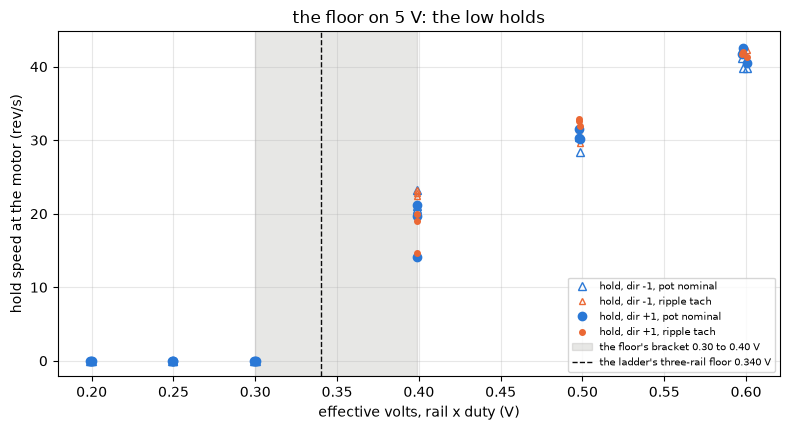

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for d, g in H.groupby("dir"):
    ax.plot(g["v_eff_cmd_v"], g["pot_rev_s"].abs(),
            **figures.direction_style(d, BLUE), ms=6,
            label=f"hold, dir {d:+d}, pot nominal")
    ax.plot(g["v_eff_cmd_v"], g["ripple_rev_s"],
            **figures.direction_style(d, ORANGE), ms=4,
            label=f"hold, dir {d:+d}, ripple tach")
ax.axvspan(NEVER_V, ALWAYS_V, color=MUTED, alpha=0.2,
           label=f"the floor's bracket {NEVER_V:.2f} to {ALWAYS_V:.2f} V")
ax.axvline(FLOOR_LONG["value"], color=INK, lw=1, ls="--",
           label=f"the ladder's three-rail floor {FLOOR_LONG['value']:.3f} V")
figures.label(ax, x="effective volts, rail x duty (V)",
              y="hold speed at the motor (rev/s)",
              title="the floor on 5 V: the low holds")
ax.legend(fontsize=7)
figures.finish(fig)

What you are looking at. Each 5 V hold's speed at the motor against its effective volts, the pot at its nominal scale in blue and the ripple tach in orange, filled +1 and open -1, the floor's bracket shaded and the ladder's three-rail floor dashed. Nothing turns at or under 0.300 V and everything turns from 0.399 V. Graded as brackets, with half the never-to-always gap as each side's sigma, the pass's floor sits +2.9 % from the ladder's, 0.14 of that.

## 7. The cost

The cost of the pass is its wall time, its motor revolutions and the heat it leaves. The wall time comes from the runner's timestamps, so it is the time as the sitting's runner paced it, with its rests torque off between cycles. The revolutions come from the pot through the table's map for the spins and from the coast's EMF over Ke for the coasts.

In [62]:
REST_S = 20.0            # s, the runner's rest between cycles (README)
QUICK_REST_S = 5.0       # s, the shorter rest the pass is costed with
BURST_REST_S = 0.15      # s, the bursts' rest, the inductance plan's
# the README's budget: step 1 about a minute, step 2 about 30 s, step 3
# about 3 minutes and 1500 motor revolutions
README_MIN = {"1": 1.0, "2": 0.5, "3": 3.0}
README_REVS = 1500
print(f"the README's budget: " + ", ".join(
    f"step {k} {v:g} min" for k, v in README_MIN.items()) + f", "
      f"{sum(README_MIN.values()):.1f} min in all, {README_REVS} revs")
WARM = RES["warming_pct_per_j"]["value"]   # % of R per J, no cooling
four = CHAINS[CHAINS["k"] < 4]
SPAN1 = four["t_end"].max() - four["t_start"].min()
SWEEP1 = (four["t_end"] - four["t_start"]).mean()
J1 = ST.groupby("chain")["joules"].sum().mean()
print(f"step 1: {3 * STEP_S:.1f} s of drive a chain, the sweep "
      f"{SWEEP1:.1f} s, chain to chain {np.diff(four['t_start']).mean():.1f}"
      f" s, the four span {SPAN1:.0f} s ({SPAN1 / 60:.1f} min); "
      f"{J1:.2f} J a chain, {4 * J1:.2f} J in four; the seek press "
      f"{RES['stop_seek_amps']['value']:.2f} A")
marks = pd.read_csv(BURST_DIR / "marks.csv").set_index("mark")["t_host"]
SPAN2 = marks["rest"] - marks["g1-fwd-25"]
print(f"step 2: the four groups span {SPAN2:.1f} s on the host; 12 bursts "
      f"at {BURST_REST_S * 1e3:.0f} ms rests {12 * BURST_REST_S:.1f} s; "
      f"9 periods a burst, {9 * T_PERIOD * 1e3:.2f} ms of drive")

the README's budget: step 1 1 min, step 2 0.5 min, step 3 3 min, 4.5 min in all, 1500 revs
step 1: 0.9 s of drive a chain, the sweep 28.0 s, chain to chain 48.4 s, the four span 172 s (2.9 min); 0.37 J a chain, 1.49 J in four; the seek press 0.52 A
step 2: the four groups span 11.8 s on the host; 12 bursts at 150 ms rests 1.8 s; 9 periods a burst, 0.45 ms of drive


In [63]:
rows = []
for d, g in S[S["pass_rung"]].groupby("duty"):
    rows.append({
        "duty": int(d), "n": len(g), "spin_s": g["spin_ms"].mean() / 1e3,
        "coast_to_stop_s": g["stop_ms"].mean() / 1e3,
        "revs_spin_pot": travel_revs(g["pos_spin_start"],
                                     g["pos_spin_end"]).mean(),
        "revs_spin_tach_x_t": (g["spin_rev_s"] * g["spin_ms"] / 1e3).mean(),
        "revs_coast_emf": g["coast_revs_emf"].mean(),
        "revs_pot": travel_revs(g["pos_spin_start"],
                                g["pos_coast_end"]).mean(),
        "joules": (g["i_crest_a"] ** 2 * R_PASS * g["spin_ms"] / 1e3).mean(),
        "cycle_span_s": (g["t_end"] - g["t_start"]).mean()})
h = H[H["duty_pct"].round() == 8]        # the 8 % rung: kick, hold, coast
i_kick = KICKS["i_break_peak_a"].mean()  # A, the kick's peak, an upper bound
revs8 = travel_revs(h["pos_kick_start"], h["pos_coast_end"]).mean()
rows.insert(0, {
    "duty": 8, "n": len(h), "spin_s": (h["kick_ms"] + h["hold_ms"]).mean()
    / 1e3, "coast_to_stop_s": np.nan, "revs_spin_pot": revs8,
    "revs_spin_tach_x_t": (h["ripple_rev_s"].abs() * h["hold_ms"]
                           / 1e3).mean(), "revs_coast_emf": 0.0,
    "revs_pot": revs8, "joules": (h["i_hold_a"] ** 2 * R_PASS * h["hold_ms"]
                                  / 1e3 + i_kick ** 2 * R_PASS
                                  * h["kick_ms"] / 1e3).mean(),
    "cycle_span_s": (h["t_end"] - h["t_start"]).mean()})
CR = pd.DataFrame(rows)
show(CR, n=None)

,duty,n,spin_s,coast_to_stop_s,revs_spin_pot,revs_spin_tach_x_t,revs_coast_emf,revs_pot,joules,cycle_span_s
0,8,6,1.350,NaN,42.797,24.427,0.000,42.797,0.081,59.978
1,15,6,1.200,0.028,61.680,67.278,0.872,63.005,0.030,57.813
2,30,6,0.597,0.071,79.181,82.523,4.391,84.531,0.026,52.451
3,60,6,0.154,0.129,39.982,47.102,17.435,59.140,0.012,51.237
4,100,6,0.052,0.174,16.461,23.296,35.098,54.607,0.019,51.201


In [64]:
N_CYC = 3 * len(PASS_DUTIES)            # three cycles a rung
DRIVE3 = (CR["spin_s"] * 6).sum()       # six spins a rung
REVS3 = (CR["revs_pot"] * 6).sum()
SPAN3 = CR["cycle_span_s"].sum() * 3 + REST_S * (N_CYC - 1)
br = S[S["set"].isin(["ref-open-1", "ref-close-1", "runup-open-1",
                      "runup-close-1"])]
REVS_BR = travel_revs(br["pos_spin_start"], br["pos_coast_end"]).sum()
COST = pd.DataFrame([
    {"step": "0 rest", "drive_s": 0.0, "wall_s": README_REST_S,
     "revs": 0.0, "joules": 0.0},
    {"step": "1 chains x4", "drive_s": 4 * 3 * STEP_S, "wall_s": SPAN1,
     "revs": 0.0, "joules": 4 * J1},
    {"step": "2 bursts x12", "drive_s": 12 * 9 * T_PERIOD + STEP_S,
     "wall_s": SPAN2, "revs": 0.0,
     "joules": I_LEVELS[0] ** 2 * R_PASS * STEP_S},
    {"step": "3 rungs x5x6", "drive_s": DRIVE3, "wall_s": SPAN3,
     "revs": REVS3, "joules": (CR["joules"] * 6).sum()},
    {"step": "brackets", "drive_s": br["spin_ms"].sum() / 1e3,
     "wall_s": (br["t_end"] - br["t_start"]).sum() + REST_S * 11,
     "revs": REVS_BR,
     "joules": (br["i_crest_a"] ** 2 * R_PASS * br["spin_ms"] / 1e3).sum()}])
COST["wall_min"] = COST["wall_s"] / 60
COST["r_rise_bound_pct"] = COST["joules"] * WARM
show(COST, n=None)
TOT = COST.iloc[:4].sum(numeric_only=True)
QUICK_S = (4 * (SWEEP1 - REST_S + QUICK_REST_S) + 12 * BURST_REST_S
           + README_REST_S + 30 * 1.0 + 29 * QUICK_REST_S)
print(f"{N_CYC} cycles in step 3; steps 0-3: drive {TOT['drive_s']:.0f} s,"
      f" wall "
      f"{TOT['wall_s'] / 60:.1f} min as run, {TOT['revs']:.0f} revs (spins "
      f"{(CR['revs_spin_pot'] * 6).sum():.0f}, coasts "
      f"{(CR['revs_coast_emf'] * 6).sum():.0f} by the EMF), "
      f"{TOT['joules']:.2f} J; with {QUICK_REST_S:.0f} s rests "
      f"{QUICK_S / 60:.1f} min; the copper's bound {WARM:.1f} % per J")

,step,drive_s,wall_s,revs,joules,wall_min,r_rise_bound_pct
0,0 rest,0.000,2.000,0.000,0.000,0.033,0.000
1,1 chains x4,3.600,172.018,0.000,1.490,2.867,7.388
2,2 bursts x12,0.305,11.782,0.000,0.084,0.196,0.417
3,3 rungs x5x6,20.118,1098.040,1824.478,1.010,18.301,5.009
4,brackets,7.788,1559.908,1685.731,0.522,25.998,2.586


15 cycles in step 3; steps 0-3: drive 24 s, wall 21.4 min as run, 1824 revs (spins 1441, coasts 347 by the EMF), 2.58 J; with 5 s rests 3.8 min; the copper's bound 5.0 % per J


In [65]:
s1 = S[S["set"].isin(["ref-open-1", "ref-close-1"])]
NTC_BR = s1.groupby("set")["ntc_c"].mean()
print(f"R by chain order {TREND['slope'] * 1e3:+.1f} +/- "
      f"{TREND['slope_se'] * 1e3:.1f} mohm per chain; step 3 over step 1 "
      f"{PER_C['warm_pct'].mean():+.2f} %")
print(f"the board NTC: ref-open-1 {NTC_BR['ref-open-1']:.2f} C, "
      f"ref-close-1 {NTC_BR['ref-close-1']:.2f} C; through the chains "
      f"{T0['lo']:.2f} to {T0['hi']:.2f} C")
J3 = (CR["joules"] * 6).sum()
print(f"step 3's copper joules {J3:.2f} J by the crest current, "
      f"{J3 * WARM:.1f} % of R with none leaving the copper")
print(f"the winding's heating tau {RES['meter_heating_tau_s']['value']:.2f}"
      f" s (resistance result); every rung starts after {REST_S:.0f} s")
print(f"one travel {SERVO.travel_deg_nominal:.0f} deg is "
      f"{SERVO.travel_deg_nominal / 360 * GEAR:.0f} motor revs")

R by chain order -2.3 +/- 3.6 mohm per chain; step 3 over step 1 +0.51 %
the board NTC: ref-open-1 26.01 C, ref-close-1 25.11 C; through the chains 25.95 to 26.06 C
step 3's copper joules 1.01 J by the crest current, 5.0 % of R with none leaving the copper
the winding's heating tau 3.39 s (resistance result); every rung starts after 20 s
one travel 184 deg is 157 motor revs


As the runner paced it, steps 0 to 3 take 21.4 min of wall time for 24 s of drive. The four chains span 172 s, 48.4 s chain to chain, each sweep 28.0 s around 0.9 s of drive. The bursts' four groups span 11.8 s. The five rungs take 18.3 min, 15 cycles of 51.2 to 60.0 s each with the runner's 20 s rests between them. With 5 s rests in place of the runner's 20 s the same pass costs about 3.8 min. That figure keeps the four chain sweeps with their rest cut to 5 s, the bursts and the 2 s rest, and counts step 3 as 30 spins of 1 s with 5 s between, so it leaves out the seeks inside each cycle and is a lower bound. The README budgets about 4.5 min in all, 1 min for step 1, 0.5 min for step 2 and 3 min for step 3. As run, the pass takes 21.4 min against that. With 5 s rests its lower bound fits, and a timed run with short rests gives the number (the next sitting's plan).

The revolutions are 1824, 1441 in the spins and 347 in the coasts by the EMF, against the README's 1500. The 15 and 30 % rungs are the long ones, 63.0 and 84.5 revs a spin and coast through the table, where one travel is 157 motor revs. The 60 % spin lasts 0.154 s and the 100 % spin 0.052 s, both cut by the runway, so their coasts carry 17.4 and 35.1 revs. The open and close brackets add 1686 revs.

The heat. The chains' R shows no trend over six chains, -2.3 +/- 3.6 mohm per chain. Within a chain step 3 reads +0.51 % over step 1, and the next chain opens at the same R. The board NTC reads 25.95 to 26.06 C through the chains, 26.01 C at the open's reference rung and 25.11 at the close's. Step 3's spins put 1.01 J into the winding by the crest current, 5.0 % of R if none of it left the copper. The winding's heating time constant is 3.39 s by the resistance result and every rung starts after a 20 s rest, so that bound sits far above what stays. The pass leaves the motor where it found it, to the chains' resolution.

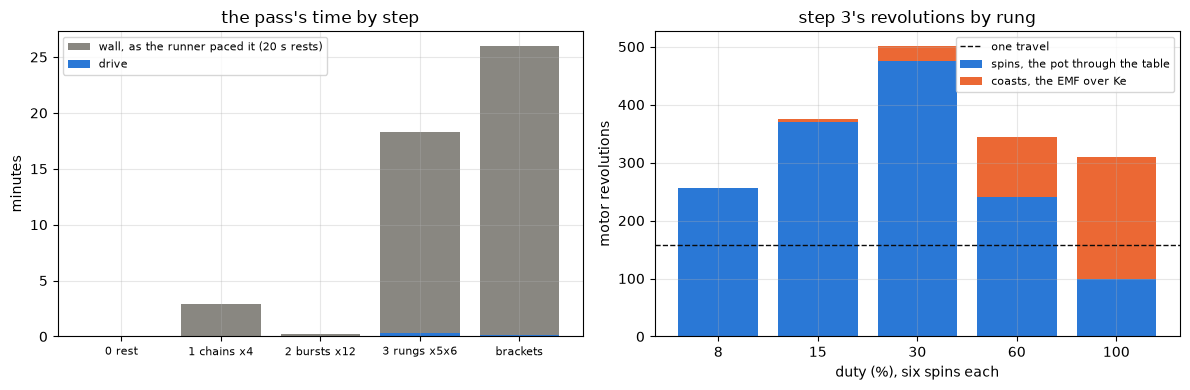

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(COST["step"], COST["wall_min"], color=MUTED,
          label="wall, as the runner paced it (20 s rests)")
ax[0].bar(COST["step"], COST["drive_s"] / 60, color=BLUE,
          label="drive")
ax[0].tick_params(axis="x", labelsize=8)
figures.label(ax[0], y="minutes", title="the pass's time by step")
ax[0].legend(fontsize=8)
duty = CR["duty"].astype(str)
ax[1].bar(duty, CR["revs_spin_pot"] * 6, color=BLUE,
          label="spins, the pot through the table")
ax[1].bar(duty, CR["revs_coast_emf"] * 6, bottom=CR["revs_spin_pot"] * 6,
          color=ORANGE, label="coasts, the EMF over Ke")
ax[1].axhline(SERVO.travel_deg_nominal / 360 * GEAR, color=INK, lw=1,
              ls="--", label="one travel")
figures.label(ax[1], x="duty (%), six spins each",
              y="motor revolutions", title="step 3's revolutions by rung")
ax[1].legend(fontsize=8)
figures.finish(fig)

What you are looking at. Left, each step's wall minutes as the runner paced it, with its drive minutes over it, and the open and close brackets beside. Right, step 3's motor revolutions per rung over its six spins, the spins by the pot through the table and the coasts by the EMF on top, against one travel. The rests set the wall time, not the drive.

## 8. Repeatability

The pass repeats at the open and the close of sitting 1 in the brackets, the 30 % reference rung and the 100 % run-up. The same brackets ran in sittings 6 and 7. Per block and direction the gated coasts give the speed by the tach, the crest current and Ke.

In [67]:
def block(g):
    """Means and sds of one bracket block's gated coasts."""
    return {"speed": g["spin_rev_s"].mean(), "speed_sd": g["spin_rev_s"].std(),
            "i_ma": g["i_crest_a"].mean() * 1e3,
            "i_sd_ma": g["i_crest_a"].std() * 1e3,
            "ke": g["ke_mv_per_rev_s"].mean(),
            "ke_sd": g["ke_mv_per_rev_s"].std(), "n": len(g),
            "dropouts": int(g["dropout_rows"].sum()),
            "t": g["t_start"].mean(), "ntc": g["ntc_c"].mean(),
            "x_c": g["x_C g meter_mv"].mean()}


BLOCK_NAMES = [n for n in SET_NAMES if n != "capture-1"]
gated = S[S["ke_gate"]]
BL = pd.DataFrame([{"block": n, "dir": d, **block(g)}
                   for n in BLOCK_NAMES for d in (1, -1)
                   for g in [gated[(gated["set"] == n)
                                   & (gated["dir"] == d)]]])
show(BL.drop(columns=["t"]), n=None)

,block,dir,speed,speed_sd,i_ma,i_sd_ma,ke,ke_sd,n,dropouts,ntc,x_c
0,ref-open-1,1,136.629,1.003,105.673,1.456,7.212,0.022,2,0,26.059,30.246
1,ref-open-1,-1,140.065,0.610,101.479,1.453,7.239,0.053,3,0,26.007,24.346
2,ref-close-1,1,138.254,0.514,99.604,0.848,7.251,0.049,3,0,25.110,45.772
3,ref-close-1,-1,141.611,0.721,96.770,1.379,7.258,0.045,3,0,25.110,34.046
4,runup-open-1,1,441.105,8.582,303.191,3.907,7.261,0.023,3,2,25.889,295.061
5,runup-open-1,-1,454.908,7.279,285.295,3.420,7.273,0.010,3,1,25.889,274.285
6,runup-close-1,1,444.728,6.908,283.311,2.478,7.269,0.013,3,8,25.029,361.896
7,runup-close-1,-1,456.858,0.315,281.389,1.379,7.294,0.021,3,1,25.029,278.090
8,ref-open-6,1,140.929,0.671,98.007,0.970,7.249,0.026,3,0,26.495,34.847
9,ref-open-6,-1,143.075,0.464,96.201,0.704,7.240,0.029,3,0,26.495,27.444


In [68]:
def change(a, b, key, sd_key, pct=True):
    """b against a, with the se from the two sds over root n."""
    se = np.hypot(a[sd_key] / np.sqrt(a["n"]), b[sd_key] / np.sqrt(b["n"]))
    if pct:
        return (b[key] / a[key] - 1) * 100, se / a[key] * 100
    return b[key] - a[key], se


B_AT = BL.set_index(["block", "dir"])
OPEN_CLOSE = {}
for kind, (o, c) in {"ref": ("ref-open-1", "ref-close-1"),
                     "runup": ("runup-open-1", "runup-close-1")}.items():
    for d in (1, -1):
        a, b = B_AT.loc[(o, d)], B_AT.loc[(c, d)]
        sp, cu, kv = (change(a, b, "speed", "speed_sd"),
                      change(a, b, "i_ma", "i_sd_ma", pct=False),
                      change(a, b, "ke", "ke_sd"))
        OPEN_CLOSE[(kind, d)] = {"speed_pct": sp, "i_ma": cu, "ke_pct": kv,
                                 "minutes": (b["t"] - a["t"]) / 60}
        print(f"{kind} {d:+d}: speed {sp[0]:+.2f} +/- {sp[1]:.2f} % "
              f"({sp[0] / sp[1]:+.1f} sigma), current {cu[0]:+.1f} +/- "
              f"{cu[1]:.1f} mA ({cu[0] / cu[1]:+.1f} sigma), Ke {kv[0]:+.2f}"
              f" +/- {kv[1]:.2f} % ({kv[0] / kv[1]:+.1f} sigma), over "
              f"{(b['t'] - a['t']) / 60:.0f} min")
lb = "bracket_{}_open_to_close_sitting1_{}_{:+d}"
print("the ladder's own brackets: speed " + " / ".join(
    f"{LAD[lb.format('speed', 'pct', d)]['value']:+.2f}" for d in (1, -1))
      + " %, current " + " / ".join(
    f"{LAD[lb.format('current', 'ma', d)]['value']:+.1f}" for d in (1, -1))
      + " mA, Ke " + " / ".join(
    f"{LAD[lb.format('ke', 'pct', d)]['value']:+.2f}" for d in (1, -1))
      + " %")

ref +1: speed +1.19 +/- 0.56 % (+2.1 sigma), current -6.1 +/- 1.1 mA (-5.3 sigma), Ke +0.55 +/- 0.45 % (+1.2 sigma), over 229 min
ref -1: speed +1.10 +/- 0.39 % (+2.8 sigma), current -4.7 +/- 1.2 mA (-4.1 sigma), Ke +0.26 +/- 0.55 % (+0.5 sigma), over 229 min
runup +1: speed +0.82 +/- 1.44 % (+0.6 sigma), current -19.9 +/- 2.7 mA (-7.4 sigma), Ke +0.11 +/- 0.21 % (+0.6 sigma), over 237 min
runup -1: speed +0.43 +/- 0.92 % (+0.5 sigma), current -3.9 +/- 2.1 mA (-1.8 sigma), Ke +0.29 +/- 0.19 % (+1.5 sigma), over 237 min
the ladder's own brackets: speed +1.59 / +1.10 %, current -7.2 / -4.7 mA, Ke +0.15 / +0.26 %


In [69]:
PAIRS_R = np.array([PER_C[PER_C["chain"].isin(p)]["r_ohm"].mean()
                    for p in ([0, 1], [2, 3], [4, 5])])
PAIRS_V0 = np.array([PER_C[PER_C["chain"].isin(p)]["v0_v"].mean()
                     for p in ([0, 1], [2, 3], [4, 5])])
PAIRS_SPREAD = (PAIRS_R.max() / PAIRS_R.min() - 1) * 100
print(f"the chains as three once-per-stop pairs (C): R "
      + ", ".join(f"{r:.4f}" for r in PAIRS_R) + f" ohm, spread "
      f"{PAIRS_SPREAD:.2f} % (sd "
      f"{PAIRS_R.std(ddof=1) / PAIRS_R.mean() * 100:.2f} %); V0 "
      + ", ".join(f"{v * 1e3:+.0f}" for v in PAIRS_V0) + " mV")
rp, r6 = PASS_R.loc["C g meter"], SIX_R.loc["C g meter"]
print(f"the pass's four against all six: {rp['r_ohm']:.4f} against "
      f"{r6['r_ohm']:.4f} ({(rp['r_ohm'] / r6['r_ohm'] - 1) * 100:+.2f} %); "
      f"low stop {rp['r_low']:.4f}, high {rp['r_high']:.4f} "
      f"({(rp['r_high'] / rp['r_low'] - 1) * 100:+.2f} %)")

the chains as three once-per-stop pairs (C): R 4.1578, 4.1642, 4.1425 ohm, spread 0.52 % (sd 0.27 %); V0 +35, +34, +35 mV
the pass's four against all six: 4.1610 against 4.1548 (+0.15 %); low stop 4.1546, high 4.1674 (+0.31 %)


In [70]:
rows = []
for kind in ("ref", "runup"):
    for sit in (1, 6, 7):
        g = gated[gated["set"].isin([f"{kind}-open-{sit}",
                                     f"{kind}-close-{sit}"])]
        b = block(g)
        b["dropouts_plus"] = int(g[g["dir"] == 1]["dropout_rows"].sum())
        rows.append({"kind": kind, "sitting": sit, **b})
AC = pd.DataFrame(rows)
show(AC.drop(columns=["t"]), n=None)
AC_AT = AC.set_index(["kind", "sitting"])
for kind in ("ref", "runup"):
    k1 = AC_AT.loc[(kind, 1)]
    for sit in (6, 7):
        k = AC_AT.loc[(kind, sit)]
        print(f"{kind} {sit} over 1: speed "
              f"{(k['speed'] / k1['speed'] - 1) * 100:+.2f} %, current "
              f"{k['i_ma'] - k1['i_ma']:+.1f} mA, Ke "
              f"{(k['ke'] / k1['ke'] - 1) * 100:+.2f} %; +1 dropout rows "
              f"{int(k1['dropouts_plus'])} -> {int(k['dropouts_plus'])}")
KE_SIT_SPREAD = AC["ke"].std(ddof=1) / AC[AC["kind"] == "ref"]["ke"].mean()
KE_SIT_SPREAD *= 100
print(f"Ke over the six blocks of three sittings: sd {KE_SIT_SPREAD:.2f} %")
print("J through the origin by set (run-up result): " + ", ".join(
    f"{k} {v['value'] * 1e9:.2f}" for k, v in RUNUP["j_origin_by_set"].items())
      + " e-9 kg m2")

,kind,sitting,speed,speed_sd,i_ma,i_sd_ma,ke,ke_sd,n,dropouts,ntc,x_c,dropouts_plus
0,ref,1,139.368,1.964,100.446,3.348,7.243,0.042,11,0,25.527,33.908,0
1,ref,6,141.704,1.533,97.314,1.539,7.251,0.029,12,0,26.558,32.459,0
2,ref,7,143.054,0.936,95.385,1.162,7.251,0.034,12,0,26.952,31.271,0
3,runup,1,449.400,8.938,288.296,9.440,7.274,0.020,12,12,25.459,302.333,10
4,runup,6,453.596,6.782,280.224,4.017,7.268,0.019,12,27,26.384,310.503,27
5,runup,7,454.744,8.025,276.977,4.592,7.258,0.033,12,28,26.693,319.222,25


ref 6 over 1: speed +1.68 %, current -3.1 mA, Ke +0.11 %; +1 dropout rows 0 -> 0
ref 7 over 1: speed +2.64 %, current -5.1 mA, Ke +0.12 %; +1 dropout rows 0 -> 0
runup 6 over 1: speed +0.93 %, current -8.1 mA, Ke -0.08 %; +1 dropout rows 10 -> 27
runup 7 over 1: speed +1.19 %, current -11.3 mA, Ke -0.23 %; +1 dropout rows 10 -> 25
Ke over the six blocks of three sittings: sd 0.16 %
J through the origin by set (run-up result): runup-open-1 6.53, runup-close-1 6.38, runup-open-6 6.44, runup-close-6 6.39 e-9 kg m2


In [71]:
VI_RAILS = {}
for rail, tag in ((3.7, "3v7"), (5.0, "5v"), (7.4, "7v4")):
    lo = RES[f"rails_vi_as_read_ohm_{tag}_low"]
    hi = RES[f"rails_vi_as_read_ohm_{tag}_high"]
    VI_RAILS[f"{rail} V"] = {"low": lo, "high": hi}
    a_lo = RES[f"rails_step_amps_{tag}_low"]["value"]
    a_hi = RES[f"rails_step_amps_{tag}_high"]["value"]
    scatter = RES[f"rails_chain_scatter_pct_{tag}"]["value"]
    print(f"{rail} V: V/I as read {lo['value']:.3f} at {a_lo:.3f} A, "
          f"{hi['value']:.3f} at {a_hi:.3f} A; chain scatter {scatter:.2f} %")
print(f"under C the rails and the lock on one line: chi2 "
      f"{RES['rails_chi2_c']['value']:.1f} over "
      f"{RES['rails']['fits']['C = B + g free']['dof']} dof, rms "
      f"{RES['rails_rms_mv_c']['value']:.1f} mV")
print(f"the sag's stop lap: V_eff / I as read "
      f"{SAG['r_stop_lap_ohm']['value']:.3f} ohm, sd "
      f"{SAG['r_stop_lap_sd_pct']['value']:.2f} %, "
      f"{SAG['r_stop_lap_per_v_ohm']['value']:+.4f} ohm per V of rail")

3.7 V: V/I as read 4.427 at 0.252 A, 4.399 at 0.379 A; chain scatter 0.56 %
5.0 V: V/I as read 4.420 at 0.259 A, 4.406 at 0.383 A; chain scatter 0.26 %
7.4 V: V/I as read 4.349 at 0.264 A, 4.376 at 0.388 A; chain scatter 0.93 %
under C the rails and the lock on one line: chi2 7.5 over 4 dof, rms 2.7 mV
the sag's stop lap: V_eff / I as read 4.344 ohm, sd 0.43 %, -0.0055 ohm per V of rail


Within sitting 1, close over open across 229 min, the reference rung runs +1.19 +/- 0.56 % faster for +1 and +1.10 +/- 0.39 % for -1, on -6.1 +/- 1.1 and -4.7 +/- 1.2 mA of crest current, -5.3 and -4.1 sigma, the servo running in as the ladder found. Its Ke moves +0.55 +/- 0.45 % and +0.26 +/- 0.55 %, not a finding. The run-up's current at the cut falls -19.9 +/- 2.7 mA for +1 and -3.9 +/- 2.1 for -1, its Ke moving +0.11 and +0.29 %. The ladder's own brackets read speed +1.59 and +1.10 % and current -7.2 and -4.7 mA.

The stop chains as three once-per-stop pairs read 4.1578, 4.1642 and 4.1425 ohm under C, a spread of 0.52 % (sd 0.27 %), with V0 +35, +34 and +35 mV. The pass's four chains read +0.15 % over all six. A user repeating the pass at the close of the same hours sees R within 0.52 %, Ke within 0.55 % and the free current 4.7 to 6.1 mA lower at the reference rung.

Across sittings, each sitting's two brackets pooled, the reference rung's speed grows +1.68 % by sitting 6 and +2.64 % by sitting 7 and its current falls 3.1 and 5.1 mA, the run-in, while Ke moves +0.11 and +0.12 %. Over the six bracket blocks of three sittings Ke's sd is 0.16 %. The run-up's +1 dropout rows grow from 10 in sitting 1 to 27 and 25, the brushes dropping out more after the locked sittings, as the run-up notebook found.

The bursts under the pass's design read 0.8432, 0.8399 and 0.8369 mH at the stop, the lock and the wound seat (section 3). The stop chains have no 5 V repeat in another sitting. As read, the resistance result's rail chains give 4.427 and 4.399 ohm at 3.7 V, 4.420 and 4.406 at 5 V and 4.349 and 4.376 at 7.4 V, chain scatter 0.26 to 0.93 %, and under C the three rails and the lock sit on one line with chi2 7.5 over 4 dof. A user on another supply most likely reads the same R under C with the same g, and a different R as read. The sag's stop lap reads 4.344 ohm as read, -0.0055 ohm per V of rail.

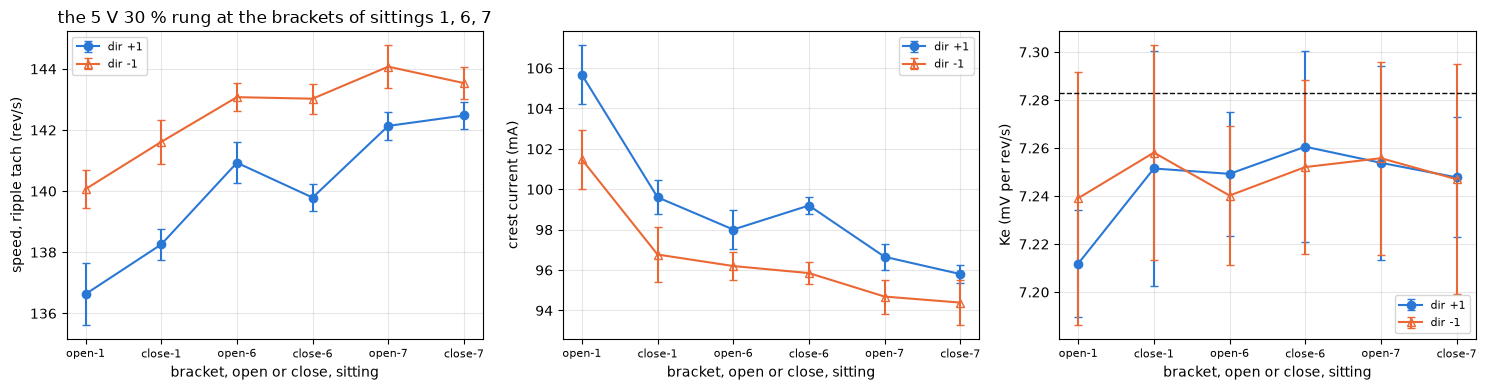

In [72]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
refs = BL[BL["block"].str.startswith("ref")]
for d, c in ((1, BLUE), (-1, ORANGE)):
    g = refs[refs["dir"] == d]
    x = np.arange(len(g))
    for a, col, sd in zip(ax, ("speed", "i_ma", "ke"),
                          ("speed_sd", "i_sd_ma", "ke_sd")):
        a.errorbar(x, g[col], yerr=g[sd], capsize=3, color=c,
                   marker=figures.DIRECTION_MARKER[d],
                   mfc=c if d == 1 else "none", label=f"dir {d:+d}")
names = [b.replace("ref-", "") for b in refs[refs["dir"] == 1]["block"]]
for a, y in zip(ax, ("speed, ripple tach (rev/s)", "crest current (mA)",
                     "Ke (mV per rev/s)")):
    a.set_xticks(range(len(names)), names, fontsize=8)
    figures.label(a, x="bracket, open or close, sitting", y=y)
    a.legend(fontsize=8)
ax[2].axhline(KE_LONG["value"], color=INK, lw=1, ls="--")
ax[0].set_title("the 5 V 30 % rung at the brackets of sittings 1, 6, 7")
figures.finish(fig)

What you are looking at. The 30 % reference rung at each bracket of sittings 1, 6 and 7, its speed, crest current and Ke per direction with their sd, the ladder's Ke dashed. Speed climbs and current falls bracket by bracket while Ke holds.

## 9. The pot scale

Every speed the ladder quoted through the pot went through the registry's nominal counts per degree. The pot-table notebook measured the pot against a camera tag and gives a counts-to-degrees table. This section applies that table to every rev/s read through the pot here and checks the result against the ripple tach, which does not use the pot.

The table first, since other notebooks read it too. Its `local_scale_counts_per_deg` column is the pot's fine texture from row to row, not a scale at a point. A speed or a lever scaled by that column at one position can be far off. The map from counts to degrees, read as an angle difference over a window's span, is the scale. Every pot speed in this notebook goes through the map.

In [73]:
AT_C = (1500, 1850, 2050, 2400)         # counts, four positions
print(f"nominal {POT_NOM} counts/deg; the table's mid travel "
      f"{POT_MID['value']:.3f} [{POT_MID['lo']:.3f}, {POT_MID['hi']:.3f}];"
      f" guard average "
      f"{POT['pot_scale_guard_average_counts_per_deg']['value']:.2f}; ends "
      f"{END_SLOPES[0]:.1f} / {END_SLOPES[1]:.1f}")
print("through the map over 200-count spans at " + " / ".join(
    str(c) for c in AT_C) + ": " + ", ".join(
    f"{span_slope(c):.2f}" for c in AT_C) + " counts/deg")
print("the local_scale column at the same points: " + ", ".join(
    f"{local_column_at(c):.1f}" for c in AT_C) + " counts/deg; over the "
      f"table {PT_LOCAL.min():.1f} to {PT_LOCAL.max():.1f}")
step = np.diff(PT_COUNTS)               # counts between table rows
print(f"the table's rows sit {np.median(step):.0f} counts apart (median)")

nominal 19.8 counts/deg; the table's mid travel 18.913 [18.826, 19.000]; guard average 19.76; ends 22.3 / 22.9
through the map over 200-count spans at 1500 / 1850 / 2050 / 2400: 19.23, 18.22, 17.51, 17.84 counts/deg
the local_scale column at the same points: 11.0, 14.6, 14.7, 18.0 counts/deg; over the table 10.9 to 28.9
the table's rows sit 19 counts apart (median)


In [74]:
ok = S["ke_gate"] & (S["spin_rev_s"] > 50) & S["settled"]
G = S[ok].copy()
G["over_nominal"] = G["spin_rev_s"] / G["pot_rev_s_nominal"].abs()
G["over_table"] = G["spin_rev_s"] / G["pot_rev_s_table"].abs()
G["span_slope"] = (G["pot_cps"].abs()   # counts/deg the window saw
                   / (G["pot_rev_s_table"].abs() * 360 / GEAR))
print(f"settled spins with a tach ({len(G)}): tach over pot nominal "
      f"{G['over_nominal'].mean():.4f} sd {G['over_nominal'].std():.4f}, "
      f"through the table {G['over_table'].mean():.4f} sd "
      f"{G['over_table'].std():.4f}; {G['pot_mid_counts'].min():.0f} to "
      f"{G['pot_mid_counts'].max():.0f} counts")
show(G.groupby("set").agg(n=("k", "size"), nominal=("over_nominal", "mean"),
                          table=("over_table", "mean"),
                          table_sd=("over_table", "std"),
                          pos=("pot_mid_counts", "mean"),
                          slope=("span_slope", "mean")).reset_index(),
     n=None)

settled spins with a tach (47): tach over pot nominal 1.0454 sd 0.0411, through the table 0.9774 sd 0.0284; 1686 to 3289 counts


,set,n,nominal,table,table_sd,pos,slope
0,capture-1,10,1.043,0.975,0.011,2105.736,18.507
1,ref-close-1,6,1.078,0.975,0.006,1924.015,17.944
2,ref-close-6,6,1.045,0.968,0.008,1948.586,18.346
3,ref-close-7,6,1.044,0.966,0.010,1914.230,18.313
4,ref-open-1,5,1.052,0.979,0.005,1944.810,18.421
5,ref-open-6,6,1.041,0.970,0.017,1911.895,18.458
6,ref-open-7,6,1.057,0.970,0.015,1950.747,18.196
7,runup-close-6,1,0.928,1.086,NaN,3289.360,23.162
8,runup-open-1,1,0.918,1.114,NaN,3204.425,24.027


In [75]:
GI = G[~G["set"].str.startswith("runup")]   # inside the table's span
POS_ALL = results.fit_line(G["pot_mid_counts"], G["over_table"])
POS_IN = results.fit_line(GI["pot_mid_counts"], GI["over_table"])
for name, f in (("all", POS_ALL), ("inside the table", POS_IN)):
    print(f"tach / pot (table) on position, {name}: "
          f"{f['slope'] * 1000:+.4f} +/- {f['slope_se'] * 1000:.4f} per 1000"
          f" counts ({f['slope'] / f['slope_se']:+.1f} sigma), n {f['n']}")
TACH_TABLE = (GI["over_table"].mean(),
              GI["over_table"].std() / np.sqrt(len(GI)))
COMM = POT["gear_ratio_commutation"]["value"] / GEAR   # tach per tag pot
print(f"inside: {len(GI)} windows at {GI['pot_mid_counts'].min():.0f} to "
      f"{GI['pot_mid_counts'].max():.0f} counts, through the table "
      f"{TACH_TABLE[0]:.4f} se {TACH_TABLE[1]:.4f}, nominal "
      f"{GI['over_nominal'].mean():.4f}")
print(f"the commutation count {POT['gear_ratio_commutation']['value']:.1f}"
      f" over the teeth's {GEAR:.2f} puts the tach at {COMM:.4f} of the "
      f"tag-calibrated pot; the spins read {TACH_TABLE[0]:.4f}, "
      f"{(1 - TACH_TABLE[0] / COMM) * 100:.1f} % under, where the window's "
      f"span slope reads {GI['span_slope'].mean():.2f} counts/deg")

tach / pot (table) on position, all: +0.0804 +/- 0.0066 per 1000 counts (+12.1 sigma), n 47
tach / pot (table) on position, inside the table: +0.0335 +/- 0.0086 per 1000 counts (+3.9 sigma), n 45
inside: 45 windows at 1686 to 2551 counts, through the table 0.9720 se 0.0017, nominal 1.0509
the commutation count 306.5 over the teeth's 308.05 puts the tach at 0.9951 of the tag-calibrated pot; the spins read 0.9720, 2.3 % under, where the window's span slope reads 18.33 counts/deg


In [76]:
TH = H[H["kept_turning"]].copy()
TH["ripple_over_nominal"] = TH["ripple_rev_s"] / TH["pot_rev_s"].abs()
TH["ripple_over_table"] = TH["ripple_rev_s"] / TH["pot_rev_s_table"].abs()
TH["emf_over_table"] = TH["e_first_rev_s"] / TH["pot_rev_s_table"].abs()
for c in ("ripple_over_nominal", "ripple_over_table", "emf_over_table"):
    print(f"turning holds ({len(TH)}): {c} {TH[c].mean():.4f} sd "
          f"{TH[c].std():.4f}")
FAC_HOLDS = TH["pot_rev_s_table"].abs() / TH["pot_rev_s"].abs()
print(f"the table over the nominal at the holds' "
      f"{TH['pot_mid_counts'].min():.0f} to {TH['pot_mid_counts'].max():.0f}"
      f" counts: x{FAC_HOLDS.mean():.4f} (sd {FAC_HOLDS.std():.4f}); "
      f"nominal over mid travel x{POT_NOM / POT_MID['value']:.4f}")

turning holds (18): ripple_over_nominal 1.0313 sd 0.0393
turning holds (18): ripple_over_table 0.9849 sd 0.0322
turning holds (18): emf_over_table 1.0215 sd 0.1644
the table over the nominal at the holds' 1051 to 2566 counts: x1.0481 (sd 0.0509); nominal over mid travel x1.0469


In [77]:
def check(name, value, sd, n, source):
    return {"check": name, "value": value, "sd": sd, "n": n,
            "source": source}


def half(x):
    return (x["hi"] - x["lo"]) / 2


RO, PC = LAD["ripple_over_pot"], RUNUP["pot_over_count_15_45ms"]
CROSS = pd.DataFrame([
    check("tach / pot, settled spins, nominal", GI["over_nominal"].mean(),
          GI["over_nominal"].std(), len(GI), "this pass"),
    check("tach / pot, settled spins, table", GI["over_table"].mean(),
          GI["over_table"].std(), len(GI), "this pass"),
    check("ripple / pot, turning holds, nominal",
          TH["ripple_over_nominal"].mean(), TH["ripple_over_nominal"].std(),
          len(TH), "this pass"),
    check("ripple / pot, turning holds, table",
          TH["ripple_over_table"].mean(), TH["ripple_over_table"].std(),
          len(TH), "this pass"),
    check("EMF / pot, turning holds, table", TH["emf_over_table"].mean(),
          TH["emf_over_table"].std(), len(TH), "this pass"),
    check("ladder ripple_over_pot (nominal)", RO["value"], half(RO),
          np.nan, "ladder"),
    check("steps pot_over_tach (nominal), as tach / pot",
          1 / STEPS["pot_over_tach"]["value"], np.nan, np.nan, "steps"),
    check("steps counts per motor turn / the table's mid travel",
          STEPS["counts_per_motor_turn_measured"]["value"]
          / (POT_MID["value"] * 360 / GEAR), np.nan, np.nan,
          "steps + pot-table"),
    check("run-up pot_over_count 15-45 ms (nominal)", PC["value"], half(PC),
          np.nan, "run-up"),
    check("camera tag / pot speed (table)", POT["pot_tag_speed_ratio"]
          ["value"], half(POT["pot_tag_speed_ratio"]), np.nan, "pot-table"),
    check("gear ratio by commutation / teeth", COMM,
          half(POT["gear_ratio_commutation"]) / GEAR, np.nan, "pot-table"),
    check("table mid travel / nominal", POT_MID["value"] / POT_NOM,
          half(POT_MID) / POT_NOM, np.nan, "pot-table")])
show(CROSS, n=None)

,check,value,sd,n,source
0,"tach / pot, settled spins, nominal",1.051,0.033,45.000,this pass
1,"tach / pot, settled spins, table",0.972,0.011,45.000,this pass
2,"ripple / pot, turning holds, nominal",1.031,0.039,18.000,this pass
3,"ripple / pot, turning holds, table",0.985,0.032,18.000,this pass
4,"EMF / pot, turning holds, table",1.021,0.164,18.000,this pass
5,ladder ripple_over_pot (nominal),1.007,0.091,NaN,ladder
6,"steps pot_over_tach (nominal), as tach / pot",1.031,NaN,NaN,steps
7,steps counts per motor turn / the table's mid ...,1.015,NaN,NaN,steps + pot-table
8,run-up pot_over_count 15-45 ms (nominal),1.059,0.039,NaN,run-up
9,camera tag / pot speed (table),1.001,0.010,NaN,pot-table


In [78]:
CORRECTED = {
    "floor_speed_at_lowest_turning_level_rev_s": (
        LAD["floor_speed_at_lowest_turning_level_rev_s"]["value"],
        SLOW["pot_nominal"], SLOW["pot_table"], SLOW["ripple"]),
    "crawl_speed_rev_s": (LAD["crawl_speed_rev_s"]["value"],
                          CRAWL_W["pot_nominal"], CRAWL_W["pot_table"],
                          CRAWL_W["ripple"]),
    "crawl_speed_on_v_eff_rev_s_per_v": (
        LAD["crawl_speed_on_v_eff_rev_s_per_v"]["value"], LINE["slope"],
        LINE_T["slope"], np.nan),
    "kick_end_speed_rev_s +1": (
        LAD["kick_end_speed_rev_s"]["+1"]["value"],
        KICKS["kick_end_rev_s_nominal"].mean(),
        KICKS["kick_end_rev_s_table"].mean(), np.nan)}
for k, (lad, nom, tab, rip) in CORRECTED.items():
    print(f"{k}: the ladder {lad:.1f} (nominal, three rails); this pass "
          f"nominal {nom:.1f}, table {tab:.1f}, ripple {rip:.1f}")

floor_speed_at_lowest_turning_level_rev_s: the ladder 19.6 (nominal, three rails); this pass nominal 20.0, table 20.6, ripple 20.4
crawl_speed_rev_s: the ladder 31.8 (nominal, three rails); this pass nominal 30.2, table 32.1, ripple 31.7
crawl_speed_on_v_eff_rev_s_per_v: the ladder 99.6 (nominal, three rails); this pass nominal 104.9, table 112.4, ripple nan
kick_end_speed_rev_s +1: the ladder 130.1 (nominal, three rails); this pass nominal 131.1, table 129.0, ripple nan


Over 200-count spans the map reads 19.23, 18.22, 17.51 and 17.84 counts/deg at 1500, 1850, 2050 and 2400 counts, against the nominal 19.8 and the table's quoted mid travel of 18.913. The `local_scale` column at the same points reads 11.0, 14.6, 14.7 and 18.0 and spans 10.9 to 28.9 over the table, its rows 19 counts apart. A speed scaled by that column at 1500 counts reads 11.0 counts/deg where the map reads 19.23.

On the 45 settled spins inside the table, at 1686 to 2551 counts, the tach over the pot reads 1.0509 on the nominal scale and 0.9720 (se 0.0017) through the map. On the 18 turning holds at 1051 to 2566 counts it reads 1.0313 nominal and 0.9849 through the map. The nominal scale reads the pot's speed low by about the table's own mid-travel ratio, 0.955 of the nominal.

The count of commutation events over the camera clip puts the tach at 0.9951 of the tag-calibrated pot. Through the map the spins read 0.9720, 2.3 % under that, and the holds 0.9849. Inside the table the ratio trends +0.0335 +/- 0.0086 per 1000 counts, +3.9 sigma, and the windows' span slope reads 18.33 counts/deg against the quoted 18.913. The likely reading, at moderate confidence, is that the table over-corrects by about that 2.3 % around the middle of travel, where its bend was read from crawls (discrepancy 3).

The ladder's pot-quoted keys against this pass's 5 V reads. The floor speed of 19.6 is 20.4 by the ripple tach, 20.6 through the table and 20.0 nominal. The crawl of 31.8 is 31.7 by the ripple tach, 32.1 through the table and 30.2 nominal. The kick's end speed of 130.1 is 129.0 through the table. The ripple tach is independent of the pot, the table and N, and the table's pot agrees with it to 0.9849 at the holds, so at a crawl the ripple tach is the number to carry.

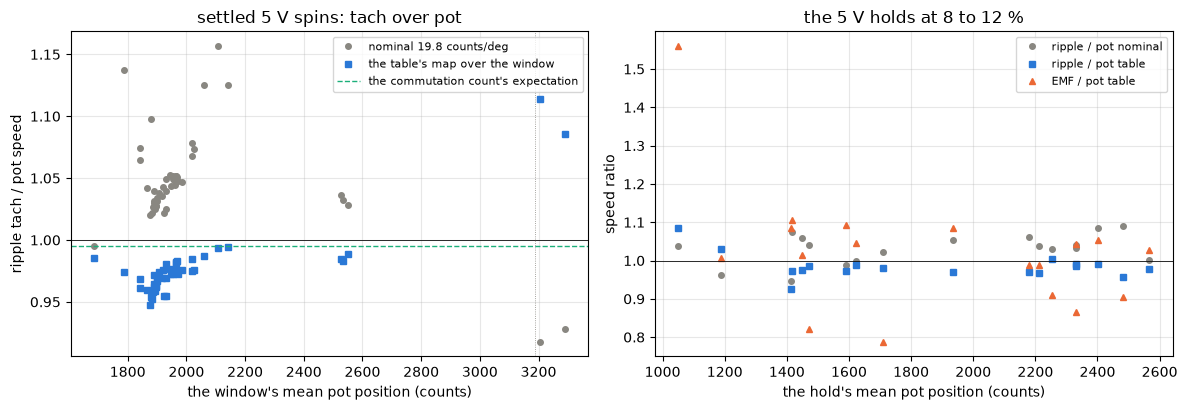

In [79]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(G["pot_mid_counts"], G["over_nominal"], "o", ms=4, color=MUTED,
           label=f"nominal {POT_NOM} counts/deg")
ax[0].plot(G["pot_mid_counts"], G["over_table"], "s", ms=4, color=BLUE,
           label="the table's map over the window")
ax[0].axhline(COMM, color=GREEN, lw=1, ls="--",
              label="the commutation count's expectation")
ax[0].axhline(1, color=INK, lw=0.6)
ax[0].axvline(PT_COUNTS[-1], color=MUTED, lw=0.6, ls=":")
figures.label(ax[0], x="the window's mean pot position (counts)",
              y="ripple tach / pot speed",
              title="settled 5 V spins: tach over pot")
ax[0].legend(fontsize=8)
for col, mk, c, lab in (("ripple_over_nominal", "o", MUTED, "ripple / pot"
                         " nominal"), ("ripple_over_table", "s", BLUE,
                         "ripple / pot table"), ("emf_over_table", "^",
                         ORANGE, "EMF / pot table")):
    ax[1].plot(TH["pot_mid_counts"], TH[col], mk, ms=4, color=c, label=lab)
ax[1].axhline(1, color=INK, lw=0.6)
figures.label(ax[1], x="the hold's mean pot position (counts)",
              y="speed ratio", title="the 5 V holds at 8 to 12 %")
ax[1].legend(fontsize=8)
figures.finish(fig)

What you are looking at. Left, the ripple tach over the pot speed on each settled 5 V spin against the window's position, on the nominal scale in gray and through the table's map in blue, the commutation count's expectation dashed and the table's end dotted. Right, the 5 V holds' ripple tach and coast EMF over the pot against the hold's position. Through the map the spins sit together under the expectation and drift up with position. The two run-up windows past the table's end sit apart from the rest.

## 10. The validity envelope

Each step holds only inside its gates. For each one the next cells give the gate, this servo's number for it and the rule that sets it on any servo, from the servo's own noise or the physics of the read rather than this servo's values.

In [80]:
FLOORS = (BOARD.i_window_min_ticks, BOARD.v_window_min_ticks)   # ticks
REST_SD = S["zero_i"].std()             # counts, the rest zero over sweeps
LEVER = I_LEVELS[1] / I_LEVELS[0] - 1   # the two levels' current lever
V0_PER_PERMIL = (0.001 * R_PASS
                 / (1 / I_LEVELS[0] - 1 / I_LEVELS[1]))   # V per 0.1 % V/I
hi_st = ST[ST["stop"] == "high"]
lo_st = ST[ST["stop"] == "low"]
SETTLE_RANGE = {d: (g["settle_pct"].min(), g["settle_pct"].max())
                for d, g in S[S["pass_rung"] & TACH_OK].groupby("duty")}
print(f"rest zero {S['zero_i'].mean():.1f} counts, sd {REST_SD:.2f} over "
      f"{len(S)} sweeps; the awake step {S['awake_step_counts'].mean():.2f}"
      f" counts at 5 V")
print(f"the chains' held ticks {ST['held_ticks'].abs().min()} and "
      f"{ST['held_ticks'].abs().max()} against the board's current and tap "
      f"floors {FLOORS[0]} and {FLOORS[1]}; lever {LEVER:.2f}; 0.1 % of V/I"
      f" moves V0 by "
      f"{V0_PER_PERMIL * 1e3:.1f} mV; V0 se "
      f"{PASS_R.loc['C g meter', 'v0_se'] * 1e3:.1f} mV")
print(f"seat: low {lo_st['pos_median'].min():.0f} to "
      f"{lo_st['pos_median'].max():.0f}, high {hi_st['pos_median'].min():.0f}"
      f" to {hi_st['pos_median'].max():.0f}; range within a step low "
      f"{lo_st['pos_range'].min():.0f} to {lo_st['pos_range'].max():.0f}, "
      f"high {hi_st['pos_range'].min():.0f} to {hi_st['pos_range'].max():.0f}")
print("settle by rung over the window before (%): " + ", ".join(
    f"{d} % {a:+.1f} to {b:+.1f}" for d, (a, b) in SETTLE_RANGE.items()))
print(f"bursts: {PB['periods'].iloc[0]} periods, residual rms "
      f"{PB['resid_rms_mv'].min():.1f} to {PB['resid_rms_mv'].max():.1f} mV,"
      f" L sd {SB['l_mh_sd'] / SB['l_mh'] * 100:.1f} % over {SB['n']}")

rest zero 1206.6 counts, sd 0.57 over 102 sweeps; the awake step 5.82 counts at 5 V
the chains' held ticks 288 and 432 against the board's current and tap floors 64 and 93; lever 0.48; 0.1 % of V/I moves V0 by 3.3 mV; V0 se 1.9 mV
seat: low 2 to 2, high 3806 to 3808; range within a step low 3 to 4, high 10 to 20
settle by rung over the window before (%): 30 % -1.6 to +0.6, 60 % +13.7 to +17.3, 100 % +2.2 to +10.3
bursts: 9 periods, residual rms 11.6 to 28.0 mV, L sd 4.2 % over 12


In [81]:
def r1(x):
    return f"{x:+.1f}"


ENV_ROWS = [
    ("0 rest", "the rest zero flat by tick phase",
     f"zero sd {REST_SD:.2f} counts over {len(S)} sweeps",
     "the baseline's own sd; a tick-phase spread over 1.5x the row sd fails"),
    ("1 chains", "window_valid and levels over the tap floor",
     f"{ST['held_ticks'].abs().min()} and {ST['held_ticks'].abs().max()} "
     f"ticks "
     f"against {FLOORS[0]} and {FLOORS[1]}, window_valid "
     f"{ST['window_valid'].min():.2f}",
     "window_valid = 1 on every held row, levels at 2x the tap floor"),
    ("1 chains", "a locked rotor is quiet",
     f"current sd {ST['i_sd_counts'].min():.2f} to "
     f"{ST['i_sd_counts'].max():.2f} counts",
     "the hold's crest sd against the rest baseline's"),
    ("1 chains", "the seat holds",
     f"pot range in a step {lo_st['pos_range'].max():.0f} (low) and "
     f"{hi_st['pos_range'].min():.0f} to {hi_st['pos_range'].max():.0f} "
     f"(high) counts", "the seat's change chain to chain, the rotor by"
     " the current's sd; a pot on its rail reads nothing"),
    ("1 chains", "the lever resolves V0",
     f"V0 se {PASS_R.loc['C g meter', 'v0_se'] * 1e3:.1f} mV, 0.1 % of V/I"
     f" is {V0_PER_PERMIL * 1e3:.0f} mV", "refuse a V0 whose se exceeds the"
     " contact scale; widen the levels within the lap cap"),
    ("1 chains", "warming within a chain",
     f"step 3 over step 1 {r1(PER_C['warm_pct'].mean())} %",
     "the 24 % steps bracket the 36 %; the rest returns the chain"),
]

In [82]:
ENV_ROWS += [
    ("2 bursts", "the first burst after a change is out",
     ", ".join(f"{g[:2]} {r1(v)} %" for g, v in FIRST_JUMP.items()),
     "the first over the others' median beyond their sd: drop it"),
    ("2 bursts", "the fit's residual and the periods",
     f"{PB['resid_rms_mv'].min():.0f} to {PB['resid_rms_mv'].max():.0f} mV,"
     f" L sd {SB['l_mh_sd'] / SB['l_mh'] * 100:.1f} %",
     "L's se over >= 3 bursts a group"),
    ("3 coasts", "the Ke gate, decel <= 0.35, >= 4 cycles",
     ", ".join(f"{d} % {v}" for d, v in GATED_BY.items()),
     "a rung whose coasts all fail is no Ke rung, and the tool says so"),
    ("3 coasts", "a settled spin for the brush table",
     ", ".join(f"{d} % {r1(a)} to {r1(b)}"
               for d, (a, b) in SETTLE_RANGE.items()),
     "above the settled speed the table is flagged as a run-up"),
    ("3 coasts", "the dropout rate",
     f"+1 at 100 % {DR_AT[('runup-open-1', 1)]:.0f} to "
     f"{DR_AT[('runup-close-1', 1)]:.0f} /s", "a spin over the quiet "
     "rungs' Poisson noise is marked; k_d is not read from one rail"),
    ("3 holds", "the floor's bracket",
     f"{NEVER_V:.3f} to {ALWAYS_V:.3f} V", "report the bracket, never the "
     "logistic's midpoint alone"),
    ("3 holds", "the window floors at the low levels",
     ", ".join(f"{d:.0f} % {v:.0f}" for d, v in
               LV.set_index("duty_pct")["valid"].items()),
     "a level under the floor gives turning or stopped only"),
    ("3 holds", "the breakaway",
     f"{NEVER_V:.3f} to {KICKS['kick_v_eff_v'].mean():.2f} V",
     "a bound until a sweep of pulses from rest")]
ENV = pd.DataFrame(ENV_ROWS, columns=["step", "gate", "this servo",
                                      "rule on any servo"])
show(ENV, n=None)

,step,gate,this servo,rule on any servo
0,0 rest,the rest zero flat by tick phase,zero sd 0.57 counts over 102 sweeps,the baseline's own sd; a tick-phase spread ove...
1,1 chains,window_valid and levels over the tap floor,"288 and 432 ticks against 64 and 93, window_va...","window_valid = 1 on every held row, levels at ..."
2,1 chains,a locked rotor is quiet,current sd 1.04 to 1.52 counts,the hold's crest sd against the rest baseline's
3,1 chains,the seat holds,pot range in a step 4 (low) and 10 to 20 (high...,"the seat's change chain to chain, the rotor by..."
4,1 chains,the lever resolves V0,"V0 se 1.9 mV, 0.1 % of V/I is 3 mV",refuse a V0 whose se exceeds the contact scale...
5,1 chains,warming within a chain,step 3 over step 1 +0.5 %,the 24 % steps bracket the 36 %; the rest retu...
6,2 bursts,the first burst after a change is out,"g1 +10.2 %, g2 +2.9 %, g3 -0.1 %, g4 +1.3 %, g...",the first over the others' median beyond their...
7,2 bursts,the fit's residual and the periods,"12 to 28 mV, L sd 4.2 %",L's se over >= 3 bursts a group
8,3 coasts,"the Ke gate, decel <= 0.35, >= 4 cycles","15 % 0/6, 30 % 6/6, 60 % 6/6, 100 % 6/6","a rung whose coasts all fail is no Ke rung, an..."
9,3 coasts,a settled spin for the brush table,"30 % -1.6 to +0.6, 60 % +13.7 to +17.3, 100 % ...",above the settled speed the table is flagged a...


The rest zero's sd over 102 sweeps is 0.57 counts. The chains held 288 and 432 ticks against the board's current and tap floors of 64 and 93, window_valid 1.00 on every step. The lever between the two levels is 0.48, so 0.1 % of V/I moves V0 by 3.3 mV against a V0 se of 1.9 mV over four chains. At the stops the plant traps' pot-range gate rejects every high-stop step, 10 to 20 counts of stopper flex, while the current's sd of 1.04 to 1.52 counts reads a locked rotor, and at the low stop the pot sits on its ADC rail at 2 and reads nothing. A tool at a stop gates the seat on its change chain to chain and the rotor on the current's sd. The bursts' fit leaves 11.6 to 28.0 mV rms over the pass's bursts, with L's sd 4.2 %. Per spin the settle reads -1.6 to +0.6 % at 30 %, +13.7 to +17.3 % at 60 % and +2.2 to +10.3 % at 100 %, so on 5 V only the 30 % rung is a brush-table rung. The 15 % rung is no Ke rung, 0/6, and the tool says so.

## 11. The grade and the hand-off

The grade table puts every graded quantity on one scale, the pass less the long form in sigma, the two se in quadrature, or half the long form's bracket where it carries a range. Nothing under 2 sigma is a finding, and 2 to 3 sigma is named as such.

In [83]:
KEEP = ["R A as read", "R B board terms", "R C g meter", "V0 C g meter",
        f"V/I at {I_LOCK:.3f} A C g meter", "L (pass, stop seat)",
        "tau (pass, stop seat)", "burst R (pass, stop seat)",
        "Ke (pass, 5 V coasts)", "Ke (pass) vs the ladder's 5 V block",
        "floor (pass, 5 V)"] + [
    f"V_b {d:+d} at {k} rev/s (pass C, g 4.75)"
    for d in (1, -1) for k in (150, 300)]
ALL_G = pd.DataFrame(G_R + G_L + G_KE + [G_FLOOR] + G_VB)
GT = ALL_G.set_index("quantity").loc[KEEP].reset_index()
z = GT["gap_sigma"].abs()
GT["verdict"] = np.where(z <= 2, "reproduces",
                         np.where(z <= 3, "2-3 sigma", "misses"))
show(GT[["quantity", "pass", "pass_se", "long", "long_sigma", "unit",
         "gap_pct", "gap_sigma", "verdict"]], n=None)

,quantity,pass,pass_se,long,long_sigma,unit,gap_pct,gap_sigma,verdict
0,R A as read,4.384,0.006,4.177,0.006,ohm,4.964,24.194,misses
1,R B board terms,4.271,0.006,4.177,0.006,ohm,2.264,10.902,misses
2,R C g meter,4.161,0.006,4.177,0.006,ohm,-0.373,-1.839,reproduces
3,V0 C g meter,0.034,0.002,0.031,0.002,V,9.321,0.945,reproduces
4,V/I at 0.767 A C g meter,4.206,0.006,4.219,0.004,ohm,-0.313,-1.824,reproduces
5,"L (pass, stop seat)",0.843,0.010,0.820,0.046,mH,2.861,0.495,reproduces
6,"tau (pass, stop seat)",199.016,1.521,198.505,9.340,us,0.257,0.054,reproduces
7,"burst R (pass, stop seat)",4.236,0.024,4.217,0.086,ohm,0.437,0.206,reproduces
8,"Ke (pass, 5 V coasts)",7.263,0.006,7.283,0.004,mV/(rev/s),-0.271,-2.654,2-3 sigma
9,Ke (pass) vs the ladder's 5 V block,7.263,0.006,7.259,0.006,mV/(rev/s),0.052,0.432,reproduces


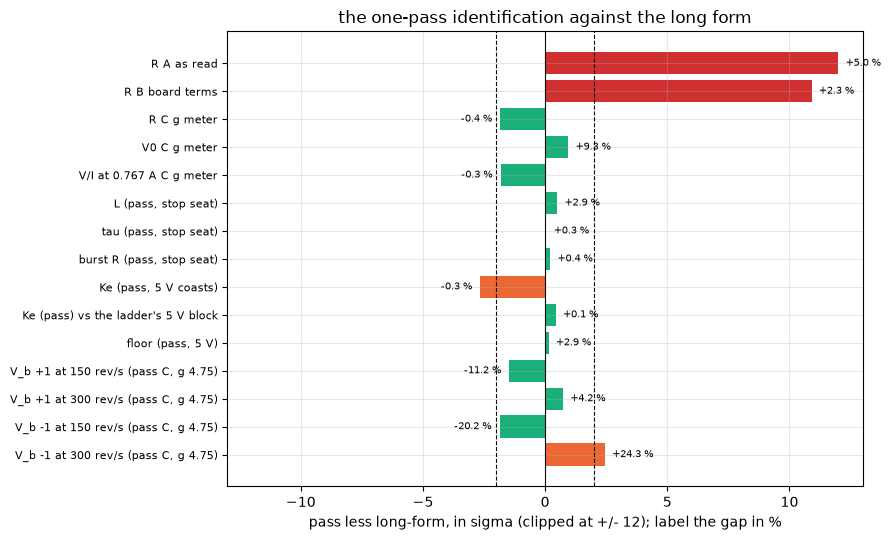

In [84]:
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(GT))
color = np.where(z <= 2, GREEN, np.where(z <= 3, ORANGE, RED))
ax.barh(y, GT["gap_sigma"].clip(-12, 12), color=color)
for yy, (s, p) in enumerate(zip(GT["gap_sigma"], GT["gap_pct"])):
    s = float(np.clip(s, -12, 12))
    ax.text(s + (0.3 if s >= 0 else -0.3), yy, f"{p:+.1f} %", va="center",
            ha="left" if s >= 0 else "right", fontsize=7)
for x in (-2, 2):
    ax.axvline(x, color=INK, lw=0.8, ls="--")
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y, GT["quantity"], fontsize=8)
ax.set_xlim(-13, 13)
ax.invert_yaxis()
figures.label(ax, x="pass less long-form, in sigma (clipped at +/- 12); "
              "label the gap in %",
              title="the one-pass identification against the long form")
figures.finish(fig)

What you are looking at. Each graded quantity's gap in sigma, clipped at 12, labeled with the gap in percent, green under 2 sigma, orange at 2 to 3 and red over 3, the 2 sigma lines dashed.

With the board constants and a carried g the pass reproduces R0, V0, its line at the lock's current, L, tau, the window model's R, the floor and Ke against the ladder's 5 V block. Ke against the three-rail pool sits at -2.654 sigma, inside the long form's own rail spread. The brush table reproduces at 150 rev/s both ways and at 300 rev/s for +1, and reads 2.442 sigma over for -1 at 300 rev/s, where the knot stands on a run-up. Without g the pass misses R0, by 10.902 sigma with the board terms and 24.194 sigma as read.

In [85]:
FP = FRICTION["firmware_pair"]["pooled"]   # the friction notebook's pair
TC_Q, B_Q = FP["coulomb_uNm"], FP["viscous_uNm_s_per_rad"]
TC_SE = FRICTION["coulomb_uNm"]["pooled"]
KT_GEAR = LOAD["kt_gear_mn_m_per_a"]        # mN m/A at the output
FLOOR_FR = FRICTION["floor_v_effective_quoted"]
print(f"J {J_LONG['value'] * 1e9:.2f}e-9 kg m2 ({J_LONG['lo'] * 1e9:.2f} "
      f"to {J_LONG['hi'] * 1e9:.2f}), the run-up result's")
print(f"friction pair, pooled: Tc {TC_Q['value']:.1f} uN m ({TC_Q['lo']:.1f}"
      f" to {TC_Q['hi']:.1f}; route 1's se {TC_SE['value'] - TC_SE['lo']:.1f}"
      f"), b {B_Q['value']:.4f} uN m s/rad ({B_Q['lo']:.4f} to "
      f"{B_Q['hi']:.4f})")
print("Kt through the gears: " + ", ".join(
    f"{k} {v['value']:.1f} ({v['lo']:.1f} to {v['hi']:.1f})"
    for k, v in KT_GEAR.items() if k in ("+1", "-1", "pooled"))
      + f" mN m/A; lossless Ke x N {KE_PASS / RPS * GEAR:.1f}")
print(f"the friction result's floor {FLOOR_FR['value']:.3f} V "
      f"({FLOOR_FR['lo']:.3f} to {FLOOR_FR['hi']:.3f})")

J 6.43e-9 kg m2 (5.86 to 7.07), the run-up result's
friction pair, pooled: Tc 55.1 uN m (42.8 to 65.3; route 1's se 3.3), b 0.0474 uN m s/rad (0.0370 to 0.0632)
Kt through the gears: +1 215.8 (210.7 to 220.0), -1 234.3 (228.1 to 242.7), pooled 222.9 (217.9 to 227.7) mN m/A; lossless Ke x N 356.1
the friction result's floor 0.340 V (0.300 to 0.399)


In [86]:
rc, rb = PASS_R.loc["C g meter"], PASS_R.loc["B board terms"]
ke_rad = KE_PASS * 1e-3 / RPS                # V s/rad
KE_SYS_PCT = 0.5                            # %, the long form's systematic


def row(name, v, lo, hi, unit, note=""):
    return {"constant": name, "value": v, "lo": lo, "hi": hi, "unit": unit,
            "note": note}


HAND_ROWS = [
    row("R0 (C, carried g)", rc["r_ohm"], rc["r_ohm"] - 2 * rc["r_se"],
        rc["r_ohm"] + 2 * rc["r_se"], "ohm", "2 se"),
    row("R0 (B, board terms)", rb["r_ohm"], rb["r_ohm"] - 2 * rb["r_se"],
        rb["r_ohm"] + 2 * rb["r_se"], "ohm", "2 se, no g"),
    row("V0 (C)", rc["v0_v"], rc["v0_v"] - 2 * rc["v0_se"],
        rc["v0_v"] + 2 * rc["v0_se"], "V", "2 se"),
    row("T0", T0["mean"], T0["lo"], T0["hi"], "C", "the board NTC"),
    row("L", SB["l_mh"] * 1e-3, (SB["l_mh"] - 2 * SB["l_mh_se"]) * 1e-3,
        (SB["l_mh"] + 2 * SB["l_mh_se"]) * 1e-3, "H", "2 se"),
    row("tau", SB["tau_us"] * 1e-6, (SB["tau_us"] - 2 * SB["tau_us_se"])
        * 1e-6, (SB["tau_us"] + 2 * SB["tau_us_se"]) * 1e-6, "s", "2 se"),
    row("Ke", ke_rad, ke_rad * (1 - KE_SYS_PCT / 100),
        ke_rad * (1 + KE_SYS_PCT / 100), "V s/rad", "+/- 0.5 % carried"),
    row("floor", FLOOR_V, NEVER_V, ALWAYS_V, "V effective", "the bracket"),
    row("slowest sustained speed", SLOW["ripple"], np.nan, np.nan,
        "rev/s at the motor", "ripple tach"),
    row("breakaway", np.nan, NEVER_V, KICKS["kick_v_eff_v"].mean(),
        "V effective", "a bound")]

In [87]:
HAND_ROWS += [
    row("dropout reference +1, last 20 ms", DR_AT[("runup-open-1", 1)],
        np.nan, DR_AT[("runup-close-1", 1)], "rows per s", "open, close"),
    row("J (quoted)", J_LONG["value"], J_LONG["lo"], J_LONG["hi"], "kg m2"),
    row("Tc (quoted)", TC_Q["value"] * 1e-6, TC_Q["lo"] * 1e-6,
        TC_Q["hi"] * 1e-6, "N m", "friction firmware pair"),
    row("b (quoted)", B_Q["value"] * 1e-6, B_Q["lo"] * 1e-6,
        B_Q["hi"] * 1e-6, "N m s/rad", "friction firmware pair"),
    row("Kt through the gears (quoted)", KT_GEAR["pooled"]["value"] * 1e-3,
        KT_GEAR["pooled"]["lo"] * 1e-3, KT_GEAR["pooled"]["hi"] * 1e-3,
        "N m/A at the output", "load, pooled"),
    row("g (quoted)", G_METER["value"] * 1e-3, G_METER["lo"] * 1e-3,
        G_METER["hi"] * 1e-3, "S on (1 - D) V_on", "the meter's")]
HAND = pd.DataFrame(HAND_ROWS)
with pd.option_context("display.float_format", "{:.6g}".format):
    print(HAND.to_string(index=False))

                        constant       value          lo          hi                unit                   note
               R0 (C, carried g)     4.16101     4.14933     4.17269                 ohm                   2 se
             R0 (B, board terms)     4.27114     4.25886     4.28343                 ohm             2 se, no g
                          V0 (C)    0.034222   0.0303737   0.0380702                   V                   2 se
                              T0     26.0183     25.9482     26.0588                   C          the board NTC
                               L  0.00084321  0.00082278  0.00086364                   H                   2 se
                             tau 0.000199016 0.000195973 0.000202058                   s                   2 se
                              Ke  0.00115595  0.00115017  0.00116173             V s/rad      +/- 0.5 % carried
                           floor    0.350045    0.299846    0.398825         V effective            the 

In [88]:
for d in (1, -1):
    r = CMP[CMP["dir"] == d].set_index("knot")
    print(f"brush table {d:+d} at 150 / 200 / 300 rev/s: " + " / ".join(
        f"{r.loc[k, 'pass_C_mv']:.0f}" for k in (150.0, 200.0, 300.0))
          + " mV, sd " + " / ".join(
        f"{r.loc[k, 'pass_sd_mv']:.1f}" for k in (150.0, 200.0, 300.0)))
print(f"settled to {SETTLED_RM['rev_s'].max():.0f} rev/s; k_d none (the "
      f"fit's {KD_FIT[0]:+.2f} +/- {KD_FIT[1]:.2f} is the run-ups' lever); "
      f"L at 25 / 40 %: {BY_DUTY[25]['l_mh']:.3f} / "
      f"{BY_DUTY[40]['l_mh']:.3f} mH")
print(f"Ke {KE_PASS:.3f} mV per rev/s, 2 se "
      f"{2 * KE_SE / KE_PASS * 100:.2f} %, carried +/- {KE_SYS_PCT} %")

brush table +1 at 150 / 200 / 300 rev/s: 39 / 56 / 91 mV, sd 2.3 / 2.7 / 3.6
brush table -1 at 150 / 200 / 300 rev/s: 29 / 42 / 69 mV, sd 2.8 / 3.2 / 3.9
settled to 140 rev/s; k_d none (the fit's +1.94 +/- 0.31 is the run-ups' lever); L at 25 / 40 %: 0.812 / 0.874 mH
Ke 7.263 mV per rev/s, 2 se 0.17 %, carried +/- 0.5 %


What the pass hands stages 4 to 7, in firmware units with brackets.

- R0 under C with the carried g, 4.16101 ohm, 4.14933 to 4.17269 at 2 se, with g's band moving it by 5.2 mohm. A pass with no g hands B's 4.27114 ohm, 2.26 % high. V0 under C is 0.034222 V. T0 is the board NTC's 26.0183 C, not the copper's.
- L 0.00084321 H, 0.00082278 to 0.00086364 at 2 se. L rises with the current, 0.812 mH at 25 % and 0.874 at 40 %, so a loop that wants one value at its working current reads it at that duty. Tau 0.000199016 s.
- Ke 0.00115595 V s/rad, 7.263 mV per rev/s. Its 2 se is 0.17 %, and the long form's own spread across rails is wider, so the hand-off carries +/- 0.5 %, 0.00115017 to 0.00116173.
- The brush table per direction, 39 / 56 / 91 mV at 150 / 200 / 300 rev/s for +1 and 29 / 42 / 69 for -1, settled to 140 rev/s only. The 200 and 300 rev/s knots stand on the 60 % run-up.
- No k_d. The pass does not identify it on one rail inside one travel, and it hands the dropout reference instead, 33.3333 rows per s over the 100 % run-up's last 20 ms at the open of sitting 1 and 116.667 at its close, for +1. A later notebook, still pending, wants k_d near zero for the compensation.
- The floor as a bracket, 0.299846 to 0.398825 V effective. The slowest sustained speed 20.3558 rev/s at the motor by the ripple tach. The breakaway bounded at 0.299846 to 1.46159 V effective.

Quoted, since the pass does not read them. J 6.43e-9 kg m2 (5.86 to 7.07) from the run-up result. The friction pair from the friction result's firmware pair, pooled, Tc 55.1 uN m (42.8 to 65.3) and b 0.0474 uN m s/rad (0.0370 to 0.0632). Route 1's se on Tc alone is 3.3, and the firmware bracket adds the crest term, current-scale and Ke. The pair rests on tach speeds, so the pot's scale does not enter it. Kt through the gears from the load result, 222.9 mN m/A pooled (217.9 to 227.7), 215.8 for +1 and 234.3 for -1, against a lossless Ke x N of 356.1. The load result reads its angles through the pot table, and the caveat of section 9 applies to any consumer of that table. g 4.746 mS from the meter, carried. The friction result quotes the ladder's floor, 0.340 V (0.300 to 0.399), the bracket the pass reads.

### Open discrepancies

1. Ke on one rail reads -0.271 % under the ladder's three-rail pool, -2.654 sigma on the se, and +0.432 sigma from its 5 V block. The candidates are the ladder's rail split (-0.43 % at matched speed), the tap zero under the coast's EMF, and a real rail dependence of the coast's EMF window. A coast with a long torque-off tail recorded beside the baseline on one rail, and coasts at matched speed on two rails interleaved cycle by cycle, separate them. The zero predicts a gap that follows the tail's zero, the rail split one that follows the rail at matched speed.
2. The brush table at 300 rev/s in -1 reads +24.3 % over the ladder's B table, 2.442 sigma. The ladder's table has its own 6.14 mS crest term out and the pass the meter's 4.75, worth 11.6 mV of X at 60 %, and the pass's 60 % spin is a run-up. The candidates are a spinning-only excess over the locked g, the run-up's J alpha in the current, and the direction term. A camera sitting's full-travel pass at 20 %, a settled 60 % rung on 3.7 V read in the same sitting with the meter's g fixed, and the meter in series on a spinning rung separate them. The g candidate predicts a gap that follows (1 - D) V_on, the J alpha one that vanishes on a settled rung.
3. Through the table the tach reads 0.9720 of the pot at 1686 to 2551 counts, where the commutation count puts it at 0.9951. The candidates are the table's bend there read from crawls (its span slope 18.33 against the quoted 18.913), the tach's N (306.5 by commutation against 308.05 by the teeth), and the pot's local gain at speed against at a crawl. A camera pass at 20 % over that span with the ripple tach counted in the same clip separates the table from the tach.
4. The pass's R under C sits -0.373 % under the rails' C line, -1.839 sigma, and the brake form moves it +0.82 %. The candidates are the two stops' commutator angles against the angles the line averages, and the convention of the 8.8 mV brake intercept. Bursts at both stops and on the RL dummy in one sitting separate them, since the dummy has no commutator.
5. k_d is not identified by the pass on 5 V, since no settled spin inside one travel drops out. The README's step 3 names the brush table per direction and its dropout coefficient. On 5 V the pass gives the table to 140 rev/s and the dropout reference, not k_d. A sitting where both directions drop out at a settled rung, 7.4 V at 60 % with a longer runway, is the ladder's own separating experiment.
6. The floor is a bracket, 0.300 to 0.399 V, because the holds step by whole percent on 5 V. The three-rail logistic's 0.340 sits inside it but is not read from 5 V alone. Holds at half-percent steps between 6 and 8 % halve the bracket.

### The next sitting's plan

- Coasts with a long torque-off tail beside the baseline, and coasts at matched speed on two rails interleaved cycle by cycle, for Ke's gap to the pool.
- A camera pass at 20 % across the middle of travel with the ripple tach counted in the same clip, for the table's bend.
- Bursts at both stops and on the RL dummy in one sitting, for R's angle and the brake form.
- Holds at half-percent steps between 6 and 8 % on 5 V, for the floor.
- A sweep of pulses from rest between the floor and the kick, both directions, for the breakaway.
- A settled rung where both directions drop out, 7.4 V at 60 % with a longer runway, for k_d.
- The same pass with 5 s rests in place of 20 s, timed, for the cost.

### The result file

Every quantity with its bounds and unit. The pass's brackets are its own repeats' se or sd as each key's unit names, the `*_long` keys quote the long-form number it is graded against, and `*_gap_pct` and `*_gap_sigma` the grade.

In [89]:
q, pm = results.quantity, results.pm


def by_dir(f):
    """{"+1": f(+1), "-1": f(-1)}"""
    return {"+1": f(1), "-1": f(-1)}


def rng_q(lo, hi, unit):
    """A range with its midpoint as the value."""
    return q((lo + hi) / 2, lo, hi, unit)


def g_of(table, name):
    """One grade row by its quantity's name."""
    return table.set_index("quantity").loc[name]


def gap_keys(prefix, row):
    return {f"{prefix}_gap_pct": q(row["gap_pct"], unit="%"),
            f"{prefix}_gap_sigma": q(row["gap_sigma"], unit="sigma")}


CONS_KEYS = {"A as read": "A", "B board terms": "B",
             "C g type spin": "C_type_g", "C g meter": "C_meter_g"}

In [90]:
QUANTITIES = {
    "pass_steps": {
        "0 rest": {"datasets": "every sweep's torque-off baseline and the "
                   "manifest probe before it"},
        "1 chains": {"datasets": str(results.rel(STOP_DIR)),
                     "used": "chains 0-3"},
        "2 bursts": {"datasets": str(results.rel(BURST_DIR)),
                     "used": "g1-g4, bursts 1-3"},
        "3 rungs": {"datasets": ", ".join(sorted(set(PASS_RUNGS.values()))),
                    "used": "5 V, three cycles a rung, both ways"}},
    "pass_rungs_5v": [int(d) for d in PASS_DUTIES],
    "pass_chains": PASS_CHAINS,
    "pass_bursts": {"groups": PASS_GROUPS, "bursts": list(PASS_BURSTS)},
}
print(len(QUANTITIES), "keys")

4 keys


In [91]:
QUANTITIES.update({
    "r0_ohm": {CONS_KEYS[c]: pm(PASS_R.loc[c, "r_ohm"],
                                PASS_R.loc[c, "r_se"], "ohm, se, 4 chains")
               for c in CONSTRUCTIONS},
    "v0_v": {CONS_KEYS[c]: pm(PASS_R.loc[c, "v0_v"], PASS_R.loc[c, "v0_se"],
                              "V, se, 4 chains") for c in CONSTRUCTIONS},
    "r0_by_stop_ohm": {s: q(PASS_R.loc["C g meter", f"r_{s}"], unit="ohm")
                       for s in ("low", "high")},
    "r0_by_chain_ohm": {str(int(r["chain"])): q(r["r_ohm"], unit="ohm")
                        for _, r in PER_C.iterrows()},
    "r0_dr_per_ms_g_mohm": q(DR_DG * 1e3, unit="mohm per mS"),
    "r0_brake_form_alt_ohm": results.line_q(BRAKE_ALT, "slope", "ohm"),
    "v0_brake_form_alt_v": results.line_q(BRAKE_ALT, "intercept", "V"),
    "vi_at_lock_current_ohm": pm(PASS_R.loc["C g meter", "vi_at_lock"],
                                 PASS_R.loc["C g meter", "r_se"], "ohm"),
    "t0_c": q(T0["mean"], T0["lo"], T0["hi"], "C, the board NTC"),
    "chain_warming_step3_over_step1_pct": results.mean_sd(
        PER_C["warm_pct"], "%"),
    "chain_order_trend_mohm_per_chain": results.line_q(
        TREND, "slope", "mohm per chain", 1e3),
    "stop_quiet_gate": {
        "i_sd_counts": rng_q(ST["i_sd_counts"].min(),
                             ST["i_sd_counts"].max(), "counts"),
        "pos_range_counts": rng_q(ST["pos_range"].min(),
                                  ST["pos_range"].max(), "counts"),
        "steps_passing": q(int(quiet.sum()), unit=f"of {len(ST)}")},
    **gap_keys("r0_c", g_of(GR_R, "R C g meter")),
    **gap_keys("vi_lock", g_of(GR_R, f"V/I at {I_LOCK:.3f} A C g meter")),
})
print(len(QUANTITIES), "keys")

20 keys


In [92]:
QUANTITIES.update({
    "l_mh": pm(SB["l_mh"], SB["l_mh_se"], "mH, se, 12 bursts"),
    "l_mh_sd": q(SB["l_mh_sd"], unit="mH"),
    "l_mh_by_duty": {f"{d} %": pm(s["l_mh"], s["l_mh_se"], "mH, se")
                     for d, s in BY_DUTY.items()},
    "tau_us": pm(SB["tau_us"], SB["tau_us_se"], "us, se"),
    "r_burst_ohm": pm(SB["r_ohm"], SB["r_ohm_se"], "ohm, se"),
    "l_ripple_mh": pm(SB["l_ripple_mh"], SB["l_ripple_mh_se"], "mH, se"),
    "l_first_jump_pct_by_group": {g: q(v, unit="%")
                                  for g, v in FIRST_JUMP.items()},
    "l_fold_sensitivity_pct": {k: q(FOLD_PCT[c], unit="%") for k, c in
                               (("l", "l_mh"), ("r", "r_ohm"),
                                ("tau", "tau_us"))},
    "l_by_seat_pass_design_mh": {
        s: pm(VARIANTS[k]["l_mh"], VARIANTS[k]["l_mh_se"], "mH, se")
        for s, k in (("stop", "pass"), ("lock", "lock, the pass's design"),
                     ("wound", "wound, the pass's design"))},
    **gap_keys("l", g_of(GR_L, "L (pass, stop seat)")),
    "l_by_duty_gap_pct": {
        f"{d} % vs {seat}": q(g_of(GR_L, f"L {d} % (pass) vs the "
                                         f"notebook's {seat}")["gap_pct"],
                              unit="%")
        for d in (25, 40) for seat in ("stop", "lock")},
    **gap_keys("tau", g_of(GR_L, "tau (pass, stop seat)")),
})
print(len(QUANTITIES), "keys")

34 keys


In [93]:
QUANTITIES.update({
    "ke_mv_per_rev_s": pm(KE_PASS, KE_SE, "mV per rev/s, se"),
    "ke_sd_mv_per_rev_s": q(KE_SD, unit="mV per rev/s"),
    "ke_coasts_n": q(len(ke), unit="coasts"),
    "ke_v_s_per_rad": pm(KE_PASS * 1e-3 / RPS, KE_SE * 1e-3 / RPS,
                         "V s/rad, se"),
    "ke_by_rung": {f"{d} %": q(r["ke"], r["ke"] - r["sd"], r["ke"] + r["sd"],
                               f"mV per rev/s, sd, {r['rev_s']:.0f} rev/s")
                   for d, r in KE_BY_RUNG.iterrows()},
    "ke_by_direction": {f"{d:+d}": q(r["mean"], unit="mV per rev/s")
                        for d, r in KE_BY_DIR.iterrows()},
    "ke_alternatives": {k: q(v, unit="mV per rev/s")
                        for k, v in KE_ALT.items()},
    "ke_fewer_coasts_rms_pct": {str(n): q(v, unit="%")
                                for n, v in FEWER.items()},
    "ke_speed_trend_pct_per_100_rev_s": results.line_q(
        KE_TREND, "slope", "% per 100 rev/s", 100),
    "ke_gate_pass_by_rung": {f"{d} %": v for d, v in GATED_BY.items()},
    "ke_gap_pct": {"pooled": q(G_KE[0]["gap_pct"], unit="%"),
                   "5 V block": q(G_KE[1]["gap_pct"], unit="%")},
    "ke_gap_sigma": {"pooled": q(G_KE[0]["gap_sigma"], unit="sigma"),
                     "5 V block": q(G_KE[1]["gap_sigma"], unit="sigma")},
    "ke_systematic_carried_pct": q(KE_SYS_PCT, unit="%"),
})
print(len(QUANTITIES), "keys")

47 keys


In [94]:
def knots(d, col, unit):
    r = CMP[CMP["dir"] == d].set_index("knot")
    return {f"{k:.0f} rev/s": q(r.loc[k, col], unit=unit)
            for k in KNOTS if np.isfinite(r.loc[k, col])}


QUANTITIES.update({
    "brush_table_mv": by_dir(lambda d: knots(d, "pass_C_mv", "mV")),
    "brush_table_rung_sd_mv": by_dir(lambda d: knots(d, "pass_sd_mv",
                                                     "mV")),
    "brush_table_settled_to_rev_s": q(SETTLED_RM["rev_s"].max(),
                                      SETTLED_RM["rev_s"].min(),
                                      SETTLED_RM["rev_s"].max(), "rev/s"),
    "brush_table_gap_mv_vs_ladder_b": by_dir(lambda d: knots(d, "gap_mv",
                                                             "mV")),
    "brush_table_gap_sigma": {r["quantity"]: q(r["gap_sigma"], unit="sigma")
                              for _, r in GR_VB.iterrows()},
    "brush_direction_term_mv_by_rung": {f"{d} %": q(v, unit="mV")
                                        for d, v in DIR_TERM.items()},
    "brush_table_settled_equiv_alt_mv": by_dir(
        lambda d: knots(d, "settled_equiv_mv", "mV")),
    "brush_g_shift_at_60pct_mv": q(G_SHIFT, unit="mV, ladder g over meter"),
    "k_d_identifiable": False,
    "k_d_fit_candidate": pm(KD_FIT[0], KD_FIT[1], f"mV per dropout/s, se, "
                            f"dof {KD_DOF}, the run-ups' lever"),
    "dropout_reference_last20_per_s": {
        s: by_dir(lambda d, s=s: q(DR_AT[(s, d)], unit="rows per s"))
        for s in DR["set"].unique()},
    "dropout_reference_window_per_s": {
        s: by_dir(lambda d, s=s: q(DR.set_index(["set", "dir"]).loc[
            (s, d), "rate_window"], unit="rows per s"))
        for s in DR["set"].unique()},
    "dropout_rows_reference_rung": q(int(ref["dropout_rows"].sum()),
                                     unit=f"rows in {len(ref)} spins"),
})
print(len(QUANTITIES), "keys")

60 keys


In [95]:
QUANTITIES.update({
    "floor_v_effective": q(FLOOR_V, NEVER_V, ALWAYS_V,
                           "V effective, never to always turned"),
    "floor_logistic_mid_v": q(LOGIT[0], BOOT[0], BOOT[1],
                              "V, bootstrap 68 %"),
    "floor_levels": {f"{r['duty_pct']:.0f} %": {
        "turned": q(int(r["n_turn"]), unit=f"of {int(r['n'])}"),
        "v_eff": q(r["v_eff"], unit="V"),
        "window_valid": q(r["valid"], unit="share")}
        for _, r in LV.iterrows()},
    "floor_speed_rev_s": {k: q(SLOW[s], unit="rev/s") for k, s in (
        ("ripple", "ripple"), ("pot_nominal", "pot_nominal"),
        ("pot_table", "pot_table"))},
    "crawl_10pct_rev_s": {k: q(CRAWL_W[s], unit="rev/s") for k, s in (
        ("ripple", "ripple"), ("pot_nominal", "pot_nominal"),
        ("pot_table", "pot_table"))},
    "crawl_10pct_ma": results.mean_sd(CRAWL["i_hold_a"], "mA", 1e3),
    "crawl_speed_line_rev_s_per_v": {
        "nominal": results.line_q(LINE, "slope", "rev/s per V"),
        "table": results.line_q(LINE_T, "slope", "rev/s per V")},
    "breakaway_v_eff_bounds": {"value": None, "lo": NEVER_V,
                               "hi": KICKS["kick_v_eff_v"].mean(),
                               "unit": "V effective, a bound"},
    "kick_break_ms": results.mean_sd(KICKS["break_ms"], "ms"),
    "kick_i_peak_a": results.mean_sd(KICKS["i_break_peak_a"], "A"),
})
print(len(QUANTITIES), "keys")

70 keys


In [96]:
QUANTITIES.update({
    "cost_by_step": {r["step"]: {
        "drive_s": q(r["drive_s"], unit="s"),
        "wall_s_as_run": q(r["wall_s"], unit="s"),
        "revs": q(r["revs"], unit="motor revs"),
        "joules": q(r["joules"], unit="J")} for _, r in COST.iterrows()},
    "revs_by_rung": {f"{r['duty']} %": q(r["revs_pot"], unit="motor revs "
                                         "a spin + coast")
                     for _, r in CR.iterrows()},
    "pass_total_drive_s": q(TOT["drive_s"], unit="s"),
    "pass_total_wall_min": q(TOT["wall_s"] / 60, unit="min, as run"),
    "pass_total_revs": q(TOT["revs"], unit="motor revs"),
    "pass_quick_wall_min": q(QUICK_S / 60, unit="min, 5 s rests"),
    "heating": {
        "chain_trend_mohm": results.line_q(TREND, "slope",
                                           "mohm per chain", 1e3),
        "step3_over_step1_pct": q(PER_C["warm_pct"].mean(), unit="%"),
        "ntc_open_c": q(NTC_BR["ref-open-1"], unit="C"),
        "ntc_close_c": q(NTC_BR["ref-close-1"], unit="C"),
        "joules_bound_pct": q(J3 * WARM, unit="% of R, no cooling")},
})
print(len(QUANTITIES), "keys")

77 keys


In [97]:
def oc(kind, d):
    v = OPEN_CLOSE[(kind, d)]
    return {"speed_pct": pm(*v["speed_pct"], "%"),
            "i_ma": pm(*v["i_ma"], "mA"), "ke_pct": pm(*v["ke_pct"], "%")}


QUANTITIES.update({
    "open_close_sitting1": {k: by_dir(lambda d, k=k: oc(k, d))
                            for k in ("ref", "runup")},
    "stop_pairs_r_ohm": [q(r, unit="ohm") for r in PAIRS_R],
    "stop_pairs_spread_pct": q(PAIRS_SPREAD, unit="%"),
    "across_sittings": {f"{r['kind']} {r['sitting']}": {
        "speed": q(r["speed"], unit="rev/s"), "i_ma": q(r["i_ma"],
                                                       unit="mA"),
        "ke": q(r["ke"], unit="mV per rev/s"),
        "dropouts_plus": q(r["dropouts_plus"], unit="rows")}
        for _, r in AC.iterrows()},
    "ke_sitting_spread_pct": q(KE_SIT_SPREAD, unit="% sd, six blocks"),
    "l_seat_spread_pct": q((SEAT_L.max() / SEAT_L.min() - 1) * 100,
                           unit="%"),
    "vi_as_read_by_rail": VI_RAILS,
})
print(len(QUANTITIES), "keys")

84 keys


In [98]:
QUANTITIES.update({
    "tach_over_pot_nominal": results.mean_sd(GI["over_nominal"], "ratio"),
    "tach_over_pot_table": pm(*TACH_TABLE, "ratio, se, 45 spins"),
    "ripple_over_pot_holds": {
        "nominal": results.mean_sd(TH["ripple_over_nominal"], "ratio"),
        "table": results.mean_sd(TH["ripple_over_table"], "ratio")},
    "emf_over_pot_holds_table": results.mean_sd(TH["emf_over_table"],
                                                "ratio"),
    "table_over_nominal_at_holds": results.mean_sd(FAC_HOLDS, "ratio"),
    "tach_over_pot_table_position_trend_per_1000": results.line_q(
        POS_IN, "slope", "per 1000 counts", 1000),
    "pot_span_slope_counts_per_deg": {f"{c} counts": q(span_slope(c),
                                                       unit="counts/deg")
                                      for c in AT_C},
    "crosscheck": {r["check"]: q(r["value"],
                                 r["value"] - r["sd"] if np.isfinite(
                                     r["sd"]) else None,
                                 r["value"] + r["sd"] if np.isfinite(
                                     r["sd"]) else None,
                                 f"ratio, sd, {r['source']}")
                   for _, r in CROSS.iterrows()},
    "ladder_pot_keys_corrected": {k: {
        "ladder": q(v[0], unit="nominal, three rails"),
        "nominal": q(v[1], unit="5 V"), "table": q(v[2], unit="5 V"),
        "ripple": q(v[3], unit="5 V")} for k, v in CORRECTED.items()},
})
print(len(QUANTITIES), "keys")

93 keys


In [99]:
QUANTITIES.update({
    "gates": ENV.to_dict(orient="records"),
    "constants": {r["constant"]: {
        **q(r["value"], r["lo"] if np.isfinite(r["lo"]) else None,
            r["hi"] if np.isfinite(r["hi"]) else None, r["unit"]),
        "note": r["note"]} for _, r in HAND.iterrows()},
    "grades": {r["quantity"]: {
        "pass": q(r["pass"], unit=r["unit"]),
        "long": q(r["long"], unit=r["unit"]),
        "gap_pct": q(r["gap_pct"], unit="%"),
        "gap_sigma": q(r["gap_sigma"], unit="sigma"),
        "verdict": r["verdict"]} for _, r in GT.iterrows()},
    "j_used": J_LONG, "friction_pair_used": {"coulomb": TC_Q,
                                             "viscous": B_Q},
    "kt_gear_used": {k: KT_GEAR[k] for k in ("+1", "-1", "pooled")},
    "g_used": G_METER, "r_c_long": R_C, "v0_c_long": V0_C,
    "r_term_long": R_LOCKED, "ke_long": KE_LONG, "ke_5v_block_long": KE_5V,
    "l_long": L_LONG, "tau_long": TAU_LONG, "floor_long": FLOOR_LONG,
    "floor_friction_quoted": FLOOR_FR,
})
print(len(QUANTITIES), "keys")

109 keys


The notes that define every key.

In [100]:
NOTES = (
    "stage 3 identification of mg90-d on dev-v006-2A-D, no capture of its "
    "own: the README's one-pass identification cut from the committed "
    "stage 3 datasets and reduced the way a user's tool would, on 5 V, "
    "with no meter, camera, lock or second rail. Step 1: resistance/stop-1 "
    "chains 0-3 (24, 36, 24 % x 300 ms into the stops), each step's mean "
    "from 2 ms into the held duty, the two 24 % steps' mean against the 36 "
    "% step as a two-point line per chain, mean and se over the chains; "
    "constructions A as read, B with stage 1's edge lags at 5 V and the "
    "brake loop, C adds g (1 - D) V_on off the current with the type's "
    "spinning g or the resistance result's meter_g_ms. Step 2: "
    "inductance/stop-6 g1-g4 bursts 1-3, oscnb.bursts.period_table with "
    "stage 1's lags and no edge fold, the inductance notebook's period fit "
    "over the window scale k, mean and se over bursts. Step 3: ladder/low-1"
    " (5 V 8 %), ladder/capture-1 (5 V 15, 30, 60 %), run-up/runup-open-1 "
    "(100 %); Ke by bemf-coast's 10 ms window on the coast with the "
    "ladder's gate (decel <= 0.35, >= 4 cycles); X = V - Ke w - R i under C "
    "with the pass's own R and Ke, rung means interpolated to the knots. "
)

In [101]:
NOTES += (
    "Floor from the 5 V holds, turning when the pot slope over the last "
    "400 ms and the coast's early EMF both read over 1 rev/s; value the "
    "logistic midpoint clipped to the bracket, bounds never and always "
    "turned. Pot speeds nominal (the registry's counts/deg) or through the "
    "pot-table's counts-to-degrees map over the window's span, never its "
    "local_scale column. Cost from the runner's timestamps; revs by the pot"
    " through the map, coasts by the EMF over the ladder's Ke. "
    "Repeatability over the ref and run-up brackets of sittings 1, 6 and "
    "7. Grades: gap_sigma the pass less the long-form over the two se in "
    "quadrature (half the bracket where the long-form carries a range); "
    "under 2 sigma reproduces. The *_long, *_used and *_quoted keys are "
    "the named results' own entries, quoted. k_d is not identified by the "
    "pass; the dropout reference is the last 20 ms of the 100 % run-ups."
)

In [102]:
CAPTURES = [STOP_DIR, BURST_DIR, LOW_DIR, PAIR_DIR / "ladder" / "capture-1",
            PAIR_DIR / "run-up"]
path = results.write("3-servo", "identification", PAIR_DIR, pair=PAIR,
                     notes=NOTES, **QUANTITIES)
written = results.read("3-servo", "identification", pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])
print("read:", ", ".join(str(results.rel(c)) for c in CAPTURES))
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)

wrote stages/3-servo/identification/results/mg90-d__dev-v006-2A-D.json with 109 keys, capture telemetry/mg90-d__dev-v006-2A-D
read: telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1, telemetry/mg90-d__dev-v006-2A-D/inductance/stop-6, telemetry/mg90-d__dev-v006-2A-D/ladder/low-1, telemetry/mg90-d__dev-v006-2A-D/ladder/capture-1, telemetry/mg90-d__dev-v006-2A-D/run-up


,key,value,lo,hi,unit
0,r0_dr_per_ms_g_mohm,-23.207,NaN,NaN,mohm per mS
1,r0_brake_form_alt_ohm,4.195,4.183,4.207,ohm
2,v0_brake_form_alt_v,0.031,0.027,0.034,V
3,vi_at_lock_current_ohm,4.206,4.200,4.211,ohm
4,t0_c,26.018,25.948,26.059,"C, the board NTC"
5,chain_warming_step3_over_step1_pct,0.505,0.355,0.656,%
6,chain_order_trend_mohm_per_chain,-2.291,-5.902,1.319,mohm per chain
7,r0_c_gap_pct,-0.373,NaN,NaN,%
8,r0_c_gap_sigma,-1.839,NaN,NaN,sigma
9,vi_lock_gap_pct,-0.313,NaN,NaN,%


## Conclusion

With stage 1's board constants and a carried crest term g, the one-pass identification reproduces this servo's long-form R0, V0, L, tau, the floor and the dropout reference inside their brackets, and Ke to -0.271 %, the ladder's 5 V block's value. Without g it misses R0, +2.26 % with the board terms and +4.96 % as read, so a user's tool carries g as a type or board number and says so. On 5 V inside one travel it settles only the 30 % rung, so its brush table holds to 140 rev/s with its upper knots on run-ups, and it does not identify the dropout coefficient. It hands the dropout reference in its place.

Its 1824 motor revolutions sit near the README's 1500. Its 21.4 min as the runner paced it fall to about 3.8 min with 5 s rests, a lower bound under the README's 4.5. Within a sitting it repeats R to 0.52 % and Ke to 0.55 %, and across three sittings Ke holds to 0.16 % while the free current falls with the run-in. Through the pot table's map the pot's speeds agree with the ripple tach to 0.9849 at the holds, and the table's local-scale column is texture, never a scale.